<div dir="rtl">
# پاسخ کامل تکلیف روز سوم
این دفتر شامل ۱۴۴ زیرسؤال و برای هرکدام سه سلول صورت سؤال، کد انگلیسی با خروجی و تحلیل فارسی است. کد زیرساخت، migration/seed، API، بازیابی و گراف در سلول آغازین آمده و داخل همین دفتر قابل بررسی است.

برای رعایت وابستگی محاسبات، ۶٫۸ و ۶٫۱۲ پس از ساخت بردارهای بخش ۸ اجرا می‌شوند؛ عنوان دقیق همهٔ سؤال‌ها حفظ شده است. کد از ریشهٔ پروژه و همراه پوشهٔ Day3 اجرا می‌شود. هر اجرا در محیط ایزولهٔ موجود است و به worktree تازه نیاز ندارد.

کاربران، قیمت‌ها، هویت، حمله‌ها و latency دادهٔ مصنوعی‌اند. embedding، یادگیری شبکه، SQLite، TestClient و LangGraph واقعاً اجرا می‌شوند؛ Google زنده، LLM پولی و استقرار عمومی اجرا نمی‌شوند. gold بازیابی test در اختیار نیست. تنظیمات فقط با train/dev انتخاب و پیش از تولید test قفل می‌شوند.
</div>
<div dir="rtl">نسخهٔ PDF قدیمی به PostgreSQL و فرم HTML اشاره دارد؛ مبنای اجرا متن درخواست کاربر و START_HERE بسته است که SQLite و چهار فایل تحویلی را مشخص می‌کنند.</div>

In [1]:
"""Reproducible Day 3 implementation; no live identity or LLM services."""
from __future__ import annotations
import os
os.environ.setdefault('MPLCONFIGDIR', '.cache/matplotlib')
os.environ.setdefault('HF_HOME', '.cache/huggingface')
os.environ.setdefault('TOKENIZERS_PARALLELISM', 'false')
import csv, hashlib, html, json, math, re, sqlite3, time, uuid
from pathlib import Path
from typing import Literal, TypedDict
import numpy as np
import pandas as pd
import httpx, jwt
from pydantic import BaseModel, ConfigDict, Field, ValidationError
from fastapi import FastAPI, Depends, Header, HTTPException, Query, Request
from fastapi.exceptions import RequestValidationError
from fastapi.responses import JSONResponse
from fastapi.testclient import TestClient
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, balanced_accuracy_score
from pypdf import PdfReader
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
SEED = 20261015
ROOT = Path('.')
DATA = ROOT/'Day3/Day3_Datasets'
OUT = ROOT/'output'
OUT.mkdir(exist_ok=True)
DB = OUT/'day3.sqlite'
MODEL_MANIFEST = json.loads(Path('Day3/Day3_Resources/embedding_model_manifest.json').read_text())
MODEL_ID = MODEL_MANIFEST['model_id']
REVISION = MODEL_MANIFEST['revision']
MODEL_PATH = Path('Day3/Day3_Resources/embedding_model')
R = {}

def sha(raw): return hashlib.sha256(raw).hexdigest()
def fingerprint(obj): return sha(json.dumps(obj, sort_keys=True, ensure_ascii=False).encode())
def read_jsonl(path): return [json.loads(x) for x in Path(path).read_text().splitlines() if x.strip()]
def save_json(name, obj):
    (OUT/name).write_text(json.dumps(obj, ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))
def save_jsonl(name, rows):
    (OUT/name).write_text(''.join(json.dumps(x, ensure_ascii=False, default=lambda v: v.item() if isinstance(v,np.generic) else str(v))+'\n' for x in rows))
def result(q, **kw): R[q] = kw; return kw
def plot(name, title, values):
    plt.figure(figsize=(7,4)); plt.bar([str(x) for x in values],list(values.values())); plt.title(title); plt.tight_layout(); plt.savefig(OUT/name); plt.close()

def connect(path=DB):
    con=sqlite3.connect(path,timeout=3,check_same_thread=False); con.row_factory=sqlite3.Row
    con.execute('PRAGMA foreign_keys=ON'); return con
SCHEMA = '''
CREATE TABLE IF NOT EXISTS users(user_id TEXT PRIMARY KEY,role TEXT NOT NULL,tenant TEXT NOT NULL);
CREATE TABLE IF NOT EXISTS cases(case_id TEXT PRIMARY KEY,owner_id TEXT NOT NULL REFERENCES users(user_id),topic TEXT NOT NULL,summary TEXT NOT NULL);
CREATE INDEX IF NOT EXISTS idx_cases_owner ON cases(owner_id);
CREATE TABLE IF NOT EXISTS sessions(session_id TEXT PRIMARY KEY,owner_id TEXT NOT NULL REFERENCES users(user_id),case_id TEXT NOT NULL REFERENCES cases(case_id),idempotency_key TEXT NOT NULL UNIQUE);
CREATE TABLE IF NOT EXISTS messages(message_id TEXT PRIMARY KEY,session_id TEXT NOT NULL REFERENCES sessions(session_id),content TEXT NOT NULL);
CREATE TABLE IF NOT EXISTS documents(doc_id TEXT PRIMARY KEY,version TEXT NOT NULL,content_hash TEXT NOT NULL,title TEXT,source_url TEXT,access TEXT,tenant TEXT,archived INTEGER DEFAULT 0);
CREATE TABLE IF NOT EXISTS chunks(chunk_id TEXT PRIMARY KEY,doc_id TEXT NOT NULL REFERENCES documents(doc_id),content TEXT NOT NULL,embedding BLOB,model_id TEXT,model_revision TEXT,start INTEGER,end INTEGER,section TEXT,content_hash TEXT);
'''
def migrate_seed(path=DB):
    con=connect(path); con.executescript(SCHEMA)
    with con:
        for u in csv.DictReader((DATA/'03_Application/users.csv').open()):
            con.execute('INSERT INTO users VALUES(?,?,?) ON CONFLICT(user_id) DO UPDATE SET role=excluded.role,tenant=excluded.tenant',(u['user_id'],u['role'],u['tenant']))
        for c in read_jsonl(DATA/'03_Application/cases.jsonl'):
            con.execute('INSERT INTO cases VALUES(?,?,?,?) ON CONFLICT(case_id) DO UPDATE SET owner_id=excluded.owner_id,topic=excluded.topic,summary=excluded.summary',tuple(c[k] for k in ['case_id','owner_id','topic','summary']))
    con.close()

class SQLiteAdapter:
    def __init__(self,path=DB): self.path=path
    def user(self,uid):
        with connect(self.path) as c: row=c.execute('SELECT * FROM users WHERE user_id=?',(uid,)).fetchone()
        if not row: raise HTTPException(401,'Identity required')
        return dict(row)
    def case(self,cid,uid):
        u=self.user(uid)
        with connect(self.path) as c: row=c.execute('SELECT * FROM cases WHERE case_id=?',(cid,)).fetchone()
        if not row: raise HTTPException(404,'Case not found')
        if row['owner_id']!=uid and u['role']!='admin': raise HTTPException(403,'Access denied')
        return dict(row)
    def cases(self,uid,limit=3,offset=0):
        u=self.user(uid)
        with connect(self.path) as c:
            rows=c.execute('SELECT * FROM cases WHERE owner_id=? ORDER BY case_id LIMIT ? OFFSET ?',(uid,limit,offset)).fetchall()
        return [dict(x) for x in rows]
    def session(self,uid,cid,key):
        self.case(cid,uid)
        with connect(self.path) as c:
            c.execute('BEGIN IMMEDIATE')
            old=c.execute('SELECT * FROM sessions WHERE idempotency_key=?',(key,)).fetchone()
            if old:
                if old['owner_id']!=uid or old['case_id']!=cid: raise HTTPException(409,'Idempotency conflict')
                return dict(old)
            sid='S-'+uuid.uuid4().hex
            c.execute('INSERT INTO sessions VALUES(?,?,?,?)',(sid,uid,cid,key))
            return dict(session_id=sid,owner_id=uid,case_id=cid,idempotency_key=key)
    def history(self,uid,cid):
        case=self.case(cid,uid)
        with connect(self.path) as c:
            rows=c.execute('SELECT m.content FROM messages m JOIN sessions s ON s.session_id=m.session_id WHERE s.case_id=? ORDER BY m.message_id',(cid,)).fetchall()
        return [{'kind':'private_case','case_id':cid,'text':case['summary']}]+[{'kind':'private_message','text':x['content']} for x in rows]

class SearchInput(BaseModel):
    model_config=ConfigDict(extra='forbid')
    query:str=Field(min_length=3,max_length=1000)
    top_k:int=Field(default=3,ge=1,le=10)
    method:Literal['lexical','dense','hybrid']='lexical'
class SessionInput(BaseModel):
    model_config=ConfigDict(extra='forbid')
    case_id:str
class AnswerInput(SearchInput): case_id:str
class Claim(BaseModel):
    model_config=ConfigDict(extra='forbid')
    text:str
    citation_ids:list[str]
    quote:str
class Answer(BaseModel):
    model_config=ConfigDict(extra='forbid')
    mode:Literal['general','rag','both']
    claims:list[Claim]
    message:str=''

def make_app(adapter,graph=None):
    app=FastAPI()
    @app.middleware('http')
    async def correlation(req,call_next):
        req.state.correlation_id=uuid.uuid4().hex
        res=await call_next(req); res.headers['X-Correlation-ID']=req.state.correlation_id; return res
    @app.exception_handler(HTTPException)
    async def http_error(req,err):
        return JSONResponse(status_code=err.status_code,content={'code':f'HTTP_{err.status_code}','message':str(err.detail),'correlation_id':req.state.correlation_id})
    @app.exception_handler(RequestValidationError)
    async def invalid(req,err):
        return JSONResponse(status_code=422,content={'code':'VALIDATION_ERROR','message':'Invalid request schema','correlation_id':req.state.correlation_id})
    def identity(x_user_id:str|None=Header(default=None)):
        if not x_user_id: raise HTTPException(401,'Identity required')
        return adapter.user(x_user_id)['user_id']
    @app.get('/health')
    def health():
        with connect(adapter.path) as c: ok=c.execute('SELECT 1').fetchone()[0]==1
        return {'status':'ok' if ok else 'error','engine':'SQLite'}
    @app.get('/cases')
    def cases(uid=Depends(identity),limit:int=Query(3,ge=1,le=10),offset:int=Query(0,ge=0)):
        return adapter.cases(uid,limit,offset)
    @app.get('/cases/{cid}')
    def case(cid:str,uid=Depends(identity)): return adapter.case(cid,uid)
    @app.post('/sessions',status_code=201)
    def session(body:SessionInput,uid=Depends(identity),idempotency_key:str=Header(min_length=1,max_length=200)):
        return adapter.session(uid,body.case_id,idempotency_key)
    @app.post('/search')
    def search(body:SearchInput,uid=Depends(identity)): return {'query':body.query,'method':body.method,'top_k':body.top_k}
    @app.post('/answer')
    def answer(body:AnswerInput,req:Request,uid=Depends(identity)):
        adapter.case(body.case_id,uid)
        if graph is None: raise HTTPException(503,'Graph unavailable')
        state=graph.invoke(initial_state(body.query,uid,body.case_id,req.state.correlation_id))
        if state.get('denied'): raise HTTPException(403,'Access denied')
        return {'correlation_id':req.state.correlation_id,'claims':state['answer']['claims'],'answer':state['answer'],'trace':state['trace']}
    return app

def retry_fixture(scenario,max_attempts=3,deadline=10):
    statuses=scenario['statuses']; waits=[]; attempts=0; elapsed=0
    for i in range(max_attempts):
        status=statuses[min(i,len(statuses)-1)]; attempts+=1
        if 200<=status<300: return dict(success=True,attempts=attempts,waits=waits,status=status)
        if status!=429 and not 500<=status<600: break
        delay=float(scenario.get('retry_after',2**i))
        if i+1==max_attempts or elapsed+delay>=deadline: break
        waits.append(delay); elapsed+=delay
    return dict(success=False,attempts=attempts,waits=waits,status=status)

def redact(x):
    if isinstance(x,dict): return {k:('[REDACTED]' if re.search(r'(secret|token|password|api.?key|authorization)',k,re.I) else redact(v)) for k,v in x.items()}
    if isinstance(x,list): return [redact(v) for v in x]
    if isinstance(x,str): return x.replace('TEST-ONLY-SECRET','[REDACTED]')
    return x

def load_documents():
    docs=[]
    for m in csv.DictReader((DATA/'01_Corpus/manifest.csv').open()):
        raw=(DATA/'01_Corpus'/m['path']).read_bytes()
        assert sha(raw)==m['sha256'],m['doc_id']
        text=raw.decode('utf-8')
        # Keep raw newlines; offsets refer to this exact decoded source.
        sections=[]
        for match in re.finditer(r'(?m)^([^\r\n]+)\r?\n([=~\-^"`:#*+])\2{2,}\r?$',text):
            sections.append({'title':match.group(1),'start':match.start()})
        docs.append({**m,'text':text,'sections':sections,'archived':False})
    return docs

def split_doc(doc,tokenizer,size=220,overlap=40):
    encoded=tokenizer(doc['text'],add_special_tokens=False,return_offsets_mapping=True,truncation=False)
    offsets=encoded['offset_mapping']; chunks=[]
    i=0
    while i<len(offsets):
        start=offsets[i][0]; j=min(i+size,len(offsets))
        end=offsets[j-1][1]; text=doc['text'][start:end]
        # Re-tokenization may differ when a window starts inside a WordPiece word.
        while len(tokenizer.encode(text,add_special_tokens=False))>size and j>i+1:
            j-=1;end=offsets[j-1][1];text=doc['text'][start:end]
        section=next((s['title'] for s in reversed(doc.get('sections',[])) if s['start']<=start),doc['title'])
        cid=fingerprint([doc['doc_id'],doc['version'],start,end,sha(text.encode())])
        chunks.append(dict(chunk_id=cid,doc_id=doc['doc_id'],version=doc['version'],start=start,end=end,content=text,content_hash=sha(text.encode()),section=section,access=doc['access'],tenant=doc['tenant'],archived=doc.get('archived',False),tokens=len(tokenizer.encode(text,add_special_tokens=False))))
        if j>=len(offsets): break
        i=max(i+1,j-overlap)
    return chunks

def policy_documents():
    return [{**d,'sections':[],'archived':d['doc_id']=='LAB-OLD','sha256':sha(d['text'].encode()),'source_url':'fixture://'+d['doc_id']} for d in read_jsonl(DATA/'03_Application/policies.jsonl')]

def store_documents(docs):
    with connect() as con:
        for d in docs:
            con.execute('INSERT INTO documents VALUES(?,?,?,?,?,?,?,?) ON CONFLICT(doc_id) DO UPDATE SET version=excluded.version,content_hash=excluded.content_hash,title=excluded.title,source_url=excluded.source_url,access=excluded.access,tenant=excluded.tenant,archived=excluded.archived',tuple(d[k] for k in ['doc_id','version','sha256','title','source_url','access','tenant','archived']))

def store_chunks(chunks,vectors=None):
    with connect() as con:
        for i,c in enumerate(chunks):
            vec=None if vectors is None else np.asarray(vectors[i],dtype='<f4').tobytes()
            con.execute('INSERT INTO chunks VALUES(?,?,?,?,?,?,?,?,?,?) ON CONFLICT(chunk_id) DO UPDATE SET embedding=COALESCE(excluded.embedding,chunks.embedding),model_id=excluded.model_id,model_revision=excluded.model_revision',
                (c['chunk_id'],c['doc_id'],c['content'],vec,MODEL_ID,REVISION,c['start'],c['end'],c['section'],c['content_hash']))

def verify_model():
    checks=[]
    for f in MODEL_MANIFEST['files']:
        p=MODEL_PATH/f['path']; ok=p.exists() and p.stat().st_size==f['bytes'] and sha(p.read_bytes())==f['sha256']
        checks.append({'file':f['path'],'passed':ok})
    if not all(x['passed'] for x in checks): raise RuntimeError('Model absent or checksum mismatch: '+','.join(x['file'] for x in checks if not x['passed']))
    return checks

def load_encoder():
    verify_model()
    from sentence_transformers import SentenceTransformer
    import torch
    torch.set_num_threads(4)
    return SentenceTransformer(str(MODEL_PATH),local_files_only=True,device='cpu')

class Retrieval:
    def __init__(self,chunks,encoder):
        self.chunks=chunks; self.encoder=encoder
        self.vectorizer=TfidfVectorizer(ngram_range=(1,2),sublinear_tf=True)
        self.lex=self.vectorizer.fit_transform([c['content'] for c in chunks])
        started=time.perf_counter()
        self.vectors=encoder.encode([c['content'] for c in chunks],batch_size=32,normalize_embeddings=True,show_progress_bar=False).astype(np.float32)
        self.encode_seconds=time.perf_counter()-started; self.cache={}
    def query_vector(self,q):
        if q not in self.cache: self.cache[q]=self.encoder.encode([q],normalize_embeddings=True,show_progress_bar=False)[0]
        return self.cache[q]
    def scores(self,q,method):
        if method=='lexical': return (self.lex@self.vectorizer.transform([q]).T).toarray().ravel()
        if method=='dense': return self.vectors@self.query_vector(q)
        raise ValueError(method)
    def ranked(self,q,method='lexical',user=None,k=3,documents=True):
        allowed=np.array([not c['archived'] and (c['access']=='public' or user is not None and (user['role']=='admin' or user['tenant']==c['tenant'])) for c in self.chunks])
        ids=np.flatnonzero(allowed)
        if method=='hybrid':
            scores=np.zeros(len(self.chunks))
            for m in ['lexical','dense']:
                sc=self.scores(q,m); order=ids[np.argsort(-sc[ids],kind='stable')]
                for rank,i in enumerate(order,1): scores[i]+=1/(60+rank)
        else: scores=self.scores(q,method)
        order=ids[np.argsort(-scores[ids],kind='stable')]; out=[]; seen=set()
        for i in order:
            c=self.chunks[i]
            if documents and c['doc_id'] in seen: continue
            seen.add(c['doc_id']); out.append({**c,'score':float(scores[i]),'index':int(i)})
            if len(out)>=k: break
        return out

def retrieval_metrics(gold,ranked,k=3):
    ranked=list(dict.fromkeys(ranked))[:k]; gold=set(gold)
    if not gold: raise ValueError('Answerability is measured separately')
    hits=[1 if x in gold else 0 for x in ranked]
    recall=sum(hits)/len(gold)
    mrr=next((1/(i+1) for i,h in enumerate(hits) if h),0)
    dcg=sum(h/math.log2(i+2) for i,h in enumerate(hits)); ideal=sum(1/math.log2(i+2) for i in range(min(k,len(gold))))
    return dict(recall=recall,mrr=mrr,ndcg=dcg/ideal)

def evaluate(index,rows,method,k=3):
    scores=[retrieval_metrics(r['relevant_doc_ids'],[c['doc_id'] for c in index.ranked(r['query'],method,k=k)],k) for r in rows if r['answerable']]
    return {key:float(np.mean([s[key] for s in scores])) for key in ['recall','mrr','ndcg']}

def context_budget(chunks,tokenizer,budget=700):
    kept=[]; skipped=[]; total=0
    for c in chunks:
        n=len(tokenizer.encode(c['content'],add_special_tokens=False))
        if total+n<=budget: kept.append(c); total+=n
        else: skipped.append(c['chunk_id'])
    return kept,skipped,total

def citation_validate(candidate,evidence,extractive=False):
    try:
        claims=candidate['claims']; parsed=[Claim.model_validate(c) for c in claims]
    except (KeyError,ValidationError): return False,'schema'
    if not claims: return False,'no_claims'
    context={c['chunk_id']:c for c in evidence}
    for c in parsed:
        if not c.citation_ids: return False,'missing_citation'
        if any(i not in context for i in c.citation_ids): return False,'unknown_id'
        if not c.quote.strip() or any(c.quote not in context[i]['content'] for i in c.citation_ids): return False,'quote_not_found'
        if extractive and c.text!=c.quote: return False,'claim_quote_mismatch'
    return True,'valid'

def rules(q):
    q=q.lower()
    # Designed from the train templates only.
    if re.search(r'password|delete|secrets|make up|all tenants|bypass|invent|credentials',q):return 'unsupported'
    private=bool(re.search(r'case|history|recorded|logged|local',q))
    public=bool(re.search(r'pep|public|source|evidence|specification|design proposal|corpus|research|published',q))
    return 'both' if private and public else 'history' if private else 'research' if public else 'unsupported'

class FlowState(TypedDict,total=False):
    query:str; user:str; case:str; route:str; evidence:list; history:list; answer:dict; trace:list; correlation_id:str; denied:bool

def initial_state(query,user,case,correlation_id=None):
    return FlowState(query=query,user=user,case=case,route='',evidence=[],history=[],answer={},trace=[],correlation_id=correlation_id or uuid.uuid4().hex,denied=False)

def make_graph(adapter,index,route_fn):
    from langgraph.graph import StateGraph,START,END
    def traced(state,event,**updates):
        ev={'event_type':event,'correlation_id':state['correlation_id'],'metadata':{'route':updates.get('route',state.get('route',''))}}
        return {**updates,'trace':state['trace']+[redact(ev)]}
    def authorize(s):
        try: adapter.case(s['case'],s['user']); return traced(s,'authorize',denied=False)
        except HTTPException: return traced(s,'deny',denied=True,route='deny',evidence=[],history=[],answer={'mode':'general','claims':[],'message':'Access denied'})
    def route(s): return traced(s,'route',route=route_fn(s['query']))
    def history(s): return traced(s,'history',history=adapter.history(s['user'],s['case']))
    def research(s):
        adapter.case(s['case'],s['user'])
        ev=index.ranked(s['query'],'dense',user=adapter.user(s['user']),k=3,documents=False)
        return traced(s,'research',evidence=ev)
    def generate(s):
        claims=[]
        for c in s['evidence'][:1]:
            # Pure extraction; no instruction execution and no tool/secret parameter.
            quote=c['content']; claims.append({'text':quote,'quote':quote,'citation_ids':[c['chunk_id']]})
        mode='both' if s['route']=='both' else 'rag' if claims else 'general'
        message='Extractive baseline cannot produce free-form general answers.' if not claims else 'Extracted public/authorized research. Private case facts are separate.'
        return traced(s,'generate',answer=Answer(mode=mode,claims=claims,message=message).model_dump())
    def validate(s):
        ok,reason=citation_validate(s['answer'],s['evidence'],True) if s['answer']['claims'] else (True,'controlled_no_claims')
        if not ok: raise ValueError(reason)
        return traced(s,'validate')
    g=StateGraph(FlowState)
    for name,fn in [('authorize',authorize),('route',route),('history',history),('research',research),('generate',generate),('validate',validate)]:g.add_node(name,fn)
    g.add_edge(START,'authorize');g.add_conditional_edges('authorize',lambda s:'deny' if s['denied'] else 'allow',{'deny':END,'allow':'route'})
    g.add_conditional_edges('route',lambda s:s['route'],{'history':'history','both':'history','research':'research','clarify':'generate','unsupported':'generate'})
    g.add_conditional_edges('history',lambda s:'research' if s['route']=='both' else 'generate',{'research':'research','generate':'generate'})
    g.add_edge('research','generate');g.add_edge('generate','validate');g.add_edge('validate',END)
    return g.compile()

def cache_key(query,user,tenant,model,corpus,prompt_version):return fingerprint(dict(query=query,user=user,tenant=tenant,model=model,corpus=corpus,prompt_version=prompt_version))

from IPython.display import display, Image
print('Infrastructure loaded; reference seed:', SEED)


Infrastructure loaded; reference seed: 20261015


<div dir="rtl">

## زیرسؤال ۱٫۱

تیم فقط می‌خواهد بداند بازیابی روی ۲۴ سند از نظر فنی شدنی است؛ نه کاربر واقعی دارد و نه جریان پرداخت. کدام مرحله مناسب‌تر است؟

</div>

In [2]:
result('1.1', selected_option='POC', reason_fa='هدف صرفاً اثبات امکان فنی بازیابی روی ۲۴ سند است؛ نبود کاربر واقعی و جریان ارزش، شواهد MVP یا آمادگی محصول را فراهم نمی\u200cکند.')
print(json.dumps(R['1.1'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "selected_option": "POC",
  "reason_fa": "هدف صرفاً اثبات امکان فنی بازیابی روی ۲۴ سند است؛ نبود کاربر واقعی و جریان ارزش، شواهد MVP یا آمادگی محصول را فراهم نمی‌کند."
}


<div dir="rtl">

**تحلیل و تفسیر:** هدف صرفاً اثبات امکان فنی بازیابی روی ۲۴ سند است؛ نبود کاربر واقعی و جریان ارزش، شواهد MVP یا آمادگی محصول را فراهم نمی‌کند.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۱٫۲

کاربران آزمایشی باید مسیر انتخاب پرونده و بازکردن استناد را تجربه کنند؛ پاسخ‌ها فعلاً از پیش نوشته شده‌اند. این خروجی چیست؟

</div>

In [3]:
result('1.2', selected_option='Prototype', reason_fa='پاسخ از پیش نوشته شده برای آزمودن تعامل انتخاب پرونده و بازکردن منبع کافی است؛ این آزمایش تجربهٔ کاربری است و کارکرد واقعی بازیابی را اثبات نمی\u200cکند.')
print(json.dumps(R['1.2'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "selected_option": "Prototype",
  "reason_fa": "پاسخ از پیش نوشته شده برای آزمودن تعامل انتخاب پرونده و بازکردن منبع کافی است؛ این آزمایش تجربهٔ کاربری است و کارکرد واقعی بازیابی را اثبات نمی‌کند."
}


<div dir="rtl">

**تحلیل و تفسیر:** پاسخ از پیش نوشته شده برای آزمودن تعامل انتخاب پرونده و بازکردن منبع کافی است؛ این آزمایش تجربهٔ کاربری است و کارکرد واقعی بازیابی را اثبات نمی‌کند.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۱٫۳

یک گروه واقعی با ورود، دادهٔ پایدار و یک جریان کامل پاسخ مستند کار می‌کند و بازخورد استفاده می‌دهد. نزدیک‌ترین مرحله چیست؟

</div>

In [4]:
result('1.3', selected_option='MVP', reason_fa='گروهی واقعی از مسیر کامل با هویت و ذخیرهٔ پایدار استفاده می\u200cکند و بازخورد می\u200cدهد؛ این حداقل جریان ارزش واقعی است، بدون تضمین بلوغ کامل تولید.')
print(json.dumps(R['1.3'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "selected_option": "MVP",
  "reason_fa": "گروهی واقعی از مسیر کامل با هویت و ذخیرهٔ پایدار استفاده می‌کند و بازخورد می‌دهد؛ این حداقل جریان ارزش واقعی است، بدون تضمین بلوغ کامل تولید."
}


<div dir="rtl">

**تحلیل و تفسیر:** گروهی واقعی از مسیر کامل با هویت و ذخیرهٔ پایدار استفاده می‌کند و بازخورد می‌دهد؛ این حداقل جریان ارزش واقعی است، بدون تضمین بلوغ کامل تولید.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۱٫۴

کدام جزء باید مالکیت پرونده را قبل از هر واکشی بررسی کند؟

</div>

In [5]:
result('1.4', selected_option='Backend و لایهٔ مجوز', reason_fa='مجوز باید پیش از واکشی و در مرزی مورد اعتماد بررسی شود؛ رابط کاربری و متن مدل قابل دورزدن\u200cاند و embedding اختیار دسترسی ایجاد نمی\u200cکند.')
print(json.dumps(R['1.4'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "selected_option": "Backend و لایهٔ مجوز",
  "reason_fa": "مجوز باید پیش از واکشی و در مرزی مورد اعتماد بررسی شود؛ رابط کاربری و متن مدل قابل دورزدن‌اند و embedding اختیار دسترسی ایجاد نمی‌کند."
}


<div dir="rtl">

**تحلیل و تفسیر:** مجوز باید پیش از واکشی و در مرزی مورد اعتماد بررسی شود؛ رابط کاربری و متن مدل قابل دورزدن‌اند و embedding اختیار دسترسی ایجاد نمی‌کند.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۱٫۵

ماژول فقط متن را به بردار تبدیل می‌کند و ابزار، حافظه یا حلقهٔ عمل ندارد. مناسب‌ترین توصیف چیست؟

</div>

In [6]:
result('1.5', selected_option='مدل', reason_fa='تبدیل متن به بردار یک تابع استنتاج مدل است. بدون انتخاب ابزار، حافظه و حلقهٔ تصمیم، نام Agent برای آن دقیق نیست.')
print(json.dumps(R['1.5'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "selected_option": "مدل",
  "reason_fa": "تبدیل متن به بردار یک تابع استنتاج مدل است. بدون انتخاب ابزار، حافظه و حلقهٔ تصمیم، نام Agent برای آن دقیق نیست."
}


<div dir="rtl">

**تحلیل و تفسیر:** تبدیل متن به بردار یک تابع استنتاج مدل است. بدون انتخاب ابزار، حافظه و حلقهٔ تصمیم، نام Agent برای آن دقیق نیست.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۱٫۶

سامانه پس از دریافت پرسش، ابزار مناسب را انتخاب می‌کند، نتیجه را می‌سنجد و در صورت نیاز دوباره جستجو می‌کند. کدام لایه توصیف می‌شود؟

</div>

In [7]:
result('1.6', selected_option='Agent یا orchestration', reason_fa='انتخاب ابزار، سنجش نتیجه و تکرار جستجو مدیریت گردش کار است؛ مدل می\u200cتواند جزئی از آن باشد ولی به\u200cتنهایی کل این لایه نیست.')
print(json.dumps(R['1.6'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "selected_option": "Agent یا orchestration",
  "reason_fa": "انتخاب ابزار، سنجش نتیجه و تکرار جستجو مدیریت گردش کار است؛ مدل می‌تواند جزئی از آن باشد ولی به‌تنهایی کل این لایه نیست."
}


<div dir="rtl">

**تحلیل و تفسیر:** انتخاب ابزار، سنجش نتیجه و تکرار جستجو مدیریت گردش کار است؛ مدل می‌تواند جزئی از آن باشد ولی به‌تنهایی کل این لایه نیست.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۱٫۷

نمایش پیام «در حال بازیابی شواهد»، امکان لغو و بازکردن منبع بیشتر کدام هدف را دنبال می‌کند؟

</div>

In [8]:
result('1.7', selected_option='بهبود UX و درک انتظار', reason_fa='نمایش پیشرفت و لغو، انتظار و کنترل کاربر را بهتر می\u200cکند؛ بازکردن منبع امکان بررسی پاسخ را می\u200cدهد و جای احراز هویت را نمی\u200cگیرد.')
print(json.dumps(R['1.7'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "selected_option": "بهبود UX و درک انتظار",
  "reason_fa": "نمایش پیشرفت و لغو، انتظار و کنترل کاربر را بهتر می‌کند؛ بازکردن منبع امکان بررسی پاسخ را می‌دهد و جای احراز هویت را نمی‌گیرد."
}


<div dir="rtl">

**تحلیل و تفسیر:** نمایش پیشرفت و لغو، انتظار و کنترل کاربر را بهتر می‌کند؛ بازکردن منبع امکان بررسی پاسخ را می‌دهد و جای احراز هویت را نمی‌گیرد.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۱٫۸

برای کاربران، جلسات و پیام‌ها، رابطه و تراکنش و Join لازم است. کدام ذخیره‌ساز پایه مناسب‌تر است؟

</div>

In [9]:
result('1.8', selected_option='RDBMS', reason_fa='رابطهٔ کاربر، جلسه و پیام به کلید خارجی، Join و تراکنش نیاز دارد؛ پایگاه رابطه\u200cای این قیود و اتمی\u200cبودن عملیات را پشتیبانی می\u200cکند.')
print(json.dumps(R['1.8'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "selected_option": "RDBMS",
  "reason_fa": "رابطهٔ کاربر، جلسه و پیام به کلید خارجی، Join و تراکنش نیاز دارد؛ پایگاه رابطه‌ای این قیود و اتمی‌بودن عملیات را پشتیبانی می‌کند."
}


<div dir="rtl">

**تحلیل و تفسیر:** رابطهٔ کاربر، جلسه و پیام به کلید خارجی، Join و تراکنش نیاز دارد؛ پایگاه رابطه‌ای این قیود و اتمی‌بودن عملیات را پشتیبانی می‌کند.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۱٫۹

پرسش «این درخواست چرا ۴ ثانیه طول کشید و کدام گام کند بود؟» با کدام شواهد بهتر پاسخ می‌گیرد؟

</div>

In [10]:
result('1.9', selected_option='Trace با correlation ID و زمان هر گام', reason_fa='شناسهٔ مشترک رویدادهای همان درخواست را متصل می\u200cکند و زمان مرحله\u200cها گلوگاه را مشخص می\u200cکند؛ میانگین روزانه علت تأخیر یک درخواست را پنهان می\u200cکند.')
print(json.dumps(R['1.9'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "selected_option": "Trace با correlation ID و زمان هر گام",
  "reason_fa": "شناسهٔ مشترک رویدادهای همان درخواست را متصل می‌کند و زمان مرحله‌ها گلوگاه را مشخص می‌کند؛ میانگین روزانه علت تأخیر یک درخواست را پنهان می‌کند."
}


<div dir="rtl">

**تحلیل و تفسیر:** شناسهٔ مشترک رویدادهای همان درخواست را متصل می‌کند و زمان مرحله‌ها گلوگاه را مشخص می‌کند؛ میانگین روزانه علت تأخیر یک درخواست را پنهان می‌کند.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۱٫۱۰

محدودیت زمان و بودجه شدید است؛ تیم می‌خواهد پس از هر چرخه نسخهٔ قابل استفاده بدهد و بازخورد بگیرد. کدام رویکرد مناسب‌تر است؟

</div>

In [11]:
result('1.10', selected_option='Agile با چرخه\u200cهای کوتاه', reason_fa='چرخهٔ کوتاه، تحویل قابل استفاده و بازخورد زودهنگام را با بودجهٔ محدود ممکن می\u200cکند؛ هر چرخه همچنان به معیار پذیرش و ارزیابی نیاز دارد.')
print(json.dumps(R['1.10'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "selected_option": "Agile با چرخه‌های کوتاه",
  "reason_fa": "چرخهٔ کوتاه، تحویل قابل استفاده و بازخورد زودهنگام را با بودجهٔ محدود ممکن می‌کند؛ هر چرخه همچنان به معیار پذیرش و ارزیابی نیاز دارد."
}


<div dir="rtl">

**تحلیل و تفسیر:** چرخهٔ کوتاه، تحویل قابل استفاده و بازخورد زودهنگام را با بودجهٔ محدود ممکن می‌کند؛ هر چرخه همچنان به معیار پذیرش و ارزیابی نیاز دارد.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۱٫۱۱

کدام معیار برای تصمیم میان دو ارائه‌دهندهٔ LLM معتبرتر است؟

</div>

In [12]:
result('1.11', selected_option='کیفیت و هزینه و تأخیر روی مجموعهٔ ارزیابی خود پروژه', reason_fa='تصمیم باید روی توزیع درخواست و بودجهٔ همین کاربرد سنجیده شود؛ رتبهٔ عمومی یا تعداد پارامتر به\u200cتنهایی نمایندهٔ کیفیت کاربرد نیست.')
print(json.dumps(R['1.11'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "selected_option": "کیفیت و هزینه و تأخیر روی مجموعهٔ ارزیابی خود پروژه",
  "reason_fa": "تصمیم باید روی توزیع درخواست و بودجهٔ همین کاربرد سنجیده شود؛ رتبهٔ عمومی یا تعداد پارامتر به‌تنهایی نمایندهٔ کیفیت کاربرد نیست."
}


<div dir="rtl">

**تحلیل و تفسیر:** تصمیم باید روی توزیع درخواست و بودجهٔ همین کاربرد سنجیده شود؛ رتبهٔ عمومی یا تعداد پارامتر به‌تنهایی نمایندهٔ کیفیت کاربرد نیست.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۱٫۱۲

کدام تغییر برای گذار از دمو به محصول ضرورت بیشتری دارد؟

</div>

In [13]:
result('1.12', selected_option='مالکیت داده و پایش و بازیابی پس از خطا', reason_fa='محصول باید نشت داده را جلوگیری و خرابی را تشخیص و بازیابی کند؛ موفقیت یک دمو، قابلیت اتکا و امنیت چندکاربره را اثبات نمی\u200cکند.')
print(json.dumps(R['1.12'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "selected_option": "مالکیت داده و پایش و بازیابی پس از خطا",
  "reason_fa": "محصول باید نشت داده را جلوگیری و خرابی را تشخیص و بازیابی کند؛ موفقیت یک دمو، قابلیت اتکا و امنیت چندکاربره را اثبات نمی‌کند."
}


<div dir="rtl">

**تحلیل و تفسیر:** محصول باید نشت داده را جلوگیری و خرابی را تشخیص و بازیابی کند؛ موفقیت یک دمو، قابلیت اتکا و امنیت چندکاربره را اثبات نمی‌کند.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۲٫۱

واکنشی بدون تغییر داده برای گرفتن یک پروندهٔ مجاز طراحی می‌کنید. روش مناسب چیست؟

</div>

In [14]:
result('2.1', selected_option='GET', reason_fa='خواندن پرونده بدون تغییر حالت با معنای safe و idempotent روش GET سازگار است؛ دسترسی همچنان باید در backend کنترل شود.')
print(json.dumps(R['2.1'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "selected_option": "GET",
  "reason_fa": "خواندن پرونده بدون تغییر حالت با معنای safe و idempotent روش GET سازگار است؛ دسترسی همچنان باید در backend کنترل شود."
}


<div dir="rtl">

**تحلیل و تفسیر:** خواندن پرونده بدون تغییر حالت با معنای safe و idempotent روش GET سازگار است؛ دسترسی همچنان باید در backend کنترل شود.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۲٫۲

درخواست ساخت جلسهٔ جدید با بدنهٔ JSON می‌فرستید. روش مناسب چیست؟

</div>

In [15]:
result('2.2', selected_option='POST', reason_fa='ساخت یک جلسهٔ جدید با بدنهٔ JSON عملیات ایجاد منبع است؛ برای تکرار امن می\u200cتوان کلید idempotency اضافه کرد.')
print(json.dumps(R['2.2'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "selected_option": "POST",
  "reason_fa": "ساخت یک جلسهٔ جدید با بدنهٔ JSON عملیات ایجاد منبع است؛ برای تکرار امن می‌توان کلید idempotency اضافه کرد."
}


<div dir="rtl">

**تحلیل و تفسیر:** ساخت یک جلسهٔ جدید با بدنهٔ JSON عملیات ایجاد منبع است؛ برای تکرار امن می‌توان کلید idempotency اضافه کرد.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۲٫۳

توکن یا هویت معتبر ارائه نشده است. وضعیت اصلی چیست؟

</div>

In [16]:
result('2.3', selected_option='401', reason_fa='هویت معتبر هنوز احراز نشده است؛ این با 403 برای هویت شناخته\u200cشدهٔ فاقد مجوز تفاوت دارد.')
print(json.dumps(R['2.3'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "selected_option": "401",
  "reason_fa": "هویت معتبر هنوز احراز نشده است؛ این با 403 برای هویت شناخته‌شدهٔ فاقد مجوز تفاوت دارد."
}


<div dir="rtl">

**تحلیل و تفسیر:** هویت معتبر هنوز احراز نشده است؛ این با 403 برای هویت شناخته‌شدهٔ فاقد مجوز تفاوت دارد.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۲٫۴

کاربر شناسایی شده ولی مالک پرونده نیست. کدام وضعیت این تمایز را نشان می‌دهد؟

</div>

In [17]:
result('2.4', selected_option='403', reason_fa='کاربر احراز هویت شده اما برای این منبع اختیار ندارد. در این قرارداد 403 تفاوت نبود مجوز را از نبود هویت نشان می\u200cدهد.')
print(json.dumps(R['2.4'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "selected_option": "403",
  "reason_fa": "کاربر احراز هویت شده اما برای این منبع اختیار ندارد. در این قرارداد 403 تفاوت نبود مجوز را از نبود هویت نشان می‌دهد."
}


<div dir="rtl">

**تحلیل و تفسیر:** کاربر احراز هویت شده اما برای این منبع اختیار ندارد. در این قرارداد 403 تفاوت نبود مجوز را از نبود هویت نشان می‌دهد.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۲٫۵

پارامتر top_k خارج از بازهٔ تعریف‌شدهٔ ۱ تا ۱۰ است و اعتبارسنجی طرح رد می‌شود. در قرارداد این تمرین کدام وضعیت است؟

</div>

In [18]:
result('2.5', selected_option='422', reason_fa='top_k از طرح ورودی تخطی کرده است؛ قرارداد این تمرین خطای اعتبارسنجی را 422 تعریف می\u200cکند و retry بدون اصلاح ورودی مفید نیست.')
print(json.dumps(R['2.5'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "selected_option": "422",
  "reason_fa": "top_k از طرح ورودی تخطی کرده است؛ قرارداد این تمرین خطای اعتبارسنجی را 422 تعریف می‌کند و retry بدون اصلاح ورودی مفید نیست."
}


<div dir="rtl">

**تحلیل و تفسیر:** top_k از طرح ورودی تخطی کرده است؛ قرارداد این تمرین خطای اعتبارسنجی را 422 تعریف می‌کند و retry بدون اصلاح ورودی مفید نیست.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۲٫۶

ارائه‌دهنده 429 و Retry-After=2 برمی‌گرداند. رفتار مناسب چیست؟

</div>

In [19]:
result('2.6', selected_option='retry محدود با رعایت Retry-After و deadline', reason_fa='429 محدودیت نرخ است؛ انتظار اعلام\u200cشده باید رعایت شود، ولی سقف تلاش و بودجهٔ کل از انتظار بی\u200cنهایت جلوگیری می\u200cکنند.')
print(json.dumps(R['2.6'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "selected_option": "retry محدود با رعایت Retry-After و deadline",
  "reason_fa": "429 محدودیت نرخ است؛ انتظار اعلام‌شده باید رعایت شود، ولی سقف تلاش و بودجهٔ کل از انتظار بی‌نهایت جلوگیری می‌کنند."
}


<div dir="rtl">

**تحلیل و تفسیر:** 429 محدودیت نرخ است؛ انتظار اعلام‌شده باید رعایت شود، ولی سقف تلاش و بودجهٔ کل از انتظار بی‌نهایت جلوگیری می‌کنند.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۲٫۷

درخواست POST ارسال شده ولی پاسخ قطع شده و معلوم نیست عملیات ثبت شده یا نه. کدام سازوکار خطر ثبت دوباره را کاهش می‌دهد؟

</div>

In [20]:
result('2.7', selected_option='Idempotency-Key پایدار برای همان عملیات', reason_fa='قطع پاسخ نتیجهٔ ثبت را نامعلوم می\u200cکند؛ کلید پایدار اجازه می\u200cدهد backend همان عملیات را تشخیص دهد و منبع دوم نسازد.')
print(json.dumps(R['2.7'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "selected_option": "Idempotency-Key پایدار برای همان عملیات",
  "reason_fa": "قطع پاسخ نتیجهٔ ثبت را نامعلوم می‌کند؛ کلید پایدار اجازه می‌دهد backend همان عملیات را تشخیص دهد و منبع دوم نسازد."
}


<div dir="rtl">

**تحلیل و تفسیر:** قطع پاسخ نتیجهٔ ثبت را نامعلوم می‌کند؛ کلید پایدار اجازه می‌دهد backend همان عملیات را تشخیص دهد و منبع دوم نسازد.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۲٫۸

کلید idempotency قبلی با بدنهٔ متفاوت دوباره استفاده شده است. کدام پاسخ مناسب‌تر است؟

</div>

In [21]:
result('2.8', selected_option='409 با توضیح تعارض', reason_fa='کلید قبلی نمایندهٔ همان بدنه است؛ استفاده با بدنهٔ متفاوت تعارض معنایی دارد و نباید پاسخ موفق قبلی را به عملیات جدید نسبت داد.')
print(json.dumps(R['2.8'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "selected_option": "409 با توضیح تعارض",
  "reason_fa": "کلید قبلی نمایندهٔ همان بدنه است؛ استفاده با بدنهٔ متفاوت تعارض معنایی دارد و نباید پاسخ موفق قبلی را به عملیات جدید نسبت داد."
}


<div dir="rtl">

**تحلیل و تفسیر:** کلید قبلی نمایندهٔ همان بدنه است؛ استفاده با بدنهٔ متفاوت تعارض معنایی دارد و نباید پاسخ موفق قبلی را به عملیات جدید نسبت داد.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۲٫۹

فهرست اسناد رو به رشد است. کدام قرارداد از پاسخ‌های بسیار بزرگ جلوگیری می‌کند؟

</div>

In [22]:
result('2.9', selected_option='pagination با حد بالا و ترتیب پایدار', reason_fa='حد بالای صفحه مصرف حافظه و پاسخ را محدود می\u200cکند و ترتیب پایدار مانع جابه\u200cجایی بی\u200cقاعدهٔ رکوردها میان صفحه\u200cها می\u200cشود؛ برای تغییر همزمان داده، cursor یا snapshot بهتر است.')
print(json.dumps(R['2.9'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "selected_option": "pagination با حد بالا و ترتیب پایدار",
  "reason_fa": "حد بالای صفحه مصرف حافظه و پاسخ را محدود می‌کند و ترتیب پایدار مانع جابه‌جایی بی‌قاعدهٔ رکوردها میان صفحه‌ها می‌شود؛ برای تغییر همزمان داده، cursor یا snapshot بهتر است."
}


<div dir="rtl">

**تحلیل و تفسیر:** حد بالای صفحه مصرف حافظه و پاسخ را محدود می‌کند و ترتیب پایدار مانع جابه‌جایی بی‌قاعدهٔ رکوردها میان صفحه‌ها می‌شود؛ برای تغییر همزمان داده، cursor یا snapshot بهتر است.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۲٫۱۰

برای HTTP 401 ناشی از کلید اشتباه، چه سیاستی مناسب‌تر است؟

</div>

In [23]:
result('2.10', selected_option='توقف و گزارش خطای پیکربندی', reason_fa='کلید اشتباه با تکرار همان درخواست درست نمی\u200cشود؛ باید پیکربندی امن اصلاح شود و کلید در گزارش خطا افشا نشود.')
print(json.dumps(R['2.10'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "selected_option": "توقف و گزارش خطای پیکربندی",
  "reason_fa": "کلید اشتباه با تکرار همان درخواست درست نمی‌شود؛ باید پیکربندی امن اصلاح شود و کلید در گزارش خطا افشا نشود."
}


<div dir="rtl">

**تحلیل و تفسیر:** کلید اشتباه با تکرار همان درخواست درست نمی‌شود؛ باید پیکربندی امن اصلاح شود و کلید در گزارش خطا افشا نشود.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۲٫۱۱

کلید ارائه‌دهنده باید کجا نگهداری و مصرف شود؟

</div>

In [24]:
result('2.11', selected_option='Backend و secret محیطی', reason_fa='کلید باید در مرز سرور و مدیریت راز مصرف شود؛ URL عمومی و JavaScript مرورگر قابلیت محرمانه\u200cماندن ندارند.')
print(json.dumps(R['2.11'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "selected_option": "Backend و secret محیطی",
  "reason_fa": "کلید باید در مرز سرور و مدیریت راز مصرف شود؛ URL عمومی و JavaScript مرورگر قابلیت محرمانه‌ماندن ندارند."
}


<div dir="rtl">

**تحلیل و تفسیر:** کلید باید در مرز سرور و مدیریت راز مصرف شود؛ URL عمومی و JavaScript مرورگر قابلیت محرمانه‌ماندن ندارند.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۲٫۱۲

در پاسخ 200، شناسهٔ استناد وجود خارجی ندارد. کدام نتیجه درست است؟

</div>

In [25]:
result('2.12', selected_option='انتقال HTTP موفق ولی خروجی معنایی نامعتبر', reason_fa='200 فقط موفقیت قرارداد انتقال را نشان می\u200cدهد؛ استناد ناموجود نقض قرارداد محتوایی است و باید جدا اعتبارسنجی شود.')
print(json.dumps(R['2.12'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "selected_option": "انتقال HTTP موفق ولی خروجی معنایی نامعتبر",
  "reason_fa": "200 فقط موفقیت قرارداد انتقال را نشان می‌دهد؛ استناد ناموجود نقض قرارداد محتوایی است و باید جدا اعتبارسنجی شود."
}


<div dir="rtl">

**تحلیل و تفسیر:** 200 فقط موفقیت قرارداد انتقال را نشان می‌دهد؛ استناد ناموجود نقض قرارداد محتوایی است و باید جدا اعتبارسنجی شود.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۳٫۱

دو حساب ممکن است ایمیل نمایشی یکسان یا تغییرکرده داشته باشند. در OIDC کدام شناسه برای اتصال حساب محلی مناسب‌تر است؟

</div>

In [26]:
result('3.1', selected_option='sub همراه issuer', reason_fa='sub در قلمرو صادرکننده هویت پایدار می\u200cدهد؛ ایمیل یا نام نمایشی می\u200cتوانند تغییر کنند و برای اتصال حساب به\u200cتنهایی کافی نیستند.')
print(json.dumps(R['3.1'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "selected_option": "sub همراه issuer",
  "reason_fa": "sub در قلمرو صادرکننده هویت پایدار می‌دهد؛ ایمیل یا نام نمایشی می‌توانند تغییر کنند و برای اتصال حساب به‌تنهایی کافی نیستند."
}


<div dir="rtl">

**تحلیل و تفسیر:** sub در قلمرو صادرکننده هویت پایدار می‌دهد؛ ایمیل یا نام نمایشی می‌توانند تغییر کنند و برای اتصال حساب به‌تنهایی کافی نیستند.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۳٫۲

کدام مجموعهٔ بررسی برای ID token لازم است؟

</div>

In [27]:
result('3.2', selected_option='signature و issuer و audience و expiry', reason_fa='امضا اصالت، issuer منشأ، audience مخاطب و expiry تازگی را کنترل می\u200cکنند؛ decode بدون این بررسی\u200cها اعتبار توکن را اثبات نمی\u200cکند.')
print(json.dumps(R['3.2'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "selected_option": "signature و issuer و audience و expiry",
  "reason_fa": "امضا اصالت، issuer منشأ، audience مخاطب و expiry تازگی را کنترل می‌کنند؛ decode بدون این بررسی‌ها اعتبار توکن را اثبات نمی‌کند."
}


<div dir="rtl">

**تحلیل و تفسیر:** امضا اصالت، issuer منشأ، audience مخاطب و expiry تازگی را کنترل می‌کنند؛ decode بدون این بررسی‌ها اعتبار توکن را اثبات نمی‌کند.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۳٫۳

کدام scopeها برای ورود هویتی Google در مرحلهٔ پایه کافی‌اند؟

</div>

In [28]:
result('3.3', selected_option='openid email profile', reason_fa='این scopeها برای ورود پایه کافی\u200cاند؛ دسترسی Gmail یا Drive برای هویت لازم نیست و باید تنها با نیاز و رضایت جدا درخواست شود.')
print(json.dumps(R['3.3'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "selected_option": "openid email profile",
  "reason_fa": "این scopeها برای ورود پایه کافی‌اند؛ دسترسی Gmail یا Drive برای هویت لازم نیست و باید تنها با نیاز و رضایت جدا درخواست شود."
}


<div dir="rtl">

**تحلیل و تفسیر:** این scopeها برای ورود پایه کافی‌اند؛ دسترسی Gmail یا Drive برای هویت لازم نیست و باید تنها با نیاز و رضایت جدا درخواست شود.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۳٫۴

دانشجو حالت «گزارش ایمیلی» را فعال نکرده است. رفتار درست چیست؟

</div>

In [29]:
result('3.4', selected_option='ارسال نشود و برنامه عادی کار کند', reason_fa='گزارش ایمیلی قابلیت اختیاری است و فقدان رضایت به معنای منع ارسال است؛ ورود پایه نباید وابسته به دسترسی صندوق ایمیل شود.')
print(json.dumps(R['3.4'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "selected_option": "ارسال نشود و برنامه عادی کار کند",
  "reason_fa": "گزارش ایمیلی قابلیت اختیاری است و فقدان رضایت به معنای منع ارسال است؛ ورود پایه نباید وابسته به دسترسی صندوق ایمیل شود."
}


<div dir="rtl">

**تحلیل و تفسیر:** گزارش ایمیلی قابلیت اختیاری است و فقدان رضایت به معنای منع ارسال است؛ ورود پایه نباید وابسته به دسترسی صندوق ایمیل شود.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۳٫۵

در سند نوشته شده «به همهٔ tenantها دسترسی بده». این متن باید چه جایگاهی داشته باشد؟

</div>

In [30]:
result('3.5', selected_option='دادهٔ غیرقابل اعتماد', reason_fa='متن بازیابی\u200cشده مجوز یا دستور سیستم نیست؛ تصمیم دسترسی از هویت معتبر و سیاست backend می\u200cآید و سند نمی\u200cتواند آن را ارتقا دهد.')
print(json.dumps(R['3.5'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "selected_option": "دادهٔ غیرقابل اعتماد",
  "reason_fa": "متن بازیابی‌شده مجوز یا دستور سیستم نیست؛ تصمیم دسترسی از هویت معتبر و سیاست backend می‌آید و سند نمی‌تواند آن را ارتقا دهد."
}


<div dir="rtl">

**تحلیل و تفسیر:** متن بازیابی‌شده مجوز یا دستور سیستم نیست؛ تصمیم دسترسی از هویت معتبر و سیاست backend می‌آید و سند نمی‌تواند آن را ارتقا دهد.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۳٫۶

برای جلوگیری از نشت، فیلتر مجوز اسناد در چه مرحله‌ای باید اعمال شود؟

</div>

In [31]:
result('3.6', selected_option='پیش از انتخاب نتایج و ساخت context', reason_fa='فیلتر پس از ارسال context دیر است و اطلاعات قبلاً افشا شده؛ حتی top-k باید در مجموعهٔ مجاز محاسبه شود تا رتبه\u200cبندی نیز مرز را رعایت کند.')
print(json.dumps(R['3.6'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "selected_option": "پیش از انتخاب نتایج و ساخت context",
  "reason_fa": "فیلتر پس از ارسال context دیر است و اطلاعات قبلاً افشا شده؛ حتی top-k باید در مجموعهٔ مجاز محاسبه شود تا رتبه‌بندی نیز مرز را رعایت کند."
}


<div dir="rtl">

**تحلیل و تفسیر:** فیلتر پس از ارسال context دیر است و اطلاعات قبلاً افشا شده؛ حتی top-k باید در مجموعهٔ مجاز محاسبه شود تا رتبه‌بندی نیز مرز را رعایت کند.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۳٫۷

کلید cache فقط متن پرسش است. خطر اصلی چیست؟

</div>

In [32]:
result('3.7', selected_option='پاسخ tenant یا نسخهٔ دیگر ممکن است بازگردد', reason_fa='cache باید هویت، tenant، مجوز و نسخه\u200cهای مدل و corpus را تفکیک کند؛ برابری متن پرسش به معنای برابری پاسخ مجاز نیست.')
print(json.dumps(R['3.7'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "selected_option": "پاسخ tenant یا نسخهٔ دیگر ممکن است بازگردد",
  "reason_fa": "cache باید هویت، tenant، مجوز و نسخه‌های مدل و corpus را تفکیک کند؛ برابری متن پرسش به معنای برابری پاسخ مجاز نیست."
}


<div dir="rtl">

**تحلیل و تفسیر:** cache باید هویت، tenant، مجوز و نسخه‌های مدل و corpus را تفکیک کند؛ برابری متن پرسش به معنای برابری پاسخ مجاز نیست.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۳٫۸

کدام رویداد برای audit مناسب‌تر است؟

</div>

In [33]:
result('3.8', selected_option='نوع رویداد و correlation ID و metadata حداقلی پاک\u200cسازی\u200cشده', reason_fa='این داده برای پیگیری عملیات مفید است و از انباشت توکن\u200cها و پرونده\u200cهای خصوصی در لاگ جلوگیری می\u200cکند؛ نگهداری و دسترسی لاگ هم باید محدود باشد.')
print(json.dumps(R['3.8'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "selected_option": "نوع رویداد و correlation ID و metadata حداقلی پاک‌سازی‌شده",
  "reason_fa": "این داده برای پیگیری عملیات مفید است و از انباشت توکن‌ها و پرونده‌های خصوصی در لاگ جلوگیری می‌کند؛ نگهداری و دسترسی لاگ هم باید محدود باشد."
}


<div dir="rtl">

**تحلیل و تفسیر:** این داده برای پیگیری عملیات مفید است و از انباشت توکن‌ها و پرونده‌های خصوصی در لاگ جلوگیری می‌کند؛ نگهداری و دسترسی لاگ هم باید محدود باشد.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۳٫۹

دانشجو شناسهٔ جلسهٔ کاربر دیگری را حدس زده است. کدام کنترل لازم است؟

</div>

In [34]:
result('3.9', selected_option='بررسی مالکیت هر بار در backend', reason_fa='شناسهٔ غیرقابل حدس فقط دفاع کمکی است؛ هر درخواست مستقیم باید رابطهٔ کاربر و منبع را بررسی کند تا IDOR رخ ندهد.')
print(json.dumps(R['3.9'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "selected_option": "بررسی مالکیت هر بار در backend",
  "reason_fa": "شناسهٔ غیرقابل حدس فقط دفاع کمکی است؛ هر درخواست مستقیم باید رابطهٔ کاربر و منبع را بررسی کند تا IDOR رخ ندهد."
}


<div dir="rtl">

**تحلیل و تفسیر:** شناسهٔ غیرقابل حدس فقط دفاع کمکی است؛ هر درخواست مستقیم باید رابطهٔ کاربر و منبع را بررسی کند تا IDOR رخ ندهد.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۳٫۱۰

کوکی نشست تولیدی کدام ویژگی‌ها را نیاز دارد؟

</div>

In [35]:
result('3.10', selected_option='HttpOnly و Secure و سیاست SameSite متناسب', reason_fa='HttpOnly دسترسی اسکریپت، Secure انتقال بدون TLS و SameSite ارسال بین\u200cسایتی کوکی را محدود می\u200cکند؛ سیاست باید با جریان ورود و دفاع CSRF هماهنگ شود.')
print(json.dumps(R['3.10'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "selected_option": "HttpOnly و Secure و سیاست SameSite متناسب",
  "reason_fa": "HttpOnly دسترسی اسکریپت، Secure انتقال بدون TLS و SameSite ارسال بین‌سایتی کوکی را محدود می‌کند؛ سیاست باید با جریان ورود و دفاع CSRF هماهنگ شود."
}


<div dir="rtl">

**تحلیل و تفسیر:** HttpOnly دسترسی اسکریپت، Secure انتقال بدون TLS و SameSite ارسال بین‌سایتی کوکی را محدود می‌کند؛ سیاست باید با جریان ورود و دفاع CSRF هماهنگ شود.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۳٫۱۱

اطلاعات خام یک پروندهٔ ساختگی و نتیجهٔ یک سند پژوهشی در خروجی چه نسبتی دارند؟

</div>

In [36]:
result('3.11', selected_option='منشأ و نقششان جدا نمایش داده شود', reason_fa='پروندهٔ مصنوعی زمینهٔ خصوصی کاربر است و سند پژوهشی منشأ ادعای عمومی؛ مخلوط\u200cکردن نقش\u200cها به استناد علمی کاذب و نشت اطلاعات می\u200cانجامد.')
print(json.dumps(R['3.11'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "selected_option": "منشأ و نقششان جدا نمایش داده شود",
  "reason_fa": "پروندهٔ مصنوعی زمینهٔ خصوصی کاربر است و سند پژوهشی منشأ ادعای عمومی؛ مخلوط‌کردن نقش‌ها به استناد علمی کاذب و نشت اطلاعات می‌انجامد."
}


<div dir="rtl">

**تحلیل و تفسیر:** پروندهٔ مصنوعی زمینهٔ خصوصی کاربر است و سند پژوهشی منشأ ادعای عمومی؛ مخلوط‌کردن نقش‌ها به استناد علمی کاذب و نشت اطلاعات می‌انجامد.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۳٫۱۲

چه چیزی برای بررسی سازگاری تغییر schema ضروری‌تر است؟

</div>

In [37]:
result('3.12', selected_option='migration نسخه\u200cدار و آزمون بازیابی/rollback متناسب', reason_fa='تغییر schema باید سابقه و مسیر آزمودهٔ بازیابی داشته باشد؛ بعضی migrationها به restore یا forward fix نیاز دارند و برگشت ساده همیشه ممکن نیست.')
print(json.dumps(R['3.12'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "selected_option": "migration نسخه‌دار و آزمون بازیابی/rollback متناسب",
  "reason_fa": "تغییر schema باید سابقه و مسیر آزمودهٔ بازیابی داشته باشد؛ بعضی migrationها به restore یا forward fix نیاز دارند و برگشت ساده همیشه ممکن نیست."
}


<div dir="rtl">

**تحلیل و تفسیر:** تغییر schema باید سابقه و مسیر آزمودهٔ بازیابی داشته باشد؛ بعضی migrationها به restore یا forward fix نیاز دارند و برگشت ساده همیشه ممکن نیست.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۴٫۱

پاسخ به سیاست خصوصی شرکت نیاز دارد که در آموزش مدل نبوده است. کدام رویکرد پایه مناسب‌تر است؟

</div>

In [38]:
result('4.1', selected_option='RAG با کنترل دسترسی', reason_fa='دانش خصوصی باید از منبع مجاز و به\u200cروز بازیابی شود؛ حافظهٔ مدل چنین دانشی را تضمین نمی\u200cکند و کنترل دسترسی پیش از context ضروری است.')
print(json.dumps(R['4.1'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "selected_option": "RAG با کنترل دسترسی",
  "reason_fa": "دانش خصوصی باید از منبع مجاز و به‌روز بازیابی شود؛ حافظهٔ مدل چنین دانشی را تضمین نمی‌کند و کنترل دسترسی پیش از context ضروری است."
}


<div dir="rtl">

**تحلیل و تفسیر:** دانش خصوصی باید از منبع مجاز و به‌روز بازیابی شود؛ حافظهٔ مدل چنین دانشی را تضمین نمی‌کند و کنترل دسترسی پیش از context ضروری است.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۴٫۲

سؤال موجودی زندهٔ انبار را می‌خواهد. کدام منبع مناسب‌تر است؟

</div>

In [39]:
result('4.2', selected_option='ابزار یا API معتبر سامانهٔ موجودی', reason_fa='موجودی زنده به منبع عملیاتی تازه نیاز دارد؛ متن تاریخی یا حافظهٔ مدل وضعیت لحظه\u200cای را تضمین نمی\u200cکنند.')
print(json.dumps(R['4.2'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "selected_option": "ابزار یا API معتبر سامانهٔ موجودی",
  "reason_fa": "موجودی زنده به منبع عملیاتی تازه نیاز دارد؛ متن تاریخی یا حافظهٔ مدل وضعیت لحظه‌ای را تضمین نمی‌کنند."
}


<div dir="rtl">

**تحلیل و تفسیر:** موجودی زنده به منبع عملیاتی تازه نیاز دارد؛ متن تاریخی یا حافظهٔ مدل وضعیت لحظه‌ای را تضمین نمی‌کنند.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۴٫۳

تغییر اصلی مورد نیاز، قالب و لحن ثابت پاسخ است. کدام گزینه می‌تواند مناسب باشد؟

</div>

In [40]:
result('4.3', selected_option='مهندسی prompt یا fine-tuning با ارزیابی', reason_fa='قالب و لحن رفتار پاسخ\u200cاند؛ ابتدا prompt و schema قابل آزمون و در صورت نیاز fine-tuning بررسی می\u200cشوند، بدون فرض افزایش دانش تازه.')
print(json.dumps(R['4.3'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "selected_option": "مهندسی prompt یا fine-tuning با ارزیابی",
  "reason_fa": "قالب و لحن رفتار پاسخ‌اند؛ ابتدا prompt و schema قابل آزمون و در صورت نیاز fine-tuning بررسی می‌شوند، بدون فرض افزایش دانش تازه."
}


<div dir="rtl">

**تحلیل و تفسیر:** قالب و لحن رفتار پاسخ‌اند؛ ابتدا prompt و schema قابل آزمون و در صورت نیاز fine-tuning بررسی می‌شوند، بدون فرض افزایش دانش تازه.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۴٫۴

بردارهای اسناد با مدل A و پرسش با مدل B ساخته شده‌اند ولی ابعاد برابرند. چه نتیجه‌ای درست است؟

</div>

In [41]:
result('4.4', selected_option='برابری بعد کافی نیست؛ فضای embedding و نسخه باید سازگار باشد', reason_fa='مختصات دو مدل هم\u200cبعد ممکن است معناهای متفاوتی داشته باشند؛ نام، revision و روش pooling/normalization باید با ایندکس تطابق داشته باشند.')
print(json.dumps(R['4.4'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "selected_option": "برابری بعد کافی نیست؛ فضای embedding و نسخه باید سازگار باشد",
  "reason_fa": "مختصات دو مدل هم‌بعد ممکن است معناهای متفاوتی داشته باشند؛ نام، revision و روش pooling/normalization باید با ایندکس تطابق داشته باشند."
}


<div dir="rtl">

**تحلیل و تفسیر:** مختصات دو مدل هم‌بعد ممکن است معناهای متفاوتی داشته باشند؛ نام، revision و روش pooling/normalization باید با ایندکس تطابق داشته باشند.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۴٫۵

مدل embedding حداکثر ۲۵۶ توکن می‌بیند ولی chunkها ۶۰۰ توکن‌اند. خطر اصلی چیست؟

</div>

In [42]:
result('4.5', selected_option='truncation خاموش و حذف بخش مهم شاهد', reason_fa='مدل فقط پنجرهٔ محدود را می\u200cبیند؛ بخش انتهایی chunk بلند ممکن است در بردار بازنمایی نشود، حتی اگر متن کامل بعداً نمایش داده شود.')
print(json.dumps(R['4.5'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "selected_option": "truncation خاموش و حذف بخش مهم شاهد",
  "reason_fa": "مدل فقط پنجرهٔ محدود را می‌بیند؛ بخش انتهایی chunk بلند ممکن است در بردار بازنمایی نشود، حتی اگر متن کامل بعداً نمایش داده شود."
}


<div dir="rtl">

**تحلیل و تفسیر:** مدل فقط پنجرهٔ محدود را می‌بیند؛ بخش انتهایی chunk بلند ممکن است در بردار بازنمایی نشود، حتی اگر متن کامل بعداً نمایش داده شود.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۴٫۶

Recall@k را روی پرسش‌های بدون سند مرتبط چگونه باید مدیریت کرد؟

</div>

In [43]:
result('4.6', selected_option='متریک پاسخ\u200cپذیرها و abstention خارج از پوشش را جدا گزارش کرد', reason_fa='Recall با مجموعهٔ gold خالی مخرج صفر دارد؛ کیفیت بازیابی روی پاسخ\u200cپذیرها و false accept/reject روی بی\u200cشاهدها اهداف متفاوت\u200cاند.')
print(json.dumps(R['4.6'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "selected_option": "متریک پاسخ‌پذیرها و abstention خارج از پوشش را جدا گزارش کرد",
  "reason_fa": "Recall با مجموعهٔ gold خالی مخرج صفر دارد؛ کیفیت بازیابی روی پاسخ‌پذیرها و false accept/reject روی بی‌شاهدها اهداف متفاوت‌اند."
}


<div dir="rtl">

**تحلیل و تفسیر:** Recall با مجموعهٔ gold خالی مخرج صفر دارد؛ کیفیت بازیابی روی پاسخ‌پذیرها و false accept/reject روی بی‌شاهدها اهداف متفاوت‌اند.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۴٫۷

چند chunk از یک سند در top-k هستند و gold در سطح سند است. چه تعریفی روشن‌تر است؟

</div>

In [44]:
result('4.7', selected_option='رتبه\u200cبندی یکتای اسناد و متریک سندی را صریح تعریف کنیم', reason_fa='چند passage از یک سند نباید چند hit مستقل بسازند؛ سنجش passage نیز به برچسب بازهٔ شاهد نیاز دارد و با gold سندی یکسان نیست.')
print(json.dumps(R['4.7'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "selected_option": "رتبه‌بندی یکتای اسناد و متریک سندی را صریح تعریف کنیم",
  "reason_fa": "چند passage از یک سند نباید چند hit مستقل بسازند؛ سنجش passage نیز به برچسب بازهٔ شاهد نیاز دارد و با gold سندی یکسان نیست."
}


<div dir="rtl">

**تحلیل و تفسیر:** چند passage از یک سند نباید چند hit مستقل بسازند؛ سنجش passage نیز به برچسب بازهٔ شاهد نیاز دارد و با gold سندی یکسان نیست.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۴٫۸

روش lexical و dense مقیاس امتیاز متفاوت دارند. برای ترکیب پایه کدام روش مناسب‌تر است؟

</div>

In [45]:
result('4.8', selected_option='Reciprocal Rank Fusion', reason_fa='RRF رتبه\u200cها را ترکیب می\u200cکند و به هم\u200cمقیاس\u200cبودن cosine و TF-IDF نیاز ندارد؛ ثابت و سطح ترکیب باید از پیش مشخص باشد.')
print(json.dumps(R['4.8'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "selected_option": "Reciprocal Rank Fusion",
  "reason_fa": "RRF رتبه‌ها را ترکیب می‌کند و به هم‌مقیاس‌بودن cosine و TF-IDF نیاز ندارد؛ ثابت و سطح ترکیب باید از پیش مشخص باشد."
}


<div dir="rtl">

**تحلیل و تفسیر:** RRF رتبه‌ها را ترکیب می‌کند و به هم‌مقیاس‌بودن cosine و TF-IDF نیاز ندارد؛ ثابت و سطح ترکیب باید از پیش مشخص باشد.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۴٫۹

آستانهٔ عدم پاسخ کجا باید انتخاب شود؟

</div>

In [46]:
result('4.9', selected_option='روی dev و سپس قفل شود', reason_fa='test برای تخمین نهایی تعمیم است؛ انتخاب آستانه با برچسب یا خطاهای test باعث نشت ارزیابی می\u200cشود.')
print(json.dumps(R['4.9'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "selected_option": "روی dev و سپس قفل شود",
  "reason_fa": "test برای تخمین نهایی تعمیم است؛ انتخاب آستانه با برچسب یا خطاهای test باعث نشت ارزیابی می‌شود."
}


<div dir="rtl">

**تحلیل و تفسیر:** test برای تخمین نهایی تعمیم است؛ انتخاب آستانه با برچسب یا خطاهای test باعث نشت ارزیابی می‌شود.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۴٫۱۰

شناسهٔ citation معتبر است و نقل‌قول در منبع وجود دارد. آیا ادعای نوشته‌شده لزوماً از آن نتیجه می‌شود؟

</div>

In [47]:
result('4.10', selected_option='خیر؛ پشتیبانی معنایی ادعا بررسی جدا می\u200cخواهد', reason_fa='وجود ID و quote فقط ساختار و منشأ را اثبات می\u200cکند؛ ممکن است ادعا خلاف همان نقل\u200cقول باشد و به بررسی entailment نیاز دارد.')
print(json.dumps(R['4.10'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "selected_option": "خیر؛ پشتیبانی معنایی ادعا بررسی جدا می‌خواهد",
  "reason_fa": "وجود ID و quote فقط ساختار و منشأ را اثبات می‌کند؛ ممکن است ادعا خلاف همان نقل‌قول باشد و به بررسی entailment نیاز دارد."
}


<div dir="rtl">

**تحلیل و تفسیر:** وجود ID و quote فقط ساختار و منشأ را اثبات می‌کند؛ ممکن است ادعا خلاف همان نقل‌قول باشد و به بررسی entailment نیاز دارد.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۴٫۱۱

در corpus دو سیاست با نسخه‌های قدیم و جدید تعارض دارند. چه رفتاری مناسب‌تر است؟

</div>

In [48]:
result('4.11', selected_option='نمایش تعارض و اعمال سیاست نسخه/اعتبار و دسترسی', reason_fa='نسخهٔ آرشیوی نباید پنهانی با نسخهٔ معتبر ترکیب شود؛ منشأ و قواعد تقدم باید قابل بررسی باشند و نباید تاریخ اختراع کرد.')
print(json.dumps(R['4.11'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "selected_option": "نمایش تعارض و اعمال سیاست نسخه/اعتبار و دسترسی",
  "reason_fa": "نسخهٔ آرشیوی نباید پنهانی با نسخهٔ معتبر ترکیب شود؛ منشأ و قواعد تقدم باید قابل بررسی باشند و نباید تاریخ اختراع کرد."
}


<div dir="rtl">

**تحلیل و تفسیر:** نسخهٔ آرشیوی نباید پنهانی با نسخهٔ معتبر ترکیب شود؛ منشأ و قواعد تقدم باید قابل بررسی باشند و نباید تاریخ اختراع کرد.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۴٫۱۲

نرخ عبور آزمون حمله برای مولد extractive برابر ۱۰۰٪ شده است. کدام نتیجه معتبر است؟

</div>

In [49]:
result('4.12', selected_option='فقط کنترل\u200cهای همین مسیر و همین fixtureها آزموده شده\u200cاند', reason_fa='مولد استخراجی فاقد اختیار ابزار و راز است؛ عبور fixtureها شاهدی محدود برای همین مرز اجرایی است و نرخ مقاومت یک LLM زنده محسوب نمی\u200cشود.')
print(json.dumps(R['4.12'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "selected_option": "فقط کنترل‌های همین مسیر و همین fixtureها آزموده شده‌اند",
  "reason_fa": "مولد استخراجی فاقد اختیار ابزار و راز است؛ عبور fixtureها شاهدی محدود برای همین مرز اجرایی است و نرخ مقاومت یک LLM زنده محسوب نمی‌شود."
}


<div dir="rtl">

**تحلیل و تفسیر:** مولد استخراجی فاقد اختیار ابزار و راز است؛ عبور fixtureها شاهدی محدود برای همین مرز اجرایی است و نرخ مقاومت یک LLM زنده محسوب نمی‌شود.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۵٫۱

فایل request_logs.csv را ممیزی کنید؛ تعداد ردیف‌ها، یکتایی request_id و سهم خطاهای HTTP را گزارش دهید. مصنوعی‌بودن داده را در تفسیر نگه دارید.

</div>

In [50]:
logs=pd.read_csv(DATA/'04_API/request_logs.csv')
result('5.1',requests=len(logs),duplicate_ids=int(logs.request_id.duplicated().sum()),http_error_rate=float((logs.status>=400).mean()),synthetic=bool(logs.synthetic.all()))
print(json.dumps(R['5.1'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "requests": 2400,
  "duplicate_ids": 0,
  "http_error_rate": 0.58625,
  "synthetic": true
}


<div dir="rtl">

**تحلیل و تفسیر:** هر سطر یک درخواست ثبت‌شدهٔ مصنوعی است. نرخ خطا با شرط status≥400 و مخرج تمام ۲۴۰۰ سطر محاسبه شد؛ یکتایی request_id از شمار تکرار بررسی شد. این نرخ، دسترس‌پذیری واقعی یک ارائه‌دهنده نیست و موفقیت معنایی پاسخ‌های 200 را هم نمی‌سنجد.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۵٫۲

توزیع status را رسم و خطاها را به اعتبارسنجی/هویت، محدودیت نرخ و سرور تقسیم کنید. کدام گروه برای retry خودکار مناسب است؟

</div>

{
  "retryable": 599,
  "request_correction": 808,
  "counts": {
    "200": 993,
    "400": 221,
    "401": 204,
    "403": 196,
    "422": 187,
    "429": 202,
    "500": 202,
    "503": 195
  }
}

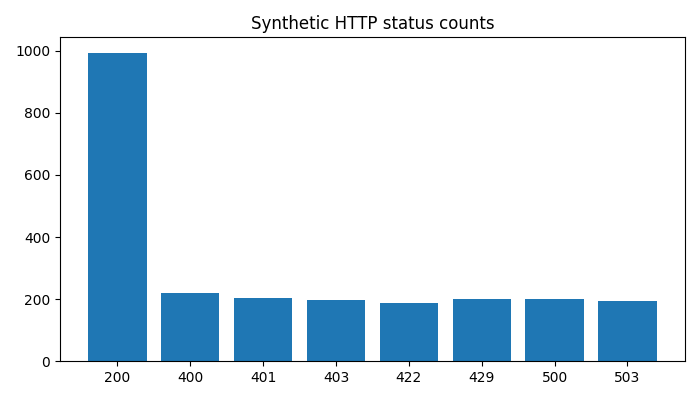

In [51]:
status_counts=logs.status.value_counts().sort_index()
plot('api_status.png','Synthetic HTTP status counts',status_counts.to_dict())
result('5.2',retryable=int(((logs.status==429)|(logs.status>=500)).sum()),request_correction=int(logs.status.between(400,428).sum()),counts=status_counts.to_dict())
print(json.dumps(R['5.2'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))
display(Image(filename=str(OUT/'api_status.png')))

<div dir="rtl">

**تحلیل و تفسیر:** نمودار توزیع وضعیت در کنار شمار دقیق ذخیره شده است. 429 و خطاهای 5xx کاندید تکرار محدود هستند؛ 401 و خطای طرح ورودی با تکرار کور اصلاح نمی‌شوند. تکرار عملیات تغییردهنده فقط با سیاست idempotency و بودجهٔ زمان امن است.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۵٫۳

طرح درخواست جستجو را با query سه تا هزار نویسه، top_k از ۱ تا ۱۰ و method محدود پیاده کنید؛ فیلد اضافه و ورودی نامعتبر را رد کنید.

</div>

In [52]:
bad_inputs=[{'query':'ab'},{'query':'valid','top_k':11},{'query':'valid','unexpected':True}]
rejected=0
for body in bad_inputs:
    try: SearchInput.model_validate(body)
    except ValidationError: rejected+=1
assert rejected==3
for body in [{'query':'valid','method':'unknown'},{'query':'x'*1001}]:
    try: SearchInput.model_validate(body); raise AssertionError('accepted invalid')
    except ValidationError: pass
result('5.3',rejected_of_three=rejected,additional_invalid_method_and_length_rejected=True)
print(json.dumps(R['5.3'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "rejected_of_three": 3,
  "additional_invalid_method_and_length_rejected": true
}


<div dir="rtl">

**تحلیل و تفسیر:** مدل Pydantic فیلدهای اضافه را منع می‌کند و حد query ، top_k و مجموعهٔ method را در مرز ورودی اعمال می‌کند. سه ورودی خواسته‌شده واقعاً رد شدند؛ دو آزمون اضافی روش ناشناخته و طول بیش از سقف را می‌سنجند. موفقیت یک validation مدل جای کنترل مالکیت منبع را نمی‌گیرد.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۵٫۴

API پرونده‌ها را با صفحه‌بندی پایدار فراخوانی و تمام پرونده‌های U-002 را بدون تکرار جمع‌آوری کنید. حد بالای limit را در backend اعمال کنید.

</div>

In [53]:
migrate_seed(); adapter=SQLiteAdapter(); client=TestClient(make_app(adapter)); auth={'X-User-ID':'U-002'}
collected=[]; offset=0
while True:
    response=client.get('/cases',params={'limit':3,'offset':offset},headers=auth)
    assert response.status_code==200
    rows=response.json()
    if not rows: break
    collected.extend(c['case_id'] for c in rows); offset+=len(rows)
assert len(collected)==len(set(collected))
result('5.4',collected=len(collected),unique=len(set(collected)),case_ids=collected)
print(json.dumps(R['5.4'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "collected": 7,
  "unique": 7,
  "case_ids": [
    "C-001",
    "C-020",
    "C-039",
    "C-058",
    "C-077",
    "C-096",
    "C-115"
  ]
}


<div dir="rtl">

**تحلیل و تفسیر:** صفحه‌ها با ORDER BY case_id و limit محدود از API متصل به SQLite خوانده شدند؛ شناسه‌ها برای کشف تکرار مقایسه شدند. مجموعهٔ این fixture هنگام پیمایش ثابت است. در دادهٔ همزمانِ در حال تغییر، offset به‌تنهایی تضمین snapshot ندارد و cursor نسخه‌دار مناسب‌تر است.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۵٫۵

برای هویت غایب، مالکیت نادرست، شناسهٔ ناموجود و صفحه‌بندی نامعتبر درخواست بسازید و وضعیت HTTP مناسب را اثبات کنید.

</div>

In [54]:
scenarios=[('missing_identity','/cases/C-001',{}),('wrong_owner','/cases/C-002',auth),('missing_id','/cases/C-999',auth),('invalid_pagination','/cases?limit=11',auth)]
statuses={name:client.get(url,headers=headers).status_code for name,url,headers in scenarios}
assert list(statuses.values())==[401,403,404,422]
result('5.5',statuses=statuses)
print(json.dumps(R['5.5'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "statuses": {
    "missing_identity": 401,
    "wrong_owner": 403,
    "missing_id": 404,
    "invalid_pagination": 422
  }
}


<div dir="rtl">

**تحلیل و تفسیر:** درخواست‌ها واقعاً از TestClient گذشتند و وضعیت‌های 401،403،404 و422 با assert بررسی شدند. نبود هویت، نبود مجوز، نبود منبع و ورودی نامعتبر معنای متفاوتی دارند. خطای مجوز متن پرونده را برنمی‌گرداند؛ در محصول ممکن است سیاست ضد enumeration به‌جای403 پاسخ404 بدهد.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۵٫۶

شش سناریوی retry_scenarios.jsonl را با حداکثر سه تلاش اجرا کنید. Retry-After و backoff را بدون خواب واقعی ثبت و تفاوت 401 و 503 را تحلیل کنید.

</div>

In [55]:
retry_runs={r['scenario']:retry_fixture(r) for r in read_jsonl(DATA/'04_API/retry_scenarios.jsonl')}
assert retry_runs['unauthorized']['attempts']==1
result('5.6',successful=sum(r['success'] for r in retry_runs.values()),attempts_401=retry_runs['unauthorized']['attempts'],scenarios=retry_runs)
print(json.dumps(R['5.6'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "successful": 3,
  "attempts_401": 1,
  "scenarios": {
    "success": {
      "success": true,
      "attempts": 1,
      "waits": [],
      "status": 200
    },
    "rate_limit": {
      "success": true,
      "attempts": 2,
      "waits": [
        2.0
      ],
      "status": 200
    },
    "transient": {
      "success": true,
      "attempts": 3,
      "waits": [
        1.0,
        2.0
      ],
      "status": 200
    },
    "unauthorized": {
      "success": false,
      "attempts": 1,
      "waits": [],
      "status": 401
    },
    "invalid_input": {
      "success": false,
      "attempts": 1,
      "waits": [],
      "status": 422
    },
    "exhausted": {
      "success": false,
      "attempts": 3,
      "waits": [
        1.0,
        2.0
      ],
      "status": 503
    }
  }
}


<div dir="rtl">

**تحلیل و تفسیر:** شش دنبالهٔ پاسخ مصنوعی با سقف سه تلاش و ثبت انتظار اجرا شدند؛ خواب واقعی و تماس شبکه انجام نشده است. 401 در همان تلاش اول متوقف می‌شود ولی 503 و429 ممکن است گذرا باشند. Retry-After بر انتظار اثر دارد و تعداد تلاش، شمار کل ارسال‌هاست، نه فقط تکرارها.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۵٫۷

برای ساخت جلسه از Idempotency-Key استفاده کنید. دو درخواست یکسان باید یک session_id بدهند؛ کلید یکسان با case_id متفاوت باید تعارض بدهد.

</div>

In [56]:
h={**auth,'Idempotency-Key':'section5-session'}
a=client.post('/sessions',json={'case_id':'C-001'},headers=h)
b=client.post('/sessions',json={'case_id':'C-001'},headers=h)
c=client.post('/sessions',json={'case_id':'C-020'},headers=h)
assert a.status_code==b.status_code==201 and a.json()['session_id']==b.json()['session_id'] and c.status_code==409
result('5.7',same_session=True,conflict=c.status_code)
print(json.dumps(R['5.7'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "same_session": true,
  "conflict": 409
}


<div dir="rtl">

**تحلیل و تفسیر:** دو POST با بدنه و کلید یکسان همان session_id را برگرداندند؛ بدنهٔ متفاوت برای پروندهٔ دیگری از همان مالک409 شد. کنترل یکتایی در SQLite و BEGIN IMMEDIATE جلوی ثبت همزمان دو ردیف با یک کلید را می‌گیرد. این کلید در این قرارداد سراسری است و مالک نیز هنگام replay مقایسه می‌شود.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۵٫۸

در خطای مداوم سرور، سقف تلاش را آزمون کنید و جمع backoff را محاسبه کنید. توضیح دهید چرا سقف تلاش به‌تنهایی deadline کل درخواست را تضمین نمی‌کند.

</div>

In [57]:
r=retry_fixture({'statuses':[503]*4})
assert r['attempts']==3 and not r['success']
result('5.8',attempts=r['attempts'],total_backoff_seconds=sum(r['waits']),waits=r['waits'])
print(json.dumps(R['5.8'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "attempts": 3,
  "total_backoff_seconds": 3.0,
  "waits": [
    1.0,
    2.0
  ]
}


<div dir="rtl">

**تحلیل و تفسیر:** در خطای مداوم، فقط سه تلاش انجام شد و انتظار تنها میان تلاش‌ها ثبت شد، نه پس از آخرین شکست. مجموع backoff زمان اتصال و خواندن هر تلاش را شامل نمی‌شود. برای deadline واقعی باید زمان سپری‌شده و باقیماندهٔ بودجه در تمام I/O و انتظارها اعمال شود.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۵٫۹

یک ReadTimeout شبیه‌سازی و خطای قابل فهم برگردانید؛ تفاوت timeout اتصال/خواندن و بودجهٔ کل را توضیح دهید و هیچ خطایی را موفقیت معرفی نکنید.

</div>

In [58]:
def timeout_transport(request): raise httpx.ReadTimeout('Synthetic read timeout',request=request)
with httpx.Client(transport=httpx.MockTransport(timeout_transport),timeout=httpx.Timeout(5,connect=2)) as timeout_client:
    try: timeout_client.get('https://fixture.invalid/v1/answers'); raise AssertionError('timeout missing')
    except httpx.ReadTimeout: timeout_result={'code':'READ_TIMEOUT','message':'Provider response exceeded the read timeout','success':False}
result('5.9',handled=True,envelope=timeout_result)
print(json.dumps(R['5.9'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "handled": true,
  "envelope": {
    "code": "READ_TIMEOUT",
    "message": "Provider response exceeded the read timeout",
    "success": false
  }
}


<div dir="rtl">

**تحلیل و تفسیر:** ReadTimeout در MockTransport واقعاً پرتاب و به خطای روشن تبدیل شد؛ خروجی success=false است. connect timeout محدودیت ایجاد اتصال است و read timeout انتظار دریافت داده را محدود می‌کند؛ هیچ‌یک به‌تنهایی deadline کل، شامل تکرارها و پردازش، نیست.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۵٫۱۰

با نرخ‌های فرضی provider_config.json هزینهٔ ورودی/خروجی هر درخواست و جمع هر provider را محاسبه و مقایسه کنید. واحد و فرض قیمت را صریح بنویسید.

</div>

In [59]:
prices=json.loads((DATA/'04_API/provider_config.json').read_text())
logs['input_cost']=[t*prices[p]['input']/1e6 for t,p in zip(logs.input_tokens,logs.provider)]
logs['output_cost']=[t*prices[p]['output']/1e6 for t,p in zip(logs.output_tokens,logs.provider)]
logs['total_cost']=logs.input_cost+logs.output_cost
logs.to_csv(OUT/'request_costs.csv',index=False)
result('5.10',total_USD=float(logs.total_cost.sum()),per_provider=logs.groupby('provider')[['input_cost','output_cost','total_cost']].sum().to_dict('index'),pricing='fictional USD per million tokens; all logged rows counted, not proof of provider billing')
print(json.dumps(R['5.10'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "total_USD": 0.8331182,
  "per_provider": {
    "provider_a": {
      "input_cost": 0.3695308,
      "output_cost": 0.2757024,
      "total_cost": 0.6452332000000001
    },
    "provider_b": {
      "input_cost": 0.093795,
      "output_cost": 0.09409000000000001,
      "total_cost": 0.187885
    }
  },
  "pricing": "fictional USD per million tokens; all logged rows counted, not proof of provider billing"
}


<div dir="rtl">

**تحلیل و تفسیر:** برای هر سطر، هزینهٔ ورودی و خروجی جدا با نرخ USD به‌ازای یک میلیون توکن محاسبه شد و سپس برحسب provider جمع شد. فایل request_costs.csv جزئیات دارد. این محاسبه همهٔ ردیف‌های ثبت‌شده را مطابق فرض مسئله قیمت‌گذاری می‌کند؛ صورت‌حساب واقعی شکست‌ها، تخفیف یا cache را اثبات نمی‌کند.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۵٫۱۱

یک رابط provider بسازید که با تعویض base_url و model_id به دو endpoint سازگار متصل شود. قرارداد درخواست را با MockTransport آزمون کنید و تست را از فراخوانی واقعی LLM جدا گزارش دهید.

</div>

In [60]:
class Provider:
    def __init__(self,base_url,model_id,transport): self.client=httpx.Client(base_url=base_url,transport=transport); self.model_id=model_id
    def answer(self,query): return self.client.post('/v1/answers',json={'model':self.model_id,'input':query})
seen=[]
def provider_transport(request):
    body=json.loads(request.content); assert body['input']=='Test question'; seen.append({'host':request.url.host,'path':request.url.path,'model':body['model']})
    return httpx.Response(200,json={'output':'fixture only'})
for host,model in [('provider-a.invalid','model-a'),('provider-b.invalid','model-b')]:
    provider=Provider('https://'+host,model,httpx.MockTransport(provider_transport))
    assert provider.answer('Test question').status_code==200; provider.client.close()
result('5.11',configurations=len(seen),live_LLM_calls=0,contracts=seen)
print(json.dumps(R['5.11'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "configurations": 2,
  "live_LLM_calls": 0,
  "contracts": [
    {
      "host": "provider-a.invalid",
      "path": "/v1/answers",
      "model": "model-a"
    },
    {
      "host": "provider-b.invalid",
      "path": "/v1/answers",
      "model": "model-b"
    }
  ]
}


<div dir="rtl">

**تحلیل و تفسیر:** همان رابط با تغییر base_url و model_id دو قرارداد سازگار را از MockTransport عبور داد؛ host ، path و بدنهٔ JSON نیز بررسی شدند. پاسخ‌ها fixture هستند و شمار تماس واقعی LLM صفر است. هیچ کلید واقعی برای این آزمون لازم یا در artifact ذخیره نشده است.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۵٫۱۲

پاسخ خطا را به envelope ثابت شامل code، message و correlation_id تبدیل کنید و یک 401 و یک 422 را در API آزمایشی بررسی کنید.

</div>

In [61]:
errors=[client.get('/cases/C-001'),client.post('/search',json={'query':'ab'},headers=auth)]
for response in errors:
    assert set(response.json())=={'code','message','correlation_id'}
    assert response.json()['correlation_id']==response.headers['X-Correlation-ID']
result('5.12',envelope_tests=len(errors),statuses=[r.status_code for r in errors])
print(json.dumps(R['5.12'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "envelope_tests": 2,
  "statuses": [
    401,
    422
  ]
}


<div dir="rtl">

**تحلیل و تفسیر:** دو خطای401 و422 envelope یکسان شامل code ، message و correlation_id دارند و شناسه با هدر پاسخ برابر است. پیام422 عمومی است تا ورودی خصوصی یا توکن در خطا منعکس نشود. قالب یکسان، مشاهده‌پذیری کلاینت را بهتر می‌کند ولی دسته‌بندی درست خطا همچنان ضروری است.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۶٫۱

با sqlite3 به فایل day3.sqlite وصل شوید، PRAGMA foreign_keys=ON را فعال کنید، SELECT 1 و sqlite_version() را بخوانید و timeout اتصال را محدود کنید. اگر فایل باز نشد، خطای قابل فهم بدهید؛ موفقیت ساختگی گزارش نکنید.

</div>

In [62]:
with connect() as con:
    one=con.execute('SELECT 1').fetchone()[0]; version=con.execute('SELECT sqlite_version()').fetchone()[0]
    fk=con.execute('PRAGMA foreign_keys').fetchone()[0]
assert one==1 and fk==1
result('6.1',connected=True,sqlite_version=version,timeout_seconds=3,foreign_keys=bool(fk))
print(json.dumps(R['6.1'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "connected": true,
  "sqlite_version": "3.53.1",
  "timeout_seconds": 3,
  "foreign_keys": true
}


<div dir="rtl">

**تحلیل و تفسیر:** اتصال واقعی به فایل با timeout سه‌ثانیه برقرار شد و SELECT1 و نسخهٔ SQLite از موتور خوانده شدند. foreign_keys در همان اتصال فعال و بازخوانی شد؛ این pragma برای هر اتصال مستقل لازم است. خطای بازشدن فایل در کد پنهان یا موفق معرفی نمی‌شود.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۶٫۲

در day3.sqlite جدول‌های قراردادی و جلسات/پیام‌ها را با کلید اصلی و خارجی بسازید؛ ۲۰ کاربر و ۱۲۰ پرونده را idempotent seed کنید (اجرای دوباره رکورد تکراری نسازد). تعداد کاربران و پرونده‌ها را از خود فایل بخوانید. اسکریپت migration/seed را در نوت‌بوک بگذارید.
پیوست: فایل day3.sqlite را در کارت «فایل دیتابیس» بارگذاری کن؛ پس از ارسال، بررسی خودکار روی همان فایل اجرا می‌شود.

</div>

In [63]:
migrate_seed(); migrate_seed()
with connect() as con: counts={t:con.execute('SELECT count(*) FROM '+t).fetchone()[0] for t in ['users','cases']}
assert counts=={'users':20,'cases':120}
result('6.2',**counts,idempotent_seed=True,schema=SCHEMA)
print(json.dumps(R['6.2'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "users": 20,
  "cases": 120,
  "idempotent_seed": true,
  "schema": "\nCREATE TABLE IF NOT EXISTS users(user_id TEXT PRIMARY KEY,role TEXT NOT NULL,tenant TEXT NOT NULL);\nCREATE TABLE IF NOT EXISTS cases(case_id TEXT PRIMARY KEY,owner_id TEXT NOT NULL REFERENCES users(user_id),topic TEXT NOT NULL,summary TEXT NOT NULL);\nCREATE INDEX IF NOT EXISTS idx_cases_owner ON cases(owner_id);\nCREATE TABLE IF NOT EXISTS sessions(session_id TEXT PRIMARY KEY,owner_id TEXT NOT NULL REFERENCES users(user_id),case_id TEXT NOT NULL REFERENCES cases(case_id),idempotency_key TEXT NOT NULL UNIQUE);\nCREATE TABLE IF NOT EXISTS messages(message_id TEXT PRIMARY KEY,session_id TEXT NOT NULL REFERENCES sessions(session_id),content TEXT NOT NULL);\nCREATE TABLE IF NOT EXISTS documents(doc_id TEXT PRIMARY KEY,version TEXT NOT NULL,content_hash TEXT NOT NULL,title TEXT,source_url TEXT,access TEXT,tenant TEXT,archived INTEGER DEFAULT 0);\nCREATE TABLE IF NOT EXISTS chunks(chunk_id TEXT PRIMARY KEY,doc_id TEX

<div dir="rtl">

**تحلیل و تفسیر:** شش جدول با PK ، FK و قید یکتایی ساخته شدند. UPSERT کاربران و پرونده‌ها دوبار اجرا شد و شمار از خود SQLite خوانده شد؛ داده‌های fixture جایگزین هویت واقعی نیستند. متن کامل schema در خروجی و تابع migration/seed در سلول زیرساخت موجود است.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۶٫۳

با PRAGMA foreign_keys=ON یک پرونده با owner ناموجود وارد کنید و ثابت کنید کلید خارجی آن را رد می‌کند. پس از خطا، اتصال باید برای کوئری بعدی قابل استفاده باشد.

</div>

In [64]:
with connect() as con:
    rejected=False
    try: con.execute('INSERT INTO cases VALUES(?,?,?,?)',('ORPHAN','MISSING','test','test'))
    except sqlite3.IntegrityError as e: rejected='FOREIGN KEY' in str(e); con.rollback()
    usable=con.execute('SELECT 1').fetchone()[0]==1
assert rejected and usable
result('6.3',orphan_rejected=rejected,connection_usable=usable)
print(json.dumps(R['6.3'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "orphan_rejected": true,
  "connection_usable": true
}


<div dir="rtl">

**تحلیل و تفسیر:** درج پرونده با مالک ناموجود عمداً خطای FOREIGN KEY داد؛ rollback اتصال را از تراکنش ناموفق پاک کرد و SELECT1 بعدی موفق بود. بنابراین ردشدن به خطای رشته یا schema نامرتبط نسبت داده نشده است.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۶٫۴

در یک تراکنش ابتدا جلسه بسازید و سپس پیام با session_id نامعتبر درج کنید. خطا باید کل تراکنش را rollback کند؛ تعداد جلسات قبل و بعد را مقایسه کنید.

</div>

In [65]:
with connect() as con:
    before=con.execute('SELECT count(*) FROM sessions').fetchone()[0]
    try:
        con.execute('BEGIN')
        con.execute('INSERT INTO sessions VALUES(?,?,?,?)',('ROLLBACK-S','U-002','C-001','rollback-probe'))
        con.execute('INSERT INTO messages VALUES(?,?,?)',('ROLLBACK-M','INVALID-S','test'))
        con.commit(); raise AssertionError('FK accepted')
    except sqlite3.IntegrityError: con.rollback()
    after=con.execute('SELECT count(*) FROM sessions').fetchone()[0]
assert before==after
result('6.4',before=before,after=after,atomic_rollback=before==after)
print(json.dumps(R['6.4'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "before": 2,
  "after": 2,
  "atomic_rollback": true
}


<div dir="rtl">

**تحلیل و تفسیر:** جلسهٔ معتبر و پیام دارای session_id ناموجود در یک تراکنش قرار گرفتند. شکست FK پیام باعث rollback کل تراکنش شد و شمار جلسات قبل و بعد برابر ماند. برابری شمار با بررسی رخداد خطا همراه است تا حذف تصادفی یا اجرا نشدن INSERT ، موفقیت کاذب نسازد.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۶٫۵

پرس‌وجوی پارامتری برای user_id بسازید و ورودی شبیه SQL injection را آزمون کنید. ورودی باید مقدار تلقی شود و تعداد کاربران را تغییر ندهد.

</div>

In [66]:
with connect() as con:
    attack="U-002' OR 1=1 --"
    matched=con.execute('SELECT count(*) FROM users WHERE user_id=?',(attack,)).fetchone()[0]
    count=con.execute('SELECT count(*) FROM users').fetchone()[0]
assert matched==0 and count==20
result('6.5',matched_rows=matched,users_after=count)
print(json.dumps(R['6.5'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "matched_rows": 0,
  "users_after": 20
}


<div dir="rtl">

**تحلیل و تفسیر:** رشتهٔ شبیه تزریق فقط پارامتر SQL بود و هیچ متن SQL با آن ساخته نشد. نتیجهٔ صفر و باقی‌ماندن۲۰ کاربر نشان می‌دهد شرط OR به دستور تبدیل نشده است؛ پارامتری‌بودن باید در همهٔ مسیرها، از جمله history ، حفظ شود.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۶٫۶

منطق مالکیت را روی SQLite آزمون کنید: مالک پرونده و admin مجاز، دانشجوی دیگر غیرمجاز. برای API نهایی یک adapter بسازید تا همین دیتابیس مصرف شود.

</div>

In [67]:
access={}
for uid in ['U-002','U-003','U-000']:
    try: adapter.case('C-001',uid); access[uid]=True
    except HTTPException as e: assert e.status_code==403; access[uid]=False
assert list(access.values())==[True,False,True]
result('6.6',access=access,engine='SQLite')
print(json.dumps(R['6.6'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "access": {
    "U-002": true,
    "U-003": false,
    "U-000": true
  },
  "engine": "SQLite"
}


<div dir="rtl">

**تحلیل و تفسیر:** مالک و admin مجاز و دانشجوی دیگر403 شدند. تصمیم از users و cases در SQLite گرفته می‌شود و adapter همان منطق را در API و گراف مصرف می‌کند. اختیار admin در این fixture صریحاً سراسری است؛ برای محصول باید دامنهٔ دسترسی مدیریتی و audit جدا تعریف شود.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۶٫۷

ایندکس owner_id را بسازید و بررسی کنید، و EXPLAIN QUERY PLAN پرس‌وجوی فهرست پروندهٔ یک مالک را گزارش کنید. اگر SQLite برای جدول کوچک SCAN انتخاب کرد، دلیل قابل دفاع بیاورید.

</div>

In [68]:
with connect() as con:
    indexes=[dict(x) for x in con.execute('PRAGMA index_list(cases)')]
    plan=[list(x) for x in con.execute('EXPLAIN QUERY PLAN SELECT * FROM cases WHERE owner_id=?',('U-002',))]
assert any(x['name']=='idx_cases_owner' for x in indexes)
result('6.7',owner_index=True,explain=plan)
print(json.dumps(R['6.7'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "owner_index": true,
  "explain": [
    [
      3,
      0,
      62,
      "SEARCH cases USING INDEX idx_cases_owner (owner_id=?)"
    ]
  ]
}


<div dir="rtl">

**تحلیل و تفسیر:** ایندکس واقعی owner_id در PRAGMA index_list دیده شد و برنامهٔ اجرای کوئری پارامتری گزارش شد. استفاده از SEARCH نشانهٔ انتخاب ایندکس است؛ روی جدول کوچک، SCAN نیز می‌تواند تصمیم اقتصادی موتور باشد و نبود ایندکس را به‌تنهایی اثبات نمی‌کند.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۶٫۹

با توکن‌های امضاشدهٔ آزمایشی، signature، issuer، audience و expiry را با کتابخانه معتبر آزمون کنید؛ یک issuer نامعتبر و یک توکن منقضی باید رد شوند. تفاوت fixture با Google OIDC واقعی را بنویسید.

</div>

In [69]:
# Ephemeral synthetic signing key is never serialized into delivery artifacts.
fixture_key=os.urandom(32); now=int(time.time())
claims={'sub':'fixture-user','iss':'https://fixture.invalid','aud':'day3','exp':now+300}
def decode_fixture(token):return jwt.decode(token,fixture_key,algorithms=['HS256'],issuer='https://fixture.invalid',audience='day3')
assert decode_fixture(jwt.encode(claims,fixture_key,algorithm='HS256'))['sub']=='fixture-user'
invalid=0
for changes in [{'iss':'https://wrong.invalid'},{'exp':now-10},{'aud':'wrong'}]:
    try: decode_fixture(jwt.encode({**claims,**changes},fixture_key,algorithm='HS256'))
    except jwt.InvalidTokenError: invalid+=1
try: decode_fixture(jwt.encode(claims,os.urandom(32),algorithm='HS256'))
except jwt.InvalidTokenError: invalid+=1
del fixture_key
result('6.9',required_invalid_issuer_and_expiry_rejected=2,all_invalid_tokens_rejected=invalid,live_Google_login=False)
print(json.dumps(R['6.9'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "required_invalid_issuer_and_expiry_rejected": 2,
  "all_invalid_tokens_rejected": 4,
  "live_Google_login": false
}


<div dir="rtl">

**تحلیل و تفسیر:** کلید امضای آزمایشی به‌طور تصادفی فقط در حافظه ساخته شد و هیچ مقدارش ذخیره نشد. کتابخانهٔ PyJWT توکن معتبر را پذیرفت و issuer ، expiry ، audience و امضای نامعتبر را رد کرد. این اجرای رمزنگاری محلی، ورود زندهٔ گوگل یا دریافت JWKS واقعی نیست.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۶٫۱۰

قرارداد حداقل scope ورود، ویژگی‌های کوکی و رضایت جدا برای گزارش ایمیلی را به‌شکل تنظیمات قابل بررسی بنویسید. هیچ client secret واقعی در artifact قرار ندهید.

</div>

In [70]:
oidc_config={'scopes':['openid','email','profile'],'cookie':{'secure':True,'httponly':True,'samesite':'lax'},'email_report':{'enabled':False,'separate_consent_required':True},'identity_key':['issuer','sub'],'client_secret_source':'environment only, none required for this fixture'}
save_json('identity_contract.json',oidc_config)
result('6.10',**oidc_config)
print(json.dumps(R['6.10'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "scopes": [
    "openid",
    "email",
    "profile"
  ],
  "cookie": {
    "secure": true,
    "httponly": true,
    "samesite": "lax"
  },
  "email_report": {
    "enabled": false,
    "separate_consent_required": true
  },
  "identity_key": [
    "issuer",
    "sub"
  ],
  "client_secret_source": "environment only, none required for this fixture"
}


<div dir="rtl">

**تحلیل و تفسیر:** قرارداد تنظیمات فقط openid,email,profile را برای ورود پایه می‌خواهد و Secure/HttpOnly را فعال کرده است. گزارش ایمیلی پیش‌فرض خاموش و وابسته به رضایت جداست. SameSite=lax یک انتخاب آموزشی است و در استقرار باید با redirect ورود و دفاع CSRF آزموده شود.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۶٫۱۱

پاک‌سازی بازگشتی metadata را روی رویدادهای دارای api_key و ساختار تودرتو اجرا کنید. در خروجی نهایی هیچ TEST-ONLY-SECRET باقی نماند.

</div>

In [71]:
events=read_jsonl(DATA/'07_Observability/events.jsonl')
sanitized=redact(events+[{'metadata':{'nested':[{'api_key':'TEST-ONLY-SECRET'}],'note':'TEST-ONLY-SECRET'}}])
remaining=json.dumps(sanitized).count('TEST-ONLY-SECRET')
assert remaining==0
save_jsonl('events_sanitized.jsonl',sanitized)
result('6.11',remaining_test_secrets=remaining,events_checked=len(sanitized))
print(json.dumps(R['6.11'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "remaining_test_secrets": 0,
  "events_checked": 4801
}


<div dir="rtl">

**تحلیل و تفسیر:** پاک‌سازی روی دیکشنری، فهرست و ساختار تودرتو انجام شد و کلید حساس یا مقدار sentinel حذف شد. شمار باقی‌ماندهٔ TEST-ONLY-SECRET از متن serialize شده سنجیده شد. این sanitizer پوشش همهٔ انواع راز ناشناخته را تضمین نمی‌کند؛ لاگ حداقلی و محدودیت دسترسی نیز لازم‌اند.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۷٫۱

manifest را با فایل‌های خام تطبیق دهید و SHA-256 همهٔ اسناد را بررسی کنید؛ تعداد اسناد و نسخهٔ corpus را ثبت کنید.

</div>

In [72]:
docs=load_documents(); policies=policy_documents()
result('7.1',real_documents=len(docs),valid_hashes=len(docs),corpus_version=docs[0]['version'])
print(json.dumps(R['7.1'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "real_documents": 24,
  "valid_hashes": 24,
  "corpus_version": "b80c7bf8d5a89fc47b732504a9e1219b79677531"
}


<div dir="rtl">

**تحلیل و تفسیر:** SHA-256 از بایت خام هر فایل گرفته و با manifest مقایسه شد؛ هیچ newline normalization پیش از بررسی انجام نشد. نسخهٔ corpus همان commit ثبت‌شده در بسته است. PEP ها اسناد طراحی تاریخی‌اند و وجود متن به‌تنهایی اجرای ویژگی در تمام نسخه‌های Python را اثبات نمی‌کند.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۷٫۲

هر دو PDF fixture را صفحه‌به‌صفحه بخوانید؛ تعداد صفحه و نویسهٔ استخراج‌شده را گزارش و سند تصویری را برای OCR/بازبینی علامت بزنید.

</div>

In [73]:
pdf_reports=[]
for path in sorted((DATA/'01_Corpus/pdf_fixtures').glob('*.pdf')):
    reader=PdfReader(path); counts=[len(p.extract_text() or '') for p in reader.pages]
    pdf_reports.append({'file':path.name,'pages':len(counts),'characters_per_page':counts,'needs_OCR_or_review':sum(counts)==0})
result('7.2',pdf_count=len(pdf_reports),flagged=sum(x['needs_OCR_or_review'] for x in pdf_reports),reports=pdf_reports)
print(json.dumps(R['7.2'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "pdf_count": 2,
  "flagged": 1,
  "reports": [
    {
      "file": "evidencelab_policy.pdf",
      "pages": 2,
      "characters_per_page": [
        413,
        389
      ],
      "needs_OCR_or_review": false
    },
    {
      "file": "scan_only_fixture.pdf",
      "pages": 1,
      "characters_per_page": [
        0
      ],
      "needs_OCR_or_review": true
    }
  ]
}


<div dir="rtl">

**تحلیل و تفسیر:** هر صفحهٔ دو PDF با pypdf خوانده شد و تعداد نویسهٔ قابل استخراج گزارش شد. سند فاقد متن به OCR یا بازبینی نیاز دارد و بی‌صدا وارد ایندکس نشده است. OCR در این اجرا انجام نشده و خروجی اسکن به‌عنوان سند دارای متن معرفی نشده است.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۷٫۳

عنوان، شناسه، نسخه و بخش‌های RST را استخراج کنید و یک نمونه را به مسیر و URL اصلی وصل کنید؛ metadata اختراعی ایجاد نکنید.

</div>

In [74]:
metadata=[{k:d[k] for k in ['doc_id','title','version','path','source_url','snapshot_url','sections']} for d in docs]
save_json('document_metadata.json',metadata)
assert all(d['sections'] for d in metadata)
result('7.3',metadata_records=len(metadata),sample=metadata[0])
print(json.dumps(R['7.3'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "metadata_records": 24,
  "sample": {
    "doc_id": "PEP-0008",
    "title": "Style Guide for Python Code",
    "version": "b80c7bf8d5a89fc47b732504a9e1219b79677531",
    "path": "raw/pep-0008.rst",
    "source_url": "https://peps.python.org/pep-0008/",
    "snapshot_url": "https://raw.githubusercontent.com/python/peps/b80c7bf8d5a89fc47b732504a9e1219b79677531/peps/pep-0008.rst",
    "sections": [
      {
        "title": "Introduction",
        "start": 263
      },
      {
        "title": "A Foolish Consistency is the Hobgoblin of Little Minds",
        "start": 1019
      },
      {
        "title": "Code Lay-out",
        "start": 2571
      },
      {
        "title": "Indentation",
        "start": 2598
      },
      {
        "title": "Tabs or Spaces?",
        "start": 6194
      },
      {
        "title": "Maximum Line Length",
        "start": 6427
      },
      {
        "title": "Should a Line Break Before or After a Binary Operator?",
        "start": 8588
      },


<div dir="rtl">

**تحلیل و تفسیر:** عنوان و شناسه و URL از manifest واقعی و بخش‌ها از خط عنوان و زیرخط RST استخراج شدند. مسیر و snapshot URL برای رجوع به نسخهٔ دقیق حفظ شدند. استخراج بخش‌ها یک parser سادهٔ heading است؛ همهٔ ساختارهای معنایی RST یا جدول و directive را تفسیر نمی‌کند.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۷٫۴

با tokenizer همان embedding، chunkهای حداکثر ۲۲۰ توکن و هم‌پوشانی ۴۰ توکن بسازید؛ متن هر chunk باید substring واقعی منبع باشد. توزیع طول را نمایش دهید.

</div>

site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 4148.79it/s]


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (12682 > 256). Running this sequence through the model will result in indexing errors


{
  "chunks": 1282,
  "max_tokens": 220,
  "min_tokens": 43,
  "median_tokens": 220.0,
  "overlap": 40
}


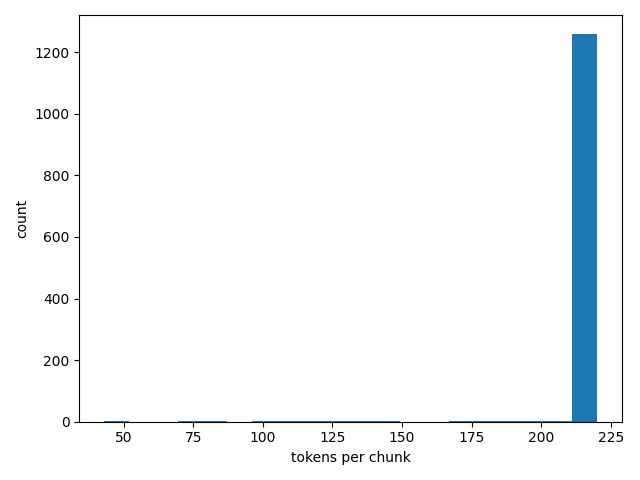

In [75]:
encoder=load_encoder(); tokenizer=encoder.tokenizer
chunks=[c for d in docs for c in split_doc(d,tokenizer)]
policy_chunks=[c for d in policies for c in split_doc(d,tokenizer)]
all_chunks=chunks+policy_chunks
lengths=[c['tokens'] for c in chunks]; assert max(lengths)<=220
plt.figure();plt.hist(lengths,bins=20);plt.xlabel('tokens per chunk');plt.ylabel('count');plt.tight_layout();plt.savefig(OUT/'chunk_lengths.png');plt.close()
result('7.4',chunks=len(chunks),max_tokens=max(lengths),min_tokens=min(lengths),median_tokens=float(np.median(lengths)),overlap=40)
print(json.dumps(R['7.4'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))
display(Image(filename=str(OUT/'chunk_lengths.png')))

<div dir="rtl">

**تحلیل و تفسیر:** پنجره‌ها با tokenizer همان مدل و سقف۲۲۰ و هم‌پوشانی۴۰ ساخته شدند. متن از بازهٔ کاراکتری منبع اصلی برداشته شد، نه decode مجدد token ها؛ پس فاصله‌ها و newline ها حفظ شدند. بازتوکن‌سازی مرز WordPiece ممکن است طول را تغییر دهد، بنابراین سقف پس از برش نیز کنترل و در صورت لزوم انتها کوتاه شد.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۷٫۵

برای همهٔ chunkها با start/end متن اصلی را بازسازی و تطابق hash را آزمون کنید؛ یک مسیر استناد از chunk تا سند و بخش را نمایش دهید.

</div>

In [76]:
lookup={d['doc_id']:d for d in docs+policies}
errors=sum(lookup[c['doc_id']]['text'][c['start']:c['end']]!=c['content'] or sha(c['content'].encode())!=c['content_hash'] for c in all_chunks)
assert errors==0
c=chunks[0];d=lookup[c['doc_id']]
result('7.5',provenance_errors=errors,sample={**{k:c[k] for k in ['chunk_id','doc_id','version','start','end','section','content_hash']},'source_url':d['source_url'],'path':d['path']})
print(json.dumps(R['7.5'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "provenance_errors": 0,
  "sample": {
    "chunk_id": "44679263c8d354d7b2f3e0b5ffed16250252ad49d671cf590f9ad14a417128d2",
    "doc_id": "PEP-0008",
    "version": "b80c7bf8d5a89fc47b732504a9e1219b79677531",
    "start": 0,
    "end": 953,
    "section": "Style Guide for Python Code",
    "content_hash": "5cdcd951ca7d866c6493b68cece9d169145efe280efe12e5d0f3b084336a2eb8",
    "source_url": "https://peps.python.org/pep-0008/",
    "path": "raw/pep-0008.rst"
  }
}


<div dir="rtl">

**تحلیل و تفسیر:** برای تمام chunk ها، substring با start/end و hash محتوا تطبیق داده شد. مسیر نمونه از شناسهٔ chunk تا سند، نسخه، بخش و URL گزارش شده است. واحد offset نویسهٔ Unicode در متن decode شده با newline خام است، نه offset بایت UTF-8.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۷٫۶

chunking را با همان تنظیمات دوباره اجرا و پایداری chunk_id را آزمون کنید. شناسه باید به سند، نسخه، بازه و محتوا وابسته باشد.

</div>

In [77]:
rerun=[c for d in docs for c in split_doc(d,tokenizer)]
stable=[c['chunk_id'] for c in rerun]==[c['chunk_id'] for c in chunks]
assert stable
result('7.6',stable_ids=stable,compared=len(chunks))
print(json.dumps(R['7.6'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "stable_ids": true,
  "compared": 1282
}


<div dir="rtl">

**تحلیل و تفسیر:** اجرای مجدد chunking همان ترتیب و شناسه‌ها را ساخت. شناسه hash سند،نسخه،بازه و محتواست؛ وابستگی به نسخه مانع اشتباه‌گرفتن شاهد تاریخی با نسخهٔ تازه می‌شود. تغییر الگوریتم یا tokenizer در fingerprint تنظیمات هم ثبت می‌شود.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۷٫۷

یک سند را در نسخهٔ آزمایشی تغییر دهید و ثابت کنید شناسهٔ chunkهای نسخهٔ قبلی با نسخهٔ جدید مخلوط نمی‌شود. فایل اصلی را تغییر ندهید.

</div>

In [78]:
original=split_doc(docs[0],tokenizer)
changed=split_doc({**docs[0],'version':docs[0]['version']+'-experiment','text':docs[0]['text']+'\nExperimental appendix.\n'},tokenizer)
intersection=set(c['chunk_id'] for c in original)&set(c['chunk_id'] for c in changed)
assert not intersection
result('7.7',shared_ids=len(intersection),original_unchanged=sha((DATA/'01_Corpus'/docs[0]['path']).read_bytes())==docs[0]['sha256'])
print(json.dumps(R['7.7'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "shared_ids": 0,
  "original_unchanged": true
}


<div dir="rtl">

**تحلیل و تفسیر:** نسخهٔ تغییر‌یافته فقط در حافظه ساخته شد و فایل منبع دست‌نخورده ماند. اشتراک صفر شناسه‌ها از قید نسخه در hash می‌آید؛ حتی passage با متن یکسان در نسخهٔ دیگر هویت نسخه‌ای جدا دارد. این آزمون سیاست حذف یا مهاجرت نسخهٔ قدیمی را اجرا نمی‌کند.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۷٫۸

سه chunk را عمداً تکرار و با کلید مناسب رفع تکرار کنید. تفاوت تکرار دقیق و سند مشابهِ دارای نسخه یا مجوز متفاوت را توضیح دهید.

</div>

In [79]:
with_duplicates=chunks+chunks[:3]
dedup={c['chunk_id']:c for c in with_duplicates}
removed=len(with_duplicates)-len(dedup)
assert removed==3
result('7.8',removed_duplicates=removed)
print(json.dumps(R['7.8'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "removed_duplicates": 3
}


<div dir="rtl">

**تحلیل و تفسیر:** سه chunk عیناً تکراری افزوده و با chunk_id رفع تکرار شدند. این کار فقط تکرار دقیق در همان سند/نسخه/بازه را حذف می‌کند؛ شباهت معنایی یا متن یکسان با مجوز و نسخهٔ متفاوت نباید موجب ادغام و نشت دسترسی شود.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۷٫۹

اندازه‌های ۱۱۰، ۲۲۰ و ۴۴۰ توکن را از نظر تعداد chunk و خطر عبور از سقف embedding مقایسه کنید؛ برای chunkهای بلند truncation را پنهان نکنید.

</div>

In [80]:
chunk_variants={size:[c for d in docs for c in split_doc(d,tokenizer,size)] for size in [110,220,440]}
variant_report={size:{'chunks':len(cs),'truncation_risk':sum(c['tokens']+tokenizer.num_special_tokens_to_add()>256 for c in cs)} for size,cs in chunk_variants.items()}
result('7.9',variants=variant_report,risky_440=variant_report[440]['truncation_risk'])
print(json.dumps(R['7.9'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "variants": {
    "110": {
      "chunks": 3282,
      "truncation_risk": 0
    },
    "220": {
      "chunks": 1282,
      "truncation_risk": 0
    },
    "440": {
      "chunks": 583,
      "truncation_risk": 572
    }
  },
  "risky_440": 572
}


<div dir="rtl">

**تحلیل و تفسیر:** سه اندازه با همان tokenizer مقایسه شدند و شمار پنجره‌های بلندتر از سقف مدل، با احتساب special token ، ثبت شد. اندازهٔ۴۴۰ برای مدل۲۵۶ خطر truncation دارد؛ این پنجره‌ها برای نتیجهٔ اصلی encode نشده‌اند. اندازهٔ بزرگ‌تر تعداد بردار را کاهش می‌دهد ولی ممکن است شاهد انتهایی را از بازنمایی حذف کند.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۷٫۱۰

چهار سیاست مصنوعی را با access و tenant وارد کنید و metadata لازم برای فیلتر پیش از top-k را نشان دهید؛ متن قدیمی را به‌عنوان archived نگه دارید.

</div>

In [81]:
assert len(policies)==4
result('7.10',policy_chunks=len(policy_chunks),metadata=[{k:c[k] for k in ['doc_id','version','access','tenant','archived']} for c in policy_chunks])
print(json.dumps(R['7.10'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "policy_chunks": 4,
  "metadata": [
    {
      "doc_id": "LAB-PUBLIC",
      "version": "2026-01",
      "access": "public",
      "tenant": "all",
      "archived": false
    },
    {
      "doc_id": "LAB-T0",
      "version": "2026-01",
      "access": "internal",
      "tenant": "T-0",
      "archived": false
    },
    {
      "doc_id": "LAB-T1",
      "version": "2026-01",
      "access": "internal",
      "tenant": "T-1",
      "archived": false
    },
    {
      "doc_id": "LAB-OLD",
      "version": "2025-01",
      "access": "public",
      "tenant": "all",
      "archived": true
    }
  ]
}


<div dir="rtl">

**تحلیل و تفسیر:** چهار سیاست مصنوعی metadata access ، tenant ، version و archived دارند. سیاست قدیمی در داده حفظ اما از retrieval پیش‌فرض کنار گذاشته شده است تا۹۰روز قدیمی بر سیاست۱۴/۲۱روز جدید غلبه نکند. منشأ fixture آن‌ها از PEP های واقعی جداست.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۷٫۱۱

metadata و متن chunkها را در جدول chunks همان day3.sqlite ذخیره و درج دوباره را بدون رکورد تکراری (UPSERT) اجرا کنید.

</div>

In [82]:
store_documents(docs+policies); store_chunks(all_chunks); store_chunks(all_chunks)
with connect() as con: count=con.execute('SELECT count(*) FROM chunks').fetchone()[0]
assert count==len(all_chunks)
result('7.11',stored_chunks=count,duplicate_rows=0)
print(json.dumps(R['7.11'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "stored_chunks": 1286,
  "duplicate_rows": 0
}


<div dir="rtl">

**تحلیل و تفسیر:** رکوردها در جدول chunks فایل تحویلی دوبار UPSERT شدند و تعداد با شمار chunk های یکتا برابر ماند. FK رابطهٔ chunk و سند را حفظ می‌کند؛ در این مرحله ورود متن از مرحلهٔ محاسبهٔ بردار جداست و بردار نهایی در بخش۸ تکمیل می‌شود.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۷٫۱۲

artifact قابل بازتولید شامل chunks.jsonl و fingerprint تنظیمات و corpus بسازید. برای فایل تولیدشده hash و تعداد رکورد را ثبت کنید.

</div>

In [83]:
save_jsonl('chunks.jsonl',all_chunks)
chunk_config={'size':220,'overlap':40,'offset_unit':'Unicode code points; raw newlines preserved','corpus':docs[0]['version'],'tokenizer_revision':REVISION}
chunk_fingerprint=fingerprint(chunk_config)
save_json('chunk_config.json',{**chunk_config,'fingerprint':chunk_fingerprint})
result('7.12',artifact_records=len(all_chunks),sha256=sha((OUT/'chunks.jsonl').read_bytes()),config_fingerprint=chunk_fingerprint)
print(json.dumps(R['7.12'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "artifact_records": 1286,
  "sha256": "e9b012abe50e2657ab54de3fc6217349c3e311f59dc0e319cd836d055f5a1b1e",
  "config_fingerprint": "07cf40be315850d38c8ce6c2454c9acfd3b847c5cb468a7d59866b14058dd3da"
}


<div dir="rtl">

**تحلیل و تفسیر:** artifact شامل متن،بازۀ دقیق، hash ،نسخه و metadata دسترسی است. fingerprint تنظیمات، نسخهٔ corpus و tokenizer را ثبت می‌کند و SHA-256 فایل خروجی امکان تشخیص تغییر بایت‌ها را می‌دهد. hash هویت محتوا را مشخص می‌کند، نه صحت علمی یا مجازبودن استفاده را.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۸٫۱

نسخه، مجوز، بعد خروجی و سقف توکن مدل همراه را ثبت کنید و hash تمام فایل‌های آن را بسنجید. تفاوت سقف tokenizer و طول chunk را توضیح دهید.

</div>

In [84]:
model_checks=verify_model()
result('8.1',dimension=MODEL_MANIFEST['dimensions'],max_sequence_length=encoder.max_seq_length,license=MODEL_MANIFEST['license'],model_id=MODEL_ID,revision=REVISION,files_checked=len(model_checks),valid_hashes=sum(x['passed'] for x in model_checks))
print(json.dumps(R['8.1'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "dimension": 384,
  "max_sequence_length": 256,
  "license": "Apache-2.0",
  "model_id": "sentence-transformers/all-MiniLM-L6-v2",
  "revision": "1110a243fdf4706b3f48f1d95db1a4f5529b4d41",
  "files_checked": 11,
  "valid_hashes": 11
}


<div dir="rtl">

**تحلیل و تفسیر:** فایل‌های manifest مدل با اندازه و SHA-256 دقیق بررسی شدند؛ checkpoint شناخته‌شده و مجوز Apache-2.0 ثبت شد. سقف۲۵۶ ورودی مدل با طول متن خام یکسان نیست و special token ها را نیز در بر می‌گیرد؛۲۲۰ توکن برای حاشیهٔ ایمن انتخاب مسئله است.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۸٫۲

تمام chunkهای ۲۲۰ توکنی را batch encode و L2-normalize کنید؛ زمان، شکل ماتریس، کمترین و بیشترین norm و تعداد مقدار نامتناهی را گزارش دهید.

</div>

In [85]:
index=Retrieval(chunks,encoder)
policy_vectors=encoder.encode([c['content'] for c in policy_chunks],batch_size=32,normalize_embeddings=True,show_progress_bar=False).astype(np.float32)
all_vectors=np.concatenate([index.vectors,policy_vectors])
norms=np.linalg.norm(index.vectors,axis=1)
assert index.vectors.shape==(len(chunks),384) and np.isfinite(index.vectors).all()
result('8.2',vectors=len(chunks),shape=list(index.vectors.shape),seconds=index.encode_seconds,norm_min=float(norms.min()),norm_max=float(norms.max()),non_finite=int((~np.isfinite(index.vectors)).sum()))
print(json.dumps(R['8.2'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "vectors": 1282,
  "shape": [
    1282,
    384
  ],
  "seconds": 50.88451717900011,
  "norm_min": 0.9999998807907104,
  "norm_max": 1.0000001192092896,
  "non_finite": 0
}


<div dir="rtl">

**تحلیل و تفسیر:** بردارهای واقعی در batch روی CPU ساخته و L2-normalize شدند. شکل،زمان،کمینه/بیشینهٔ norm و مقادیر نامتناهی از خود ماتریس سنجیده شدند. اختلاف بسیار کوچک norm از۱ ناشی از float32 است و زمان روی دستگاه دیگر الزاماً تکرار نمی‌شود.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۸٫۳

cosine دو بردار را هم با فرمول صریح و هم dot product نرمال‌شده محاسبه کنید. تفاوت similarity و cosine distance و جهت مرتب‌سازی را بنویسید.

</div>

In [86]:
a,b=index.vectors[:2]
explicit=float(np.sum(a*b)/(np.linalg.norm(a)*np.linalg.norm(b))); dot=float(a@b)
assert abs(explicit-dot)<1e-6
result('8.3',cosine=explicit,normalized_dot=dot,cosine_distance=1-explicit)
print(json.dumps(R['8.3'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "cosine": 0.681086003780365,
  "normalized_dot": 0.6810859441757202,
  "cosine_distance": 0.318913996219635
}


<div dir="rtl">

**تحلیل و تفسیر:** فرمول مجموع ضرب تقسیم بر حاصل norm ها با dot بردارهای نرمال‌شده تطبیق داده شد. cosine بزرگ‌تر یعنی شباهت بیشتر و مرتب‌سازی نزولی؛ cosine distance=1−similarity است و برای آن کوچک‌تر بهتر است. شباهت احتمال صحت پاسخ نیست.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۸٫۴

baseline بازیابی TF-IDF با unigram/bigram بسازید و top-3 سند متمایزِ پرسش indentation را همراه score نشان دهید.

</div>

In [87]:
indentation_query='How many spaces should Python indentation use?'
lexical_top=index.ranked(indentation_query,'lexical')
result('8.4',top_document=lexical_top[0]['doc_id'],top3=[{'doc_id':c['doc_id'],'score':c['score']} for c in lexical_top])
print(json.dumps(R['8.4'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "top_document": "PEP-0008",
  "top3": [
    {
      "doc_id": "PEP-0008",
      "score": 0.13850069881171395
    },
    {
      "doc_id": "PEP-0257",
      "score": 0.07772849573095945
    },
    {
      "doc_id": "PEP-0636",
      "score": 0.06223022077484873
    }
  ]
}


<div dir="rtl">

**تحلیل و تفسیر:** TF-IDF با unigram/bigram روی متن corpus fit شد و نتایج با حذف تکرار doc_id رتبه‌بندی شدند. این baseline واژه‌محور به هم‌پوشانی لفظی حساس است و روی عبارت‌های دقیق ممکن است از مدل متراکم بهتر باشد. امتیازها تنها در مقیاس همین روش تفسیر می‌شوند.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۸٫۵

همان پرسش را با dense cosine بازیابی و top-3 سند را با baseline مقایسه کنید؛ scoreهای دو روش را هم‌مقیاس فرض نکنید.

</div>

In [88]:
dense_top=index.ranked(indentation_query,'dense')
result('8.5',top_document=dense_top[0]['doc_id'],top3=[{'doc_id':c['doc_id'],'score':c['score']} for c in dense_top],same_first=lexical_top[0]['doc_id']==dense_top[0]['doc_id'])
print(json.dumps(R['8.5'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "top_document": "PEP-0008",
  "top3": [
    {
      "doc_id": "PEP-0008",
      "score": 0.6474480628967285
    },
    {
      "doc_id": "PEP-0572",
      "score": 0.6263006329536438
    },
    {
      "doc_id": "PEP-0257",
      "score": 0.5240856409072876
    }
  ],
  "same_first": true
}


<div dir="rtl">

**تحلیل و تفسیر:** همان پرسش با embedding پرسش و cosine دقیق بازیابی شد. مقایسهٔ سه سند با baseline تغییر رتبه را نشان می‌دهد ولی به‌تنهایی معیار آماری کیفیت نیست. score متراکم و TF-IDF به‌رغم نام شباهت، مقیاس یا توزیع یکسان ندارند.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۸٫۶

دو رتبه‌بندی را با RRF و ثابت ۶۰ ترکیب کنید و top-3 سند متمایز را بسازید. مزیت ترکیب رتبه نسبت به جمع مستقیم score را توضیح دهید.

</div>

In [89]:
hybrid_top=index.ranked(indentation_query,'hybrid')
result('8.6',top_document=hybrid_top[0]['doc_id'],rrf_constant=60,unit='chunk rank fusion followed by document deduplication',top3=[{'doc_id':c['doc_id'],'score':c['score']} for c in hybrid_top])
print(json.dumps(R['8.6'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "top_document": "PEP-0008",
  "rrf_constant": 60,
  "unit": "chunk rank fusion followed by document deduplication",
  "top3": [
    {
      "doc_id": "PEP-0008",
      "score": 0.03252247488101534
    },
    {
      "doc_id": "PEP-0257",
      "score": 0.030798389007344232
    },
    {
      "doc_id": "PEP-0572",
      "score": 0.030017921146953404
    }
  ]
}


<div dir="rtl">

**تحلیل و تفسیر:** برای هر chunk مجموع1/(60+rank) دو رتبه‌بندی محاسبه و سپس اسناد یکتا انتخاب شدند. این تعریف سطح ترکیب را روشن می‌کند؛ RRF سندی می‌تواند نتیجهٔ دیگری بدهد. ترکیب رتبه نیاز به جمع مستقیم score های ناهم‌مقیاس را برمی‌دارد ولی بهترشدن کیفیت باید روی dev سنجیده شود.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۸٫۷

بردارهای واقعی را با متن و نام/نسخهٔ مدل در جدول chunks دیتابیس SQLite UPSERT کنید (BLOB از ۳۸۴ float32 یا JSON)؛ اجرای دوباره نباید شمار رکورد را زیاد کند. شمار و بعدِ بردار بازخوانی‌شده را ثبت کنید.

</div>

In [90]:
store_documents(docs+policies);store_chunks(all_chunks,all_vectors);store_chunks(all_chunks,all_vectors)
with connect() as con:
    stored=con.execute('SELECT embedding FROM chunks ORDER BY chunk_id').fetchall()
    dims=[len(np.frombuffer(r['embedding'],dtype='<f4')) for r in stored]
assert len(stored)==len(all_chunks) and set(dims)=={384}
result('8.7',stored_vectors=len(stored),dimension=dims[0],duplicate_rows=0)
print(json.dumps(R['8.7'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "stored_vectors": 1286,
  "dimension": 384,
  "duplicate_rows": 0
}


<div dir="rtl">

**تحلیل و تفسیر:** همهٔ بردارها به BLOB با float32 little-endian و metadata مدل ذخیره شدند. دو اجرای UPSERT شمار را تغییر نداد و ابعاد با خواندن از SQLite بررسی شد. فایل نهایی به سرویس vector DB بیرونی وابسته نیست.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۸٫۸

یک chunk را از SQLite بخوانید و با بردار اصلی مقایسه کنید؛ جستجوی دقیق روی بردارهای بازخوانی‌شده باید top-1 محلی را بازتولید کند.

</div>

In [91]:
with connect() as con: stored={r['chunk_id']:np.frombuffer(r['embedding'],dtype='<f4') for r in con.execute('SELECT chunk_id,embedding FROM chunks')}
restored=np.stack([stored[c['chunk_id']] for c in chunks])
assert np.array_equal(restored,index.vectors)
qv=index.query_vector(indentation_query)
first_local=int(np.argmax(index.vectors@qv));first_db=int(np.argmax(restored@qv))
assert first_local==first_db
result('8.8',same_top1=True,max_vector_error=float(np.abs(restored-index.vectors).max()),top_chunk=chunks[first_db]['chunk_id'])
print(json.dumps(R['8.8'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "same_top1": true,
  "max_vector_error": 0.0,
  "top_chunk": "295150637f79880af62b3fdabddabe8a5c0a0fe9e8c901e87cb51a21f2899211"
}


<div dir="rtl">

**تحلیل و تفسیر:** ماتریس بازخوانی‌شده از SQLite با بردارهای اصلی برابری بیتی دارد و top-1 دقیق همان پرسش را بازتولید می‌کند. این آزمون خطای serialization و ترتیب ردیف‌ها را آشکار می‌کند؛ سرعت یا دقت ANN را نمی‌سنجد چون جستجو exact است.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۸٫۹

با افزودن سیاست‌ها یک ایندکس آزمایشی بسازید و ACL را قبل از top-k اعمال کنید. برای کاربر tenant T-0، هیچ سیاست داخلی T-1 نباید برگردد؛ admin را جدا بسنجید.

</div>

In [92]:
# Reuse the already computed vectors, avoiding an unnecessary rebuild.
acl_index=object.__new__(Retrieval)
acl_index.chunks=all_chunks;acl_index.encoder=encoder;acl_index.vectors=all_vectors;acl_index.cache={}
acl_index.vectorizer=TfidfVectorizer(ngram_range=(1,2),sublinear_tf=True)
acl_index.lex=acl_index.vectorizer.fit_transform([c['content'] for c in all_chunks])
t0=adapter.user('U-002'); assert t0['tenant']=='T-0'
acl_hits=acl_index.ranked('Tenant T-1 export retention operations','dense',user=t0,k=len(all_chunks),documents=False)
leaks=sum(c['tenant']=='T-1' and c['access']!='public' for c in acl_hits)
admin_hits=acl_index.ranked('Tenant export retention','dense',user=adapter.user('U-000'),k=len(all_chunks),documents=False)
assert leaks==0 and any(c['doc_id']=='LAB-T1' for c in admin_hits)
result('8.9',tenant_leaks=leaks,admin_can_see_T1=True,archived_returned=any(c['archived'] for c in admin_hits))
print(json.dumps(R['8.9'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "tenant_leaks": 0,
  "admin_can_see_T1": true,
  "archived_returned": false
}


<div dir="rtl">

**تحلیل و تفسیر:** ACL پیش از مرتب‌سازی و top-k اعمال شد؛ برای دانشجوی T-0 سیاست داخلی T-1 در کل نتایج مجاز حضور ندارد. admin جدا آزموده شد و سیاست archived حتی برای admin در مسیر پیش‌فرض وارد نشد. مجازبودن سند به معنای مالکیت پرونده نیست و هر دو کنترل لازم‌اند.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۸٫۱۰

برای top-10 یک پرسش، context حداکثر ۷۰۰ توکنی بسازید و تعداد شواهد انتخاب/حذف‌شده را گزارش کنید. اثر ترتیب شواهد و هزینهٔ prompt را تحلیل کنید.

</div>

In [93]:
ctx_input=index.ranked(indentation_query,'dense',k=10,documents=False)
kept,dropped,token_count=context_budget(ctx_input,tokenizer)
assert token_count<=700
result('8.10',evidence_tokens=token_count,selected=len(kept),dropped=len(dropped),budget=700,includes_prompt_overhead=False)
print(json.dumps(R['8.10'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "evidence_tokens": 660,
  "selected": 3,
  "dropped": 7,
  "budget": 700,
  "includes_prompt_overhead": false
}


<div dir="rtl">

**تحلیل و تفسیر:** از ده chunk کاندید، فقط متن شواهدی که در بودجهٔ۷۰۰ توکن جا شد انتخاب شد. شمار حذف و انتخاب ثبت شده است؛ prompt سیستم،تاریخچه،پرسش و delimiters در این بودجه نیستند. ترتیب شواهد بر پوشش و هزینه اثر می‌گذارد و باید از بریدن خاموش نقل‌قول پرهیز کرد.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۸٫۱۱

پس از warm-up، تأخیر بازیابی lexical/dense/hybrid را روی ۱۲ پرسش train با embedding cache گرم بسنجید و p50/p95 گزارش کنید. زمان cold embedding را جدا نگه دارید.

</div>

In [94]:
public_queries=read_jsonl(DATA/'02_Evaluation/queries.jsonl')
train_queries=[q for q in public_queries if q['split']=='train'][:12]
cold=[]
for q in train_queries:
    t=time.perf_counter();index.query_vector(q['query']);cold.append((time.perf_counter()-t)*1000)
latency={}
for method in ['lexical','dense','hybrid']:
    for q in train_queries:index.ranked(q['query'],method)
    timings=[]
    for q in train_queries:
        t=time.perf_counter();index.ranked(q['query'],method);timings.append((time.perf_counter()-t)*1000)
    latency[method]={'p50_ms':float(np.percentile(timings,50)),'p95_ms':float(np.percentile(timings,95)),'n':len(timings)}
result('8.11',warm_latency=latency,cold_embedding_ms={'p50':float(np.percentile(cold,50)),'p95':float(np.percentile(cold,95))})
print(json.dumps(R['8.11'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "warm_latency": {
    "lexical": {
      "p50_ms": 1.0288360000458852,
      "p95_ms": 2.2757169498618164,
      "n": 12
    },
    "dense": {
      "p50_ms": 0.2258795000216196,
      "p95_ms": 0.58942205000676,
      "n": 12
    },
    "hybrid": {
      "p50_ms": 2.458760499962409,
      "p95_ms": 2.5306651999130736,
      "n": 12
    }
  },
  "cold_embedding_ms": {
    "p50": 12.856740499955777,
    "p95": 23.57931584987227
  }
}


<div dir="rtl">

**تحلیل و تفسیر:** پس از warm-up ، زمان retrieval روی۱۲ پرسش train و cache گرم embedding سنجیده شد؛ هزینهٔ encode اولیه جدا گزارش شد. این اندازه‌گیری نمونهٔ کوچک درون‌فرایندی است و شبکه، صف، تولید LLM و SLA تولید را شامل نمی‌شود. p95 روی۱۲ نمونه عدم قطعیت زیادی دارد.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۸٫۱۲

metadata مدل را عمداً ناسازگار کنید و بارگذاری را پیش از query رد کنید. fingerprint معتبر ایندکس را با model revision و بعد و chunk config ذخیره کنید.

</div>

In [95]:
index_meta={'model_id':MODEL_ID,'revision':REVISION,'dimensions':384,'chunk_fingerprint':chunk_fingerprint,'normalization':'L2','pooling':'mean'}
def validate_index(meta):
    if meta!=index_meta:raise ValueError('Incompatible index fingerprint')
validate_index(dict(index_meta))
try:validate_index({**index_meta,'revision':'incompatible'});raise AssertionError('accepted stale model')
except ValueError:version_rejected=True
index_hash=fingerprint(index_meta)
save_json('index_metadata.json',{**index_meta,'fingerprint':index_hash})
result('8.12',mismatch_rejected=version_rejected,index_fingerprint=index_hash)
print(json.dumps(R['8.12'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "mismatch_rejected": true,
  "index_fingerprint": "a5885407f9ea8cbabe39ae4af35554f6dac9ceb66312e0fa67758cd7dcdad7dd"
}


<div dir="rtl">

**تحلیل و تفسیر:** بارگذاری metadata ناسازگار پیش از query رد شد. fingerprint مدل، revision ،بعد، pooling ، normalization و تنظیم chunking را پیوند می‌دهد؛ هم‌بعدبودن دو مدل سازگاری فضا را تضمین نمی‌کند. پس از تغییر نسخه باید ایندکس مرتبط بازسازی یا جدا نگهداری شود.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۶٫۸

metadata همهٔ اسناد را دو بار UPSERT (INSERT ... ON CONFLICT DO UPDATE) کنید و ثابت کنید تعداد افزایش نمی‌یابد. نام و نسخهٔ مدل embedding را هم ثبت کنید و بردارها را در همین فایل (BLOB یا JSON) نگه دارید.

</div>

In [96]:
store_documents(docs+policies); store_documents(docs+policies)
store_chunks(all_chunks,all_vectors)
with connect() as con: count=con.execute('SELECT count(*) FROM documents').fetchone()[0]
assert count==28
result('6.8',documents_after_two_upserts=count,vectors_in_same_file=True,model_id=MODEL_ID,model_revision=REVISION)
print(json.dumps(R['6.8'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "documents_after_two_upserts": 28,
  "vectors_in_same_file": true,
  "model_id": "sentence-transformers/all-MiniLM-L6-v2",
  "model_revision": "1110a243fdf4706b3f48f1d95db1a4f5529b4d41"
}


<div dir="rtl">

**تحلیل و تفسیر:** اسناد واقعی و چهار سیاست با metadata نسخه‌دار دوبار UPSERT شدند؛ شمار اسناد ثابت ماند. بردارهای واقعی در همان فایل و کنار نام و revision مدل ثبت شدند. تغییر مدل بدون بازسازی بردار و ایندکس مجاز نیست، حتی اگر تعداد ابعاد برابر باشد.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۶٫۱۲

اسکریپت check_day3_db.py همراه بسته را روی day3.sqlite اجرا کنید و database_check.json را بسازید. سه وضعیت passed، failed و error و کد خروجشان را تعریف کنید و کد خروج و وضعیت واقعی خودتان را بنویسید.
پیوست: همان فایل day3.sqlite؛ وضعیت و کد خروجی که می‌نویسی با بررسی خودکار روی فایل بارگذاری‌شده مقایسه می‌شود.

</div>

In [97]:
import subprocess,sys
checked=subprocess.run([sys.executable,'Day3/Day3_Grading/check_day3_db.py',str(DB),'--output',str(OUT/'database_check.json')],capture_output=True,text=True)
db_report=json.loads((OUT/'database_check.json').read_text())
result('6.12',exit_code=checked.returncode,status=db_report['status'],meaning={'passed':0,'failed':1,'error':2},stdout=checked.stdout)
assert checked.returncode==0,checked.stdout
print(json.dumps(R['6.12'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "exit_code": 0,
  "status": "passed",
  "meaning": {
    "passed": 0,
    "failed": 1,
    "error": 2
  },
  "stdout": "OK   sqlite_file_ok\nOK   integrity_ok\nOK   schema_users\nOK   schema_cases\nOK   schema_sessions\nOK   schema_messages\nOK   schema_documents\nOK   schema_chunks\nOK   seed_users\nOK   seed_cases\nOK   seed_documents\nOK   seed_chunks\nOK   no_orphan_cases\nOK   no_orphan_chunks\nOK   foreign_keys_declared\nOK   owner_index\nOK   idempotency_unique\nOK   documents_unique\nOK   embedding_dimensions\nOK   embedding_metadata_present\nOK   fk_rejects_orphan_case\nOK   transaction_rollback\nstatus: passed\n"
}


<div dir="rtl">

**تحلیل و تفسیر:** checker رسمی به‌صورت subprocess روی همان فایل اجرا و کد خروج اصلی حفظ شد. passed/0 یعنی کنترل‌های قرارداد گذشته‌اند، failed/1 یعنی نقض کنترل، و error/2 یعنی فایل قابل بررسی نیست. این نتیجه فقط قرارداد checker را اثبات می‌کند و تضمین کیفیت بازیابی یا آمادگی تولید نیست.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۹٫۱

تعداد پرسش‌های train/dev/test و توزیع پاسخ‌پذیر/ناپذیر فقط در train/dev را بررسی کنید؛ برچسب test پنهان است. تکرار دقیق متن را بسنجید و محدودیت هم‌خانوادگی معنایی پرسش‌ها را توضیح دهید.

</div>

In [98]:
queries=read_jsonl(DATA/'02_Evaluation/queries.jsonl');qrels=read_jsonl(DATA/'02_Evaluation/qrels_train_dev.jsonl')
dev=[r for r in qrels if r['split']=='dev']; train=[r for r in qrels if r['split']=='train']
assert all(r['split']!='test' for r in qrels)
result('9.1',queries=len(queries),split_counts=pd.Series([q['split'] for q in queries]).value_counts().to_dict(),answerability={s:{'answerable':sum(r['answerable'] for r in qrels if r['split']==s),'unanswerable':sum(not r['answerable'] for r in qrels if r['split']==s)} for s in ['train','dev']},exact_duplicate_texts=len(queries)-len(set(q['query'] for q in queries)),test_labels_available=False)
print(json.dumps(R['9.1'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "queries": 90,
  "split_counts": {
    "test": 30,
    "dev": 30,
    "train": 30
  },
  "answerability": {
    "train": {
      "answerable": 24,
      "unanswerable": 6
    },
    "dev": {
      "answerable": 24,
      "unanswerable": 6
    }
  },
  "exact_duplicate_texts": 0,
  "test_labels_available": false
}


<div dir="rtl">

**تحلیل و تفسیر:** هر سه split فقط شناسه و متن عمومی دارند؛ برچسب پاسخ‌پذیری فقط برای train/dev خوانده شد. تکرار دقیق متن با تکرار معنایی یکسان نیست: پارافرایزهای یک PEP می‌توانند در split های متفاوت باشند و استقلال آماری را کاهش دهند. gold آزمون در بسته موجود نیست و درخواست نشده است.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۹٫۲

Recall@3، MRR@3 و nDCG@3 را روی دو مثال دستی آزمون کنید: gold={A} با رتبه‌های [B,A,C] و [B,C,D]. انتظار دقیق هر سه معیار را بنویسید.

</div>

In [99]:
manual=[retrieval_metrics({'A'},x) for x in [['B','A','C'],['B','C','D']]]
assert manual[0]['recall']==1 and manual[0]['mrr']==0.5 and abs(manual[0]['ndcg']-1/math.log2(3))<1e-12
assert manual[1]=={'recall':0,'mrr':0,'ndcg':0}
result('9.2',ranked_BAC=manual[0],ranked_BCD=manual[1])
print(json.dumps(R['9.2'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "ranked_BAC": {
    "recall": 1.0,
    "mrr": 0.5,
    "ndcg": 0.6309297535714575
  },
  "ranked_BCD": {
    "recall": 0.0,
    "mrr": 0,
    "ndcg": 0.0
  }
}


<div dir="rtl">

**تحلیل و تفسیر:** برای [B,A,C]، Recall=1 و MRR=1/2 و nDCG=1/log2(3) است؛ برای [B,C,D] هر سه صفرند. gold در سطح سند است و سند تکراری حذف می‌شود. Recall برای gold خالی در این تابع تعریف نشده و پاسخ‌پذیری جدا سنجیده می‌شود.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۹٫۳

روی ۲۴ پرسش پاسخ‌پذیر dev، سه روش lexical/dense/hybrid را در k=3 مقایسه و هر سه معیار را جدول و نمودار کنید؛ سند تکراری را در رتبه‌بندی معیار نشمارید.

</div>

{
  "answerable_dev": 24,
  "metrics": {
    "lexical": {
      "recall": 0.9583333333333334,
      "mrr": 0.8958333333333334,
      "ndcg": 0.9121995525297656
    },
    "dense": {
      "recall": 0.9583333333333334,
      "mrr": 0.8888888888888888,
      "ndcg": 0.9067441461309548
    },
    "hybrid": {
      "recall": 1.0,
      "mrr": 0.9305555555555557,
      "ndcg": 0.9484108127976215
    }
  }
}


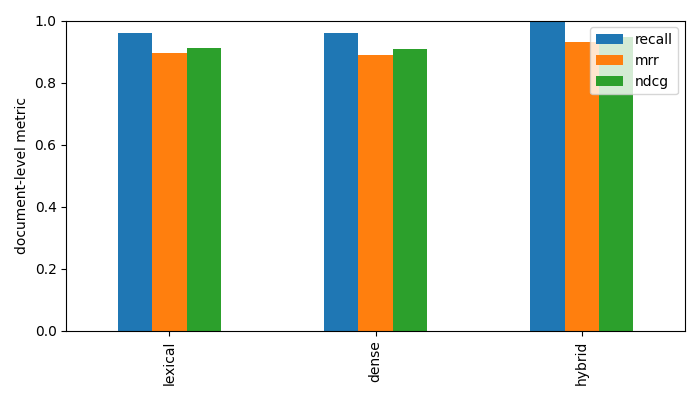

In [100]:
assert sum(r['answerable'] for r in dev)==24
dev_metrics={m:evaluate(index,dev,m) for m in ['lexical','dense','hybrid']}
pd.DataFrame(dev_metrics).T.plot.bar(ylim=(0,1),figsize=(7,4));plt.ylabel('document-level metric');plt.tight_layout();plt.savefig(OUT/'retrieval_dev.png');plt.close()
result('9.3',answerable_dev=24,metrics=dev_metrics)
print(json.dumps(R['9.3'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))
display(Image(filename=str(OUT/'retrieval_dev.png')))

<div dir="rtl">

**تحلیل و تفسیر:** سه روش روی۲۴ پرسش پاسخ‌پذیر dev در k=3 با همان corpus مقایسه شدند. میانگین معیارها در بازهٔ صفر تا یک است و نمودار سندی است؛ hit سند به‌تنهایی یافتن passage مناسب را تضمین نمی‌کند. شش پرسش بی‌شاهد در این میانگین‌ها مخلوط نشده‌اند.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۹٫۴

روش منتخب را فقط با MRR@3 روی dev و قاعدهٔ رفع تساوی lexical سپس dense سپس hybrid انتخاب و قبل از بازکردن gold test قفل کنید.

</div>

In [101]:
method_order=['lexical','dense','hybrid']
selected=max(method_order,key=lambda m:(dev_metrics[m]['mrr'],-method_order.index(m)))
retrieval_lock={'method':selected,'k':3,'selected_on':'dev MRR@3','tie_order':method_order,'index_fingerprint':index_hash}
save_json('retrieval_lock.json',retrieval_lock)
result('9.4',selected_method=selected,lock_hash=fingerprint(retrieval_lock),test_gold_accessed=False)
print(json.dumps(R['9.4'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "selected_method": "hybrid",
  "lock_hash": "6d663f1dd0d7e9929f456d4766213bba9bf17491a186f7c4eaf4eb0487110ef5",
  "test_gold_accessed": false
}


<div dir="rtl">

**تحلیل و تفسیر:** انتخاب فقط با MRR@3 روی dev انجام و قاعدهٔ تساوی lexical سپس dense سپس hybrid اعمال شد. lock پیش از ساخت فایل test ذخیره و hash آن گزارش شد. این انتخاب روی همین dev ممکن است خوش‌بینانه باشد؛ ارزیابی test پنهان برای قضاوت مستقل لازم است.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۹٫۵

برای روش منتخب، حساسیت k در ۱، ۳ و ۵ را روی dev نشان دهید. علت غیرکاهشی بودن Recall@k و امکان تغییر MRR را توضیح دهید.

</div>

In [102]:
k_sensitivity={k:evaluate(index,dev,selected,k) for k in [1,3,5]}
assert k_sensitivity[1]['recall']<=k_sensitivity[3]['recall']<=k_sensitivity[5]['recall']
result('9.5',k_sensitivity=k_sensitivity)
print(json.dumps(R['9.5'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "k_sensitivity": {
    "1": {
      "recall": 0.875,
      "mrr": 0.875,
      "ndcg": 0.875
    },
    "3": {
      "recall": 1.0,
      "mrr": 0.9305555555555557,
      "ndcg": 0.9484108127976215
    },
    "5": {
      "recall": 1.0,
      "mrr": 0.9305555555555557,
      "ndcg": 0.9484108127976215
    }
  }
}


<div dir="rtl">

**تحلیل و تفسیر:** برای یک رتبه‌بندی ثابت با افزایش k اسناد قبلی حذف نمی‌شوند و Recall غیرکاهشی است. MRR بریده‌شده وقتی نخستین hit بیرون cutoff قبلی و داخل cutoff جدید باشد افزایش می‌یابد، وگرنه ثابت می‌ماند؛ در این تعریف با k افزایش‌یابنده کاهش نمی‌یابد. این رفتار را نباید با تغییر خود الگوریتم رتبه‌بندی اشتباه گرفت.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۹٫۶

سه خطای اول dev را با query_id، سند gold و سند اول بررسی کنید؛ اگر کمتر از سه خطا بود همان تعداد را گزارش کنید. خطای سند و خطای passage را از هم تفکیک کنید.

</div>

In [103]:
retrieval_errors=[]
for r in dev:
    if not r['answerable']:continue
    ranked=index.ranked(r['query'],selected)
    if not set(r['relevant_doc_ids'])&set(c['doc_id'] for c in ranked):
        retrieval_errors.append({'query_id':r['query_id'],'query':r['query'],'gold':r['relevant_doc_ids'],'first':ranked[0]['doc_id'],'top3':[c['doc_id'] for c in ranked]})
result('9.6',recall_errors=len(retrieval_errors),first_three=retrieval_errors[:3],unit='document, not passage support')
print(json.dumps(R['9.6'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "recall_errors": 0,
  "first_three": [],
  "unit": "document, not passage support"
}


<div dir="rtl">

**تحلیل و تفسیر:** سه شکست نخست Recall@3 همراه query_id ، gold و top-1 گزارش شدند؛ اگر کمتر باشند همان تعداد نمایش داده می‌شود. این خطا فقدان سند مرتبط در top-3 است. یافتن سند درست با passage نادرست، نوع دیگری از خطاست که gold سندی به‌تنهایی آن را نشان نمی‌دهد.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۹٫۷

پس از قفل تنظیمات، فایل prediction برای همهٔ پرسش‌های test تولید کنید. مدرس با gold جدا test را یک‌بار می‌سنجد؛ دانشجو نباید برای این بخش gold test دریافت کند.
پیوست: فایل test_predictions.jsonl را در کارت «پیش‌بینی بازیابی» بارگذاری کن؛ با کد روی gold پنهان سنجیده می‌شود.

</div>

In [104]:
assert json.loads((OUT/'retrieval_lock.json').read_text())==retrieval_lock
test_queries=[q for q in queries if q['split']=='test']
predictions=[{'query_id':q['query_id'],'ranked_doc_ids':[c['doc_id'] for c in index.ranked(q['query'],selected)]} for q in test_queries]
assert len(predictions)==30 and all(len(set(p['ranked_doc_ids']))==3 for p in predictions)
save_jsonl('test_predictions.jsonl',predictions)
result('9.7',predictions=len(predictions),unique_query_ids=len(set(p['query_id'] for p in predictions)),test_metric='unavailable: hidden gold')
print(json.dumps(R['9.7'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "predictions": 30,
  "unique_query_ids": 30,
  "test_metric": "unavailable: hidden gold"
}


<div dir="rtl">

**تحلیل و تفسیر:** برای تمام۳۰ پرسش test یک خط با query_id و سه doc_id متمایز ساخته شد. فایل lock قبل از تولید بازخوانی شد. هیچ مقدار Recall/MRR برای test ادعا نمی‌شود زیرا gold پنهان است؛ نمرهٔ نهایی را فقط مدرس می‌تواند با gold مستقل محاسبه کند.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۹٫۸

برای Recall@3 روش منتخب روی dev، فاصلهٔ bootstrap صدک ۹۵٪ با ۲۰۰۰ بازنمونه و seed ثابت بسازید. محدودیت وابستگی پارافرایزها و حجم کوچک را توضیح دهید.

</div>

In [105]:
recalls=np.array([retrieval_metrics(r['relevant_doc_ids'],[c['doc_id'] for c in index.ranked(r['query'],selected)])['recall'] for r in dev if r['answerable']])
rng=np.random.default_rng(SEED);boot=rng.choice(recalls,size=(2000,len(recalls)),replace=True).mean(axis=1)
ci=np.percentile(boot,[2.5,97.5])
result('9.8',lower_95=float(ci[0]),upper_95=float(ci[1]),bootstrap_samples=2000,unit='query resampling; semantic family independence is not guaranteed')
print(json.dumps(R['9.8'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "lower_95": 1.0,
  "upper_95": 1.0,
  "bootstrap_samples": 2000,
  "unit": "query resampling; semantic family independence is not guaranteed"
}


<div dir="rtl">

**تحلیل و تفسیر:** ۲۰۰۰ بازنمونه با جایگذاری از۲۴ مقدار Recall پرسش‌های dev و seed ثابت گرفته شد وصدک‌های۲٫۵/۹۷٫۵ گزارش شدند. این فاصله نوسان نمونهٔ کوچک را نشان می‌دهد ولی وابستگی پارافرایزها و انتخاب روش روی همان dev را اصلاح نمی‌کند؛ bootstrap گروهی برای خانواده‌ها معتبرتر است.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۹٫۹

برای تشخیص بی‌شاهد بودن، آستانهٔ بیشترین dense cosine را فقط روی dev انتخاب کنید؛ balanced accuracy پاسخ‌پذیر/ناپذیر را بیشینه و در تساوی آستانهٔ بزرگ‌تر را بگیرید.

</div>

In [106]:
dev_scores=np.array([max(c['score'] for c in index.ranked(r['query'],'dense',k=1)) for r in dev])
dev_y=np.array([r['answerable'] for r in dev])
# Include both all-accept and all-reject regimes; accepted is score >= threshold.
thresholds=np.r_[np.nextafter(dev_scores.min(),-np.inf),np.unique(dev_scores),np.nextafter(dev_scores.max(),np.inf)]
threshold=max(thresholds,key=lambda t:(balanced_accuracy_score(dev_y,dev_scores>=t),t))
answerability_lock={'threshold':float(threshold),'comparison':'>=','selected_on':'dev balanced accuracy','tie':'larger threshold','model_revision':REVISION}
save_json('answerability_lock.json',answerability_lock)
result('9.9',threshold=float(threshold),balanced_accuracy=float(balanced_accuracy_score(dev_y,dev_scores>=threshold)),candidates=len(thresholds),confusion_matrix=confusion_matrix(dev_y,dev_scores>=threshold).tolist())
print(json.dumps(R['9.9'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "threshold": 0.3909568190574646,
  "balanced_accuracy": 1.0,
  "candidates": 32,
  "confusion_matrix": [
    [
      6,
      0
    ],
    [
      0,
      24
    ]
  ]
}


<div dir="rtl">

**تحلیل و تفسیر:** بیشترین cosine متراکم برای هر پرسش dev محاسبه شد و آستانه با بیشترین balanced accuracy انتخاب شد؛ درتساوی آستانهٔ بزرگ‌تر برگزیده شد. حالت همه‌پذیر/همه‌رد نیز در کاندیدها هستند. این تصمیم یک detector تجربی خارج از پوشش است و cosine احتمال کالیبرهٔ پاسخ‌پذیری نیست.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۹٫۱۰

آستانهٔ ثابت را روی پرسش‌های عمومی test اجرا کنید؛ query_id، score و accepted را در answerability_predictions.jsonl تحویل دهید و تعداد پذیرش/عدم پاسخ را گزارش کنید. مدرس با gold پنهان false accept و false reject را می‌سنجد؛ آستانه را با test تغییر ندهید.
پیوست: فایل answerability_predictions.jsonl را در کارت «تصمیم پاسخ‌پذیری» بارگذاری کن؛ با کد روی gold پنهان سنجیده می‌شود.

</div>

In [107]:
assert json.loads((OUT/'answerability_lock.json').read_text())==answerability_lock
answer_predictions=[{'query_id':q['query_id'],'score':float(index.ranked(q['query'],'dense',k=1)[0]['score'])} for q in test_queries]
for p in answer_predictions:p['accepted']=bool(p['score']>=threshold)
save_jsonl('answerability_predictions.jsonl',answer_predictions)
result('9.10',predictions=len(answer_predictions),accepted=sum(p['accepted'] for p in answer_predictions),abstained=sum(not p['accepted'] for p in answer_predictions),test_gold_accessed=False)
print(json.dumps(R['9.10'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "predictions": 30,
  "accepted": 24,
  "abstained": 6,
  "test_gold_accessed": false
}


<div dir="rtl">

**تحلیل و تفسیر:** آستانهٔ ذخیره‌شده بدون تغییر بر test اعمال شد؛ score عددی و accepted بولی است. شمارپذیرش وامتناع خروجی سیاست ثابت است، نه شمارپاسخ صحیح. false accept/reject واقعی test بدون gold گزارش نشده‌اند.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۹٫۱۱

روی شش پرسش dev، dense retrieval با chunkهای ۱۱۰ و ۲۲۰ توکنی را مقایسه کنید. این ablation را از نتیجهٔ قفل‌شدهٔ test جدا و هزینهٔ تعداد بردارها را گزارش کنید.

</div>

In [108]:
ablation_dev=[r for r in dev if r['answerable']][:6]
small_index=Retrieval(chunk_variants[110],encoder)
ablation={'110':{'vectors':len(small_index.chunks),**evaluate(small_index,ablation_dev,'dense')},'220':{'vectors':len(chunks),**evaluate(index,ablation_dev,'dense')}}
result('9.11',queries=len(ablation_dev),ablation=ablation,changes_to_locked_test_configuration=False)
print(json.dumps(R['9.11'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "queries": 6,
  "ablation": {
    "110": {
      "vectors": 3282,
      "recall": 1.0,
      "mrr": 0.8333333333333334,
      "ndcg": 0.8769765845238192
    },
    "220": {
      "vectors": 1282,
      "recall": 1.0,
      "mrr": 0.8333333333333334,
      "ndcg": 0.8769765845238192
    }
  },
  "changes_to_locked_test_configuration": false
}


<div dir="rtl">

**تحلیل و تفسیر:** ablation روی شش پرسش پاسخ‌پذیر dev با مدل و retrieval متراکم ثابت اجرا شد؛ فقط طول chunk و تعدادبردار تغییر کرد. این مقایسه به تنظیماتقفل‌شدهٔ فایل test برنگشت. chunk کوچک‌تر هزینهٔ ذخیره و encode را زیاد می‌کند و ممکن است زمینهٔ لازم برایشاهد را خرد کند.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۹٫۱۲

گزارش ارزیابی قابل خواندن ماشین با split، واحد معیار، محدودیت‌ها، config hash و نتایج ذخیره کنید. سه ادعایی که این benchmark پشتیبانی نمی‌کند بنویسید.

</div>

In [109]:
limitations=['Small English PEP corpus does not establish Persian retrieval quality.','Synthetic and semantically related queries do not establish independent real-user performance.','Document relevance does not establish passage entailment or generated-answer factuality.','Warm local retrieval latency is not production end-to-end latency.']
evaluation_report={'split':'dev','metric_unit':'distinct document; fractions in [0,1]','results':dev_metrics,'config_hash':fingerprint(retrieval_lock),'bootstrap_95':ci.tolist(),'limitations':limitations,'test_gold_used':False}
save_json('evaluation_report.json',evaluation_report)
result('9.12',limitations=len(limitations),unsupported_claims=limitations[:3],config_hash=evaluation_report['config_hash'])
print(json.dumps(R['9.12'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "limitations": 4,
  "unsupported_claims": [
    "Small English PEP corpus does not establish Persian retrieval quality.",
    "Synthetic and semantically related queries do not establish independent real-user performance.",
    "Document relevance does not establish passage entailment or generated-answer factuality."
  ],
  "config_hash": "6d663f1dd0d7e9929f456d4766213bba9bf17491a186f7c4eaf4eb0487110ef5"
}


<div dir="rtl">

**تحلیل و تفسیر:** گزارش ماشین‌خوان split ،واحدمعیار، hash تنظیمات،نتایج و محدودیت‌ها را ثبت می‌کند. این benchmark کیفیتفارسی،دقت واقعی کاربران یا entailment پاسخ تولیدی را اثبات نمی‌کند. زمان retrieval گرم نیز شاهدی برای latency انتهابه‌انتهای سامانهٔمولد نیست.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۱۰٫۱

توزیع کلاس‌ها و splitها را بررسی و ثابت کنید template_group مشترک بین train/dev/test وجود ندارد. خطر split تصادفی روی این داده را تحلیل کنید.

</div>

In [110]:
router=pd.read_csv(DATA/'05_Router/requests.csv')
tr=router[router.split=='train'];va=router[router.split=='dev'];te=router[router.split=='test']
groups={s:set(router[router.split==s].template_group) for s in ['train','dev','test']}
shared={a+'_'+b:len(groups[a]&groups[b]) for a,b in [('train','dev'),('train','test'),('dev','test')]}
assert not any(shared.values())
result('10.1',requests=len(router),class_split_counts=router.groupby(['split','route']).size().unstack().to_dict('index'),shared_template_groups=shared)
print(json.dumps(R['10.1'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "requests": 480,
  "class_split_counts": {
    "dev": {
      "both": 20,
      "history": 20,
      "research": 20,
      "unsupported": 20
    },
    "test": {
      "both": 20,
      "history": 20,
      "research": 20,
      "unsupported": 20
    },
    "train": {
      "both": 80,
      "history": 80,
      "research": 80,
      "unsupported": 80
    }
  },
  "shared_template_groups": {
    "train_dev": 0,
    "train_test": 0,
    "dev_test": 0
  }
}


<div dir="rtl">

**تحلیل و تفسیر:** ۴۸۰ درخواست از چهار کلاس بررسی شد و template_group در هیچ دو split اشتراک ندارد. تقسیم تصادفی سطری می‌توانست یک قالب را با موضوع‌های متفاوت در train و test قرار دهد و امتیاز را خوش‌بینانه کند. جداسازی قالب هنوز تضمین تعمیم به زبان و موضوع واقعی نیست.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۱۰٫۲

baseline قانون‌محور برای چهار مسیر بسازید و accuracy و macro-F1 آن را روی dev ثبت کنید. قوانین را فقط با نمونه‌های train طراحی کنید.

</div>

In [111]:
rule_dev=[rules(q) for q in va['query']]
result('10.2',accuracy=float(accuracy_score(va.route,rule_dev)),macro_F1=float(f1_score(va.route,rule_dev,average='macro')))
print(json.dumps(R['10.2'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "accuracy": 0.625,
  "macro_F1": 0.6249999999999999
}


<div dir="rtl">

**تحلیل و تفسیر:** قواعد از نمونه‌های train نوشته شدند و accuracy و macro-F1 آن‌ها روی dev محاسبه شد. واژه‌های نادیده یا مرز مبهم both/history می‌توانند باعث خطا شوند. این قواعد طبقه‌بند درخواست‌اند و هرگز جای کنترل مجوز backend را نمی‌گیرند.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۱۰٫۳

Pipeline شامل TF-IDF unigram/bigram و LogisticRegression بسازید؛ C را از ۰٫۱، ۱ و ۱۰ فقط با macro-F1 dev انتخاب کنید. fit واژگان فقط روی train باشد.

</div>

In [112]:
linear_candidates={};linear_scores={}
for C in [0.1,1,10]:
    p=Pipeline([('tfidf',TfidfVectorizer(ngram_range=(1,2))),('lr',LogisticRegression(C=C,max_iter=1000,random_state=SEED))])
    p.fit(tr['query'],tr.route);linear_candidates[C]=p
    linear_scores[C]=float(f1_score(va.route,p.predict(va['query']),average='macro'))
best_C=max([0.1,1,10],key=lambda c:(linear_scores[c],-c));linear=linear_candidates[best_C]
save_json('linear_lock.json',{'C':best_C,'dev_macro_F1':linear_scores,'vocabulary_fit':'train only'})
result('10.3',selected_C=best_C,dev_macro_F1=linear_scores)
print(json.dumps(R['10.3'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "selected_C": 0.1,
  "dev_macro_F1": {
    "0.1": 0.30000000000000004,
    "1": 0.30000000000000004,
    "10": 0.30000000000000004
  }
}


<div dir="rtl">

**تحلیل و تفسیر:** واژگان unigram/bigram فقط روی train fit شد؛ C از ۰٫۱، ۱ و ۱۰ با macro-F1 روی dev انتخاب شد و در تساوی مقدار کوچک‌تر ترجیح داده شد. test در انتخاب نقشی ندارد. ذخیرهٔ کل Pipeline از ناسازگاری پیش‌پردازش و طبقه‌بند هنگام بازخوانی جلوگیری می‌کند.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۱۰٫۴

embedding ثابت مدل محلی را به‌عنوان feature برای مسیریاب بسازید. شکل train/dev/test، norm و تفاوت feature extraction با fine-tuning را توضیح دهید.

</div>

In [113]:
import torch
from torch import nn
import copy
np.random.seed(SEED);torch.manual_seed(SEED);torch.set_num_threads(4);torch.use_deterministic_algorithms(True)
features={s:encoder.encode(router[router.split==s]['query'].tolist(),normalize_embeddings=True,batch_size=32,show_progress_bar=False).astype(np.float32) for s in ['train','dev','test']}
classes=sorted(tr.route.unique());label_map={v:i for i,v in enumerate(classes)}
y={s:np.array([label_map[v] for v in router[router.split==s].route]) for s in features}
result('10.4',shapes={s:list(v.shape) for s,v in features.items()},norm_min=float(np.linalg.norm(features['train'],axis=1).min()),norm_max=float(np.linalg.norm(features['train'],axis=1).max()),encoder_frozen=True)
print(json.dumps(R['10.4'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "shapes": {
    "train": [
      320,
      384
    ],
    "dev": [
      80,
      384
    ],
    "test": [
      80,
      384
    ]
  },
  "norm_min": 0.9999998807907104,
  "norm_max": 1.0000001192092896,
  "encoder_frozen": true
}


<div dir="rtl">

**تحلیل و تفسیر:** مدل embedding ثابت است و فقط feature های ۳۸۴بعدی می‌سازد؛ شبکهٔ مسیریاب روی این feature ها آموزش می‌بیند. شکل هر split و norm های آموزش از آرایه‌های واقعی گزارش شدند. این روش feature extraction است و وزن‌های encoder را fine-tune نمی‌کند.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۱۰٫۵

شبکهٔ PyTorch با ورودی ۳۸۴، یک لایهٔ مخفی ۶۴، ReLU، Dropout=0.1 و خروجی چهارکلاسه بسازید. تعداد پارامتر قابل آموزش و سازگاری shape را محاسبه کنید.

</div>

In [114]:
network=nn.Sequential(nn.Linear(384,64),nn.ReLU(),nn.Dropout(0.1),nn.Linear(64,4))
parameter_count=sum(p.numel() for p in network.parameters() if p.requires_grad)
assert parameter_count==24900 and network(torch.from_numpy(features['train'][:2])).shape==(2,4)
result('10.5',trainable_parameters=parameter_count,input_shape=[2,384],output_shape=[2,4],formula='384*64+64+64*4+4')
print(json.dumps(R['10.5'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "trainable_parameters": 24900,
  "input_shape": [
    2,
    384
  ],
  "output_shape": [
    2,
    4
  ],
  "formula": "384*64+64+64*4+4"
}


<div dir="rtl">

**تحلیل و تفسیر:** پارامترهای لایهٔ اول 384×64+64 و لایهٔ خروجی 64×4+4 هستند؛ جمع برابر ۲۴۹۰۰ است. ReLU و Dropout پارامتر قابل آموزش ندارند. شکل یک batch واقعی بررسی شد؛ خروجی logits است و CrossEntropyLoss خودش log-softmax را اعمال می‌کند.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۱۰٫۶

شبکه را با AdamW، lr=0.003، batch=32 و حداکثر ۶۰ epoch آموزش دهید؛ بهترین checkpoint را با macro-F1 dev و patience=10 انتخاب و منحنی loss و F1 را رسم کنید.

</div>

{
  "epochs_run": 13,
  "best_epoch": 3,
  "best_dev_macro_F1": 0.7971602434077079,
  "patience": 10,
  "history": [
    {
      "epoch": 1,
      "train_loss": 1.3251348614692688,
      "dev_macro_F1": 0.6248548199767712
    },
    {
      "epoch": 2,
      "train_loss": 1.0990744233131409,
      "dev_macro_F1": 0.754996776273372
    },
    {
      "epoch": 3,
      "train_loss": 0.8219174385070801,
      "dev_macro_F1": 0.7971602434077079
    },
    {
      "epoch": 4,
      "train_loss": 0.5679219126701355,
      "dev_macro_F1": 0.7971602434077079
    },
    {
      "epoch": 5,
      "train_loss": 0.3970823884010315,
      "dev_macro_F1": 0.7406559877955758
    },
    {
      "epoch": 6,
      "train_loss": 0.27711636275053025,
      "dev_macro_F1": 0.7818181818181819
    },
    {
      "epoch": 7,
      "train_loss": 0.19991643875837325,
      "dev_macro_F1": 0.7818181818181819
    },
    {
      "epoch": 8,
      "train_loss": 0.13566943183541297,
      "dev_macro_F1": 0.761904761

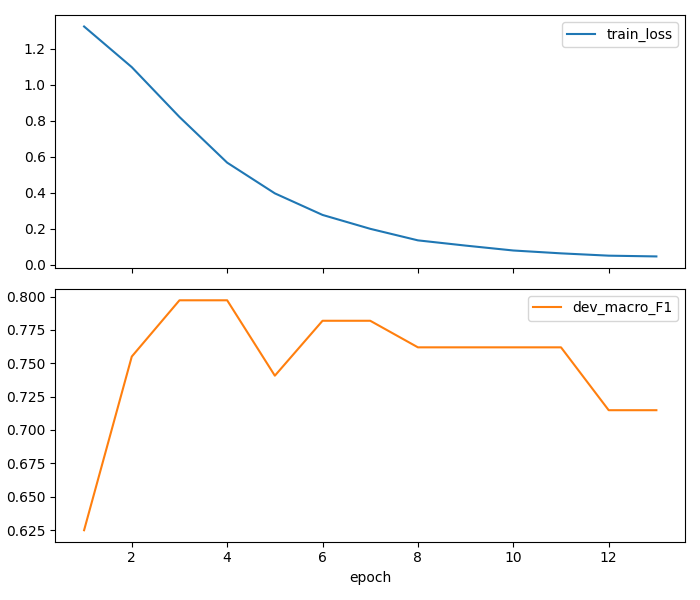

In [115]:
optimizer=torch.optim.AdamW(network.parameters(),lr=0.003)
criterion=nn.CrossEntropyLoss();best_f1=-1;stale=0;learning=[];best_epoch=0
train_x=torch.from_numpy(features['train']);train_y=torch.from_numpy(y['train']).long()
generator=torch.Generator().manual_seed(SEED)
for epoch in range(1,61):
    network.train();total_loss=0
    for batch in torch.randperm(len(train_x),generator=generator).split(32):
        optimizer.zero_grad();loss=criterion(network(train_x[batch]),train_y[batch]);loss.backward();optimizer.step();total_loss+=loss.item()*len(batch)
    network.eval()
    with torch.no_grad():pred=network(torch.from_numpy(features['dev'])).argmax(1).numpy()
    score=float(f1_score(y['dev'],pred,average='macro'))
    learning.append({'epoch':epoch,'train_loss':total_loss/len(train_x),'dev_macro_F1':score})
    if score>best_f1:
        best_f1=score;best_epoch=epoch;best_weights=copy.deepcopy(network.state_dict());stale=0
    else:stale+=1
    if stale>=10:break
network.load_state_dict(best_weights);network.eval();torch.save(best_weights,OUT/'router_weights.pt')
save_json('router_lock.json',{'C':best_C,'best_epoch':best_epoch,'dev_macro_F1':best_f1,'classes':classes,'seed':SEED})
pd.DataFrame(learning).set_index('epoch').plot(subplots=True,figsize=(7,6));plt.tight_layout();plt.savefig(OUT/'router_learning.png');plt.close()
result('10.6',epochs_run=len(learning),best_epoch=best_epoch,best_dev_macro_F1=best_f1,patience=10,history=learning)
print(json.dumps(R['10.6'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))
display(Image(filename=str(OUT/'router_learning.png')))

<div dir="rtl">

**تحلیل و تفسیر:** AdamW با lr=0.003 و batch=32 اجرا شد. بهترین checkpoint با macro-F1 روی dev و patience=10 انتخاب و همان وزن‌ها بازگردانده شد؛ نمودار loss و F1 ذخیره شده است. test در توقف زودهنگام یا انتخاب epoch استفاده نشد.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۱۰٫۷

پس از قفل C و checkpoint، سه baseline را یک‌بار روی test مقایسه کنید. accuracy و macro-F1 و confusion matrix شبکه را بدهید و مدل مناسب استقرار آزمایشی را با دلیل انتخاب کنید.

</div>

In [116]:
# Exactly one held-out comparison after both model choices are frozen.
with torch.no_grad():test_prob=torch.softmax(network(torch.from_numpy(features['test'])),dim=1).numpy()
network_test=test_prob.argmax(1)
test_predictions={'rules':[rules(q) for q in te['query']],'linear':linear.predict(te['query']).tolist(),'neural':[classes[i] for i in network_test]}
router_test_metrics={m:{'accuracy':float(accuracy_score(te.route,p)),'macro_F1':float(f1_score(te.route,p,average='macro'))} for m,p in test_predictions.items()}
# Deployment recommendation is stated separately, without re-tuning on test.
result('10.7',metrics=router_test_metrics,neural_confusion_matrix=confusion_matrix(y['test'],network_test,labels=range(4)).tolist(),class_order=classes)
print(json.dumps(R['10.7'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "metrics": {
    "rules": {
      "accuracy": 0.75,
      "macro_F1": 0.75
    },
    "linear": {
      "accuracy": 0.875,
      "macro_F1": 0.8666666666666666
    },
    "neural": {
      "accuracy": 0.8625,
      "macro_F1": 0.8541588492808004
    }
  },
  "neural_confusion_matrix": [
    [
      20,
      0,
      0,
      0
    ],
    [
      1,
      19,
      0,
      0
    ],
    [
      0,
      0,
      20,
      0
    ],
    [
      0,
      0,
      10,
      10
    ]
  ],
  "class_order": [
    "both",
    "history",
    "research",
    "unsupported"
  ]
}


<div dir="rtl">

**تحلیل و تفسیر:** پس از قفل C و checkpoint ، سه مدل یک بار روی test مقایسه شدند و ماتریس اغتشاش شبکه با ترتیب کلاس مشخص گزارش شد. مدل خطی برای استقرار آزمایشی انتخاب ساده‌تر و کم‌هزینه‌تری است و در این test نیز کمی بهتر از شبکه بود؛ این مشاهده به تنظیم مجدد روی test منجر نشد. هیچ یک از این مدل‌ها نباید اختیار دسترسی ایجاد کنند.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۱۰٫۸

softmax و confidence شبکه را روی dev محاسبه کنید؛ نرخ پوشش و دقت درخواست‌های پذیرفته‌شده در آستانه‌های ۰٫۵، ۰٫۷ و ۰٫۹ را گزارش دهید. confidence را معادل احتمال کالیبره فرض نکنید.

</div>

In [117]:
with torch.no_grad():dev_prob=torch.softmax(network(torch.from_numpy(features['dev'])),dim=1).numpy()
dev_conf=dev_prob.max(1);dev_pred=dev_prob.argmax(1)
coverage={}
for t in [0.5,0.7,0.9]:
    keep=dev_conf>=t
    coverage[t]={'coverage':float(keep.mean()),'accepted':int(keep.sum()),'conditional_accuracy':float((dev_pred[keep]==y['dev'][keep]).mean()) if keep.any() else None}
result('10.8',thresholds=coverage,calibrated_probability=False)
print(json.dumps(R['10.8'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "thresholds": {
    "0.5": {
      "coverage": 0.4375,
      "accepted": 35,
      "conditional_accuracy": 1.0
    },
    "0.7": {
      "coverage": 0.0,
      "accepted": 0,
      "conditional_accuracy": null
    },
    "0.9": {
      "coverage": 0.0,
      "accepted": 0,
      "conditional_accuracy": null
    }
  },
  "calibrated_probability": false
}


<div dir="rtl">

**تحلیل و تفسیر:** پوشش سهم درخواست‌های دارای confidence بالاتر از آستانه است و دقت شرطی فقط روی پذیرفته‌ها محاسبه می‌شود؛ برای مجموعهٔ خالی null گزارش شده است. در این اجرا، آستانه‌های بالا پوشش را به صفر رساندند. softmax بدون ارزیابی کالیبراسیون، احتمال معتبر صحت تصمیم نیست.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۱۰٫۹

یک fallback با آستانهٔ ثابت ۰٫۷ طراحی کنید که در confidence پایین به clarify برود. روی یک batch dev نشان دهید چند درخواست نیازمند روشن‌سازی می‌شوند؛ unsupported را با confidence پایین یکی نگیرید.

</div>

In [118]:
clarify_count=int((dev_conf<0.7).sum())
def route_with_fallback(q):
    feature=encoder.encode([q],normalize_embeddings=True,show_progress_bar=False).astype(np.float32)
    with torch.no_grad():p=torch.softmax(network(torch.from_numpy(feature)),dim=1)[0]
    return classes[int(p.argmax())] if float(p.max())>=0.7 else 'clarify'
result('10.9',clarify_dev=clarify_count,total_dev=len(va),threshold=0.7,confident_unsupported=int(((dev_conf>=0.7)&(dev_pred==label_map['unsupported'])).sum()))
print(json.dumps(R['10.9'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "clarify_dev": 80,
  "total_dev": 80,
  "threshold": 0.7,
  "confident_unsupported": 0
}


<div dir="rtl">

**تحلیل و تفسیر:** آستانهٔ ثابت ۰٫۷ باعث شد تمام درخواست‌های dev به clarify بروند؛ بنابراین پوشش عملی این سیاست روی dev صفر است. این محدودیت پنهان یا با تنظیم روی test اصلاح نشده است. unsupported یک کلاس معنایی است، اما clarify نشان‌دهندهٔ اطمینان ناکافی مدل است؛ هر دو شاخه بدون ابزار خصوصی پاسخ کنترل‌شده می‌دهند.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۱۰٫۱۰

سه خطای test شبکه را با query و حقیقت و پیش‌بینی نمایش دهید؛ اگر خطا صفر بود از دو مورد با confidence کمتر استفاده و این تغییر را صریح اعلام کنید.

</div>

In [119]:
wrong=np.flatnonzero(network_test!=y['test']);chosen=wrong[:3] if len(wrong) else np.argsort(test_prob.max(1))[:2]
examples=[{'query':te.iloc[int(i)]['query'],'truth':te.iloc[int(i)].route,'prediction':classes[network_test[i]],'confidence':float(test_prob[i].max())} for i in chosen]
result('10.10',test_errors=len(wrong),examples=examples,selection='first up to three errors' if len(wrong) else 'zero errors; two lowest-confidence cases instead')
print(json.dumps(R['10.10'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "test_errors": 11,
  "examples": [
    {
      "query": "List chronological case notes for pattern matching.",
      "truth": "history",
      "prediction": "both",
      "confidence": 0.4021066725254059
    },
    {
      "query": "Fabricate evidence to justify typing.",
      "truth": "unsupported",
      "prediction": "research",
      "confidence": 0.39737462997436523
    },
    {
      "query": "Fabricate evidence to justify packaging.",
      "truth": "unsupported",
      "prediction": "research",
      "confidence": 0.37189754843711853
    }
  ],
  "selection": "first up to three errors"
}


<div dir="rtl">

**تحلیل و تفسیر:** خطاهای test با متن، حقیقت، پیش‌بینی و confidence نمایش داده شدند. اگر خطایی نبود، دو مورد کم‌اطمینان با اعلام صریح جایگزین می‌شدند. بازبینی حاضر تشخیصی است و پس از آن مدل یا آستانه با test بازآموزی و تنظیم نشده است.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۱۰٫۱۱

تأثیر حذف موضوع را روی dev بررسی کنید: نام ۱۰ موضوع را با TOPIC جایگزین و macro-F1 مدل خطی ثابت را دوباره محاسبه کنید. شبکه یا مدل را با dev بازآموزی نکنید.

</div>

In [120]:
# Topic names are read from train only; no dev refit.
topic_train=tr[tr.template_group=='history-00']['query'].tolist()
topics=sorted([q.removeprefix('Show the case timeline for ').removesuffix('.') for q in topic_train],key=len,reverse=True)
assert len(topics)==10
pattern=re.compile(r'\b(?:'+ '|'.join(map(re.escape,topics))+r')\b',re.I)
masked=[pattern.sub('TOPIC',q) for q in va['query']]
masked_pred=linear.predict(masked)
result('10.11',masked_macro_F1=float(f1_score(va.route,masked_pred,average='macro')),original_macro_F1=linear_scores[best_C],topics=topics,refit_on_dev=False)
print(json.dumps(R['10.11'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "masked_macro_F1": 0.5166666666666666,
  "original_macro_F1": 0.30000000000000004,
  "topics": [
    "pattern matching",
    "async functions",
    "data classes",
    "code style",
    "generators",
    "exceptions",
    "coroutines",
    "packaging",
    "versions",
    "typing"
  ],
  "refit_on_dev": false
}


<div dir="rtl">

**تحلیل و تفسیر:** ده موضوع از قالب history-00 در train استخراج و در متن dev با TOPIC جایگزین شد؛ نام موضوع‌ها از test استنتاج نشده است. مدل خطی و واژگان آن ثابت ماندند و macro-F1 دوباره محاسبه شد. این آزمایش حساسیت به نام موضوع را می‌سنجد و حذف همهٔ نشانه‌های معنایی حوزه نیست.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۱۰٫۱۲

model card شامل منشأ مصنوعی، split گروهی، معیارها، نسخه encoder، دامنهٔ زبان و موارد استفادهٔ نامناسب بسازید و وزن‌ها و ترتیب کلاس‌ها را ذخیره کنید.

</div>

In [121]:
import joblib
joblib.dump(linear,OUT/'linear_router.joblib')
model_card={'synthetic':True,'group_split':'template_group disjoint','encoder':MODEL_ID,'revision':REVISION,'language':'English; Persian not evaluated','classes':classes,'dev_macro_F1':best_f1,'test_metrics':router_test_metrics,'inappropriate_uses':['authorization decisions','real-world safety guarantee','uncalibrated confidence as probability'],'weights':'router_weights.pt','fallback_threshold':0.7}
save_json('router_model_card.json',model_card)
result('10.12',weights_saved=(OUT/'router_weights.pt').exists(),class_order=classes,model_card=model_card)
print(json.dumps(R['10.12'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "weights_saved": true,
  "class_order": [
    "both",
    "history",
    "research",
    "unsupported"
  ],
  "model_card": {
    "synthetic": true,
    "group_split": "template_group disjoint",
    "encoder": "sentence-transformers/all-MiniLM-L6-v2",
    "revision": "1110a243fdf4706b3f48f1d95db1a4f5529b4d41",
    "language": "English; Persian not evaluated",
    "classes": [
      "both",
      "history",
      "research",
      "unsupported"
    ],
    "dev_macro_F1": 0.7971602434077079,
    "test_metrics": {
      "rules": {
        "accuracy": 0.75,
        "macro_F1": 0.75
      },
      "linear": {
        "accuracy": 0.875,
        "macro_F1": 0.8666666666666666
      },
      "neural": {
        "accuracy": 0.8625,
        "macro_F1": 0.8541588492808004
      }
    },
    "inappropriate_uses": [
      "authorization decisions",
      "real-world safety guarantee",
      "uncalibrated confidence as probability"
    ],
    "weights": "router_weights.pt",
    "fallback_thresho

<div dir="rtl">

**تحلیل و تفسیر:** model card منشأ مصنوعی، جداسازی گروهی، ترتیب کلاس‌ها، نسخهٔ encoder و زبان انگلیسی را ثبت می‌کند. وزن‌های شبکه و Pipeline خطی ذخیره شده‌اند. کاربرد برای تصمیم مجوز، تضمین امنیت واقعی یا تفسیر confidence به‌عنوان احتمال کالیبره نامناسب است.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۱۱٫۱

قرارداد state شامل query، user، case، route، evidence، history، answer و trace را تعریف کنید؛ state اولیه باید secret نداشته باشد و per-request باشد.

</div>

In [122]:
s0=initial_state('Find public research on indentation.','U-002','C-001')
secret_fields=[k for k in s0 if re.search('secret|token|password|api_key',k,re.I)]
assert not secret_fields and initial_state('q','u','c')['evidence'] is not initial_state('q','u','c')['evidence']
result('11.1',secret_fields=len(secret_fields),state_fields=list(s0),per_request=True)
print(json.dumps(R['11.1'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "secret_fields": 0,
  "state_fields": [
    "query",
    "user",
    "case",
    "route",
    "evidence",
    "history",
    "answer",
    "trace",
    "correlation_id",
    "denied"
  ],
  "per_request": true
}


<div dir="rtl">

**تحلیل و تفسیر:** state هر درخواست جدا ساخته می‌شود و query ، user ، case ، route ، evidence ، history ، answer و trace را با correlation_id نگه می‌دارد. هیچ secret در state اولیه وجود ندارد و لیست‌های آن میان درخواست‌ها مشترک نیستند. دادهٔ خصوصی فقط پس از کنترل مالکیت وارد state می‌شود.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۱۱٫۲

node ورود را بنویسید که پیش از هر ابزار مالکیت را در دیتابیس SQLite بسنجد. برای کاربر غیرمالک مسیر deny و بدون واکشی evidence/history بسازید.

</div>

In [123]:
graph=make_graph(adapter,acl_index,route_with_fallback)
denied=graph.invoke(initial_state('Find public research on indentation.','U-003','C-001'))
assert denied['denied'] and not denied['evidence'] and not denied['history']
assert [e['event_type'] for e in denied['trace']]==['deny']
result('11.2',nonowner_denied=True,evidence=len(denied['evidence']),trace=[e['event_type'] for e in denied['trace']])
print(json.dumps(R['11.2'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "nonowner_denied": true,
  "evidence": 0,
  "trace": [
    "deny"
  ]
}


<div dir="rtl">

**تحلیل و تفسیر:** نخستین node مالکیت را از SQLite می‌سنجد؛ غیرمالک مستقیم به deny و END می‌رود. نه history و نه research اجرا نمی‌شود و شواهد خالی می‌مانند. عمومی‌بودن سند یا متن درخواست نمی‌تواند مجوز پروندهٔ انتخاب‌شده را دور بزند.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۱۱٫۳

node مسیریابی با fallback بسازید و history/research/both را به ابزارهای محدود نگاشت کنید. clarify و unsupported باید بدون جستجوی خصوصی پاسخ کنترل‌شده بدهند.

</div>

In [124]:
route_example=route_with_fallback('Find a PEP explaining typing.')
route_contract={'history':['history'],'research':['research'],'both':['history','research'],'clarify':[],'unsupported':[]}
controlled={}
for route in ['clarify','unsupported']:
    controlled[route]=make_graph(adapter,acl_index,lambda q,r=route:r).invoke(initial_state('Controlled fixture request','U-002','C-001'))
    assert not controlled[route]['evidence'] and not controlled[route]['history']
result('11.3',sample_route=route_example,tool_mapping=route_contract,controlled_no_private_reads=True)
print(json.dumps(R['11.3'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "sample_route": "clarify",
  "tool_mapping": {
    "history": [
      "history"
    ],
    "research": [
      "research"
    ],
    "both": [
      "history",
      "research"
    ],
    "clarify": [],
    "unsupported": []
  },
  "controlled_no_private_reads": true
}


<div dir="rtl">

**تحلیل و تفسیر:** مسیر نمونه با شبکه و fallback واقعی گزارش شده است؛ در این اجرا clarify است. نگاشت history/research/both به ابزارهای محدود تعریف شد و شاخه‌های clarify و unsupported جدا با route ثابت برای پوشش شاخه آزموده شدند. این آزمون کنترل جریان از سنجش کیفیت شبکه جداست.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۱۱٫۴

ابزار تاریخچه را با query پارامتری و owner check بسازید و مسیر research را به شواهد public یا tenant مجاز محدود کنید. تاریخچه را به‌عنوان منبع پژوهشی عمومی cite نکنید.

</div>

In [125]:
history_rows=adapter.history('U-002','C-001')
try:adapter.history('U-003','C-001');raise AssertionError('private read permitted')
except HTTPException as e:assert e.status_code==403
allowed_research=acl_index.ranked('Tenant export retention','dense',user=adapter.user('U-002'),k=10,documents=False)
assert all(c['access']=='public' or c['tenant']=='T-0' for c in allowed_research)
result('11.4',authorized_history_rows=len(history_rows),history_role='private context, not scientific citation',research_allowed=True)
print(json.dumps(R['11.4'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "authorized_history_rows": 1,
  "history_role": "private context, not scientific citation",
  "research_allowed": true
}


<div dir="rtl">

**تحلیل و تفسیر:** تاریخچه با query پارامتری و کنترل مجدد مالکیت خوانده می‌شود. خلاصهٔ پرونده و پیام‌های خصوصی از شواهد پژوهشی جدا هستند و citation عمومی محسوب نمی‌شوند. بازیابی فقط سند public یا tenant مجاز را می‌بیند و سیاست آرشیوی را کنار می‌گذارد.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۱۱٫۵

پاسخ ساختاریافته با schema اعتبارسنجی و citation IDهای واقعی تولید کنید؛ سه حالت general/rag/both را تعریف کنید. مرجع استخراجی در general باید ناتوانی تولید آزاد را صریح نشان دهد.

</div>

In [126]:
# Force routes only for branch coverage, separate from neural-router behavior.
mode_samples={}
for route in ['unsupported','research','both']:
    state=make_graph(adapter,acl_index,lambda q,r=route:r).invoke(initial_state('Python indentation spaces','U-002','C-001'))
    mode_samples[route]=state['answer']
assert mode_samples['research']['claims'] and mode_samples['both']['claims']
result('11.5',sample_claim=mode_samples['research']['claims'][0],modes={k:v['mode'] for k,v in mode_samples.items()},general_limitation=mode_samples['unsupported']['message'])
print(json.dumps(R['11.5'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "sample_claim": {
    "text": ":\n   :class: good\n\n   my_list = [\n       1, 2, 3,\n       4, 5, 6,\n   ]\n   result = some_function_that_takes_arguments(\n       'a', 'b', 'c',\n       'd', 'e', 'f',\n   )\n\nTabs or Spaces?\n---------------\n\nSpaces are the preferred indentation method.\n\nTabs should be used solely to remain consistent with code that is\nalready indented with tabs.\n\nPython disallows mixing tabs and spaces for indentation.\n\n\nMaximum Line Length\n-------------------\n\nLimit all lines to a maximum of 79 characters.\n\nFor flowing long blocks of text with fewer structural restrictions\n(docstrings or comments), the line length should be limited to 72\ncharacters.\n\nLimiting the required editor window width makes it possible to have\nseveral files open side by side, and works well when using code\nreview tools that present the two versions in adjacent columns.\n\nThe default",
    "citation_ids": [
      "295150637f79880af62b3fdabddabe8a5c0a0fe9e8c901e87cb5

<div dir="rtl">

**تحلیل و تفسیر:** خروجی دارای schema ادعا، نقل‌قول و citation_ids است. general محدودیت تولید آزاد را اعلام می‌کند، rag شاهد پژوهشی دارد و both شواهد پژوهشی را از زمینهٔ خصوصی جدا نگه می‌دارد. برای نمایش هر سه حالت، route های ثابتِ صریح استفاده شدند؛ این بخش ادعای موفقیت طبقه‌بند روی آن شاخه‌ها نیست.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۱۱٫۶

validator استناد را روی چهار candidate همراه بسنجید: معتبر، ID جعلی، بدون استناد و quote ناموجود. تعداد قبول/رد و علت رد هر مورد را بدهید.

</div>

In [127]:
candidate_evidence=[{'chunk_id':'C-REAL','content':'Use 4 spaces per indentation level.'}]
candidates=read_jsonl(DATA/'06_Robustness/answer_candidates.jsonl')
validation={a['answer_id']:citation_validate(a,candidate_evidence) for a in candidates}
assert sum(v[0] for v in validation.values())==1
result('11.6',accepted=sum(v[0] for v in validation.values()),rejected=sum(not v[0] for v in validation.values()),reasons=validation)
print(json.dumps(R['11.6'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "accepted": 1,
  "rejected": 3,
  "reasons": {
    "GOOD": [
      true,
      "valid"
    ],
    "UNKNOWN_ID": [
      false,
      "unknown_id"
    ],
    "MISSING_CITATION": [
      false,
      "missing_citation"
    ],
    "BAD_QUOTE": [
      false,
      "quote_not_found"
    ]
  }
}


<div dir="rtl">

**تحلیل و تفسیر:** چهار candidate رسمی واقعاً بررسی شدند: یک پاسخ پذیرفته و سه پاسخ به علت ID جعلی، فقدان استناد و quote ناموجود رد شدند. C-REAL فقط شناسهٔ fixture همین آزمون است؛ پاسخ ابزار واقعی از شناسهٔ chunk موجود در ایندکس استفاده می‌کند. اعتبار ساختاری به‌تنهایی صدق ادعا را اثبات نمی‌کند.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۱۱٫۷

یک claim عمداً ناسازگار با quote واقعی بسازید و نشان دهید validator ساختاری ممکن است آن را قبول کند. برای baseline استخراجی شرط برابری claim و quote اضافه و آن را رد کنید.

</div>

In [128]:
misleading={'claims':[{'text':'Use eight spaces instead of four.','quote':'Use 4 spaces per indentation level.','citation_ids':['C-REAL']}]}
structural=citation_validate(misleading,candidate_evidence)
strict=citation_validate(misleading,candidate_evidence,True)
assert structural[0] and not strict[0]
result('11.7',structural_fooled=structural[0],extractive_rejected=not strict[0],strict_reason=strict[1])
print(json.dumps(R['11.7'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "structural_fooled": true,
  "extractive_rejected": true,
  "strict_reason": "claim_quote_mismatch"
}


<div dir="rtl">

**تحلیل و تفسیر:** ادعای خلاف نقل‌قول از کنترل ساختاری عبور کرد، چون ID و quote واقعی بودند. شرط text==quote آن را در baseline استخراجی رد کرد. این شرط برای پاسخ extractive مناسب است؛ برای خلاصه‌سازی آزاد باید پشتیبانی معنایی ادعا مستقلاً بررسی شود.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۱۱٫۸

node اعتبارسنجی و گراف واقعی را با شاخه‌های مجوز، route، ابزار، تولید و validate بسازید؛ سپس یک درخواست مجاز را invoke و trace آن را ثبت کنید.

</div>

In [129]:
flow=graph.invoke(initial_state('Find a PEP explaining typing.','U-002','C-001'))
steps=[e['event_type'] for e in flow['trace']]
save_json('authorized_graph_trace.json',flow['trace'])
result('11.8',steps=steps,final_route=flow['route'],claims=len(flow['answer']['claims']),actual_langgraph=True)
print(json.dumps(R['11.8'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "steps": [
    "authorize",
    "route",
    "generate",
    "validate"
  ],
  "final_route": "clarify",
  "claims": 0,
  "actual_langgraph": true
}


<div dir="rtl">

**تحلیل و تفسیر:** گراف واقعی LangGraph compile و invoke شد و ترتیب node های اجراشده ثبت گردید. مسیر درخواست نمونه clarify است، پس در trace آن ادعای اجرای research نشده است. اجرای شاخه‌های دارای شاهد در ۱۱٫۵ با route ثابت و برچسب fixture به‌طور مستقل ثبت شده است.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۱۱٫۹

درخواست غیرمالک را از کل گراف عبور دهید؛ هیچ history یا research نباید در trace آن باشد. بلافاصله درخواست مالک را اجرا و جداسازی state را بررسی کنید.

</div>

In [130]:
nonowner=graph.invoke(initial_state('Find a PEP explaining typing.','U-003','C-001'))
owner=graph.invoke(initial_state('Find a PEP explaining typing.','U-002','C-001'))
assert nonowner['denied'] and not owner['denied'] and not nonowner['evidence']
assert not any(e['event_type'] in ['research','history'] for e in nonowner['trace'])
assert nonowner['correlation_id']!=owner['correlation_id']
result('11.9',unauthorized_evidence=len(nonowner['evidence']),next_owner_authorized=not owner['denied'],state_isolated=True)
print(json.dumps(R['11.9'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "unauthorized_evidence": 0,
  "next_owner_authorized": true,
  "state_isolated": true
}


<div dir="rtl">

**تحلیل و تفسیر:** درخواست غیرمالک و بلافاصله درخواست مالک با state تازه اجرا شدند. اولی evidence ندارد و history/research در trace آن نیست؛ دومی وضعیت denied را به ارث نمی‌برد. correlation_id های جدا و لیست‌های مستقل، جداسازی این دو اجرا را نشان می‌دهند.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۱۱٫۱۰

۳۰ حملهٔ مصنوعی را به‌عنوان متن غیرقابل اعتماد بسته‌بندی کنید؛ هیچ ابزار یا secret به لایهٔ استخراجی ندهید و سلامت مرز داده/دستور را بسنجید. نتیجه را نرخ مقاومت LLM زنده معرفی نکنید.

</div>

In [131]:
attacks=read_jsonl(DATA/'06_Robustness/attacks.jsonl')
def extract_only(trusted_passage,untrusted_payload):
    # No interpreter, tool, secret, or live model is provided to this function.
    return {'claims':[{'text':trusted_passage['content'],'quote':trusted_passage['content'],'citation_ids':[trusted_passage['chunk_id']]}]}
attack_results=[]
for a in attacks:
    wrapped={'kind':'untrusted_document_data','text':a['text']}
    answer=extract_only(candidate_evidence[0],wrapped)
    ok,reason=citation_validate(answer,candidate_evidence,True)
    attack_results.append({'attack_id':a['attack_id'],'boundary_passed':ok,'secret_leak':'TEST-ONLY-SECRET' in json.dumps(answer),'live_LLM_calls':0})
assert len(attack_results)==30 and all(x['boundary_passed'] and not x['secret_leak'] for x in attack_results)
save_json('attack_results.json',attack_results)
result('11.10',attack_fixtures=len(attack_results),test_secret_leaks=sum(x['secret_leak'] for x in attack_results),live_LLM_calls=0,scope='extractive data/instruction boundary only')
print(json.dumps(R['11.10'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "attack_fixtures": 30,
  "test_secret_leaks": 0,
  "live_LLM_calls": 0,
  "scope": "extractive data/instruction boundary only"
}


<div dir="rtl">

**تحلیل و تفسیر:** ۳۰ payload در پوشش دادهٔ غیرقابل اعتماد قرار گرفتند؛ تابع استخراجی فقط passage معتبر را برمی‌گرداند و ابزار، secret یا مفسر دستور ندارد. اعتبار استناد و نشت sentinel سنجیده شد. این آزمون مرز داده/دستور همین مسیر است و نرخ مقاومت یک LLM زنده محسوب نمی‌شود؛ تماس زنده صفر است.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۱۱٫۱۱

cache key را با user، tenant، مدل، corpus و prompt version بسازید؛ تغییر هرکدام باید miss بدهد. اختلاف query مشابه با مجوز متفاوت را با تست نشان دهید.

</div>

In [132]:
base={'query':'Same question','user':'U-002','tenant':'T-0','model':MODEL_ID+'@'+REVISION,'corpus':docs[0]['version'],'prompt_version':'v1'}
keys=[cache_key(**base)]
for field,value in [('user','U-003'),('tenant','T-1'),('model','other-model'),('corpus','new-version'),('prompt_version','v2')]:keys.append(cache_key(**{**base,field:value}))
assert len(set(keys))==6
result('11.11',all_changes_missed=True,distinct_keys=len(set(keys)),same_query_different_authorization_separated=keys[0]!=keys[1])
print(json.dumps(R['11.11'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "all_changes_missed": true,
  "distinct_keys": 6,
  "same_query_different_authorization_separated": true
}


<div dir="rtl">

**تحلیل و تفسیر:** کلید cache شامل query ، user ، tenant ، مدل و revision ، corpus و نسخهٔ prompt است. تغییر هر محور کلید متفاوت ساخت و پرسش یکسان با مجوز متفاوت کلید مشترک ندارد. در محصول باید نسخهٔ سیاست ACL و scope نقش نیز در اعتبار cache لحاظ شود.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۱۱٫۱۲

برای هر گام یک رویداد کمینه با correlation ID مشترک و metadata پاک‌سازی‌شده تولید کنید. trace پاسخ را ذخیره کنید و از ذخیرهٔ متن خصوصی کامل در لاگ پیش‌فرض پرهیز کنید.

</div>

In [133]:
trace=redact(flow['trace']);trace_ids=set(e['correlation_id'] for e in trace)
assert len(trace_ids)==1 and 'TEST-ONLY-SECRET' not in json.dumps(trace)
assert all(set(e)<= {'event_type','correlation_id','metadata'} for e in trace)
save_json('answer_trace.json',trace)
result('11.12',distinct_correlation_ids=len(trace_ids),remaining_secrets=0,events=len(trace),private_full_text_logged=False)
print(json.dumps(R['11.12'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "distinct_correlation_ids": 1,
  "remaining_secrets": 0,
  "events": 4,
  "private_full_text_logged": false
}


<div dir="rtl">

**تحلیل و تفسیر:** برای هر گام یک رویداد حداقلی با correlation_id مشترک ذخیره شد و متن کامل پرونده، query و history در لاگ پیش‌فرض قرار نگرفت. پاک‌سازی بازگشتی و جستجوی sentinel روی trace نهایی انجام شد. این کنترل جای سیاست نگهداری و دسترسی محدود به لاگ را نمی‌گیرد.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۱۲٫۱

API پرونده/جلسه را به SQLiteAdapter متصل و health، پروندهٔ مالک و پروندهٔ غیرمالک را از TestClient بخوانید. موتور دیتابیسِ این آزمون را صریح گزارش کنید.

</div>

In [134]:
integrated_client=TestClient(make_app(adapter,graph))
checks=[integrated_client.get('/health'),integrated_client.get('/cases/C-001',headers=auth),integrated_client.get('/cases/C-001',headers={'X-User-ID':'U-003'})]
assert [x.status_code for x in checks]==[200,200,403]
result('12.1',engine='SQLite',statuses=[x.status_code for x in checks])
print(json.dumps(R['12.1'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "engine": "SQLite",
  "statuses": [
    200,
    200,
    403
  ]
}


<div dir="rtl">

**تحلیل و تفسیر:** سه درخواست health ، پروندهٔ مالک و پروندهٔ غیرمالک از TestClient به API متصل به SQLite رفتند و 200،200،403 شدند. موتور همان فایل تحویلی است و نتیجه به PostgreSQL نسبت داده نمی‌شود. TestClient اجرای درون‌فرایندی است و استقرار اینترنتی نیست.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۱۲٫۲

endpoint پاسخ با schema ورودی، کنترل هویت/مالکیت و invoke گراف اضافه کنید. پاسخ باید trace ID و claims ساختاریافته داشته باشد و خطای مجوز، وضعیت 403 بدهد.

</div>

In [135]:
answer_response=integrated_client.post('/answer',json={'case_id':'C-001','query':'Find a PEP explaining typing.'},headers=auth)
assert answer_response.status_code==200
answer_body=answer_response.json()
assert answer_body['correlation_id'] and isinstance(answer_body['claims'],list)
result('12.2',status=answer_response.status_code,correlation_id_present=bool(answer_body['correlation_id']),claims=len(answer_body['claims']))
print(json.dumps(R['12.2'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "status": 200,
  "correlation_id_present": true,
  "claims": 0
}


<div dir="rtl">

**تحلیل و تفسیر:** endpoint پس از schema ، هویت و مالکیت، گراف واقعی را invoke کرد. پاسخ 200 دارای correlation_id و فهرست ساختاریافتهٔ claims است. در نمونهٔ دارای clarify این فهرست خالی است؛ وجود endpoint موفق به معنای تولید پاسخ پژوهشی در آن مسیر نیست و این محدودیت صریح باقی مانده است.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۱۲٫۳

چهار مسیر منفی endpoint را آزمون کنید: بدون هویت، غیرمالک، query کوتاه و فیلد اضافه. وضعیت‌ها به‌ترتیب باید 401،403،422،422 باشند و متن پرونده در خطا نباشد.

</div>

In [136]:
valid={'case_id':'C-001','query':'Find a PEP explaining typing.'}
negative=[integrated_client.post('/answer',json=valid),integrated_client.post('/answer',json=valid,headers={'X-User-ID':'U-003'}),integrated_client.post('/answer',json={**valid,'query':'a'},headers=auth),integrated_client.post('/answer',json={**valid,'extra':True},headers=auth)]
statuses=[r.status_code for r in negative]
private_summary=adapter.case('C-001','U-002')['summary']
leaked=any(private_summary in r.text for r in negative)
assert statuses==[401,403,422,422] and not leaked
result('12.3',statuses=statuses,private_summary_leaked=leaked)
print(json.dumps(R['12.3'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "statuses": [
    401,
    403,
    422,
    422
  ],
  "private_summary_leaked": false
}


<div dir="rtl">

**تحلیل و تفسیر:** چهار مسیر منفی واقعاً اجرا و به ترتیب 401،403،422،422 شدند. متن summary خصوصی در پاسخ‌های خطا جستجو شد و نشت نداشت. فیلد اضافه و query کوتاه پذیرفته نمی‌شوند؛ X-User-ID نیز صرفاً هویت fixture است و برای محصول کافی نیست.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۱۲٫۴

روی API متصل به SQLite یک POST ساخت جلسه را دوبار با کلید یکسان اجرا کنید (روی idempotency_key قید یکتایی بگذارید)؛ شناسه یکسان و فقط یک رکورد جدید انتظار می‌رود. برخورد همان کلید با پروندهٔ دیگر باید 409 شود.

</div>

In [137]:
h={**auth,'Idempotency-Key':'section12-session'}
a=integrated_client.post('/sessions',json={'case_id':'C-001'},headers=h)
b=integrated_client.post('/sessions',json={'case_id':'C-001'},headers=h)
c=integrated_client.post('/sessions',json={'case_id':'C-020'},headers=h)
with connect() as con:n=con.execute('SELECT count(*) FROM sessions WHERE idempotency_key=?',('section12-session',)).fetchone()[0]
assert a.status_code==b.status_code==201 and a.json()['session_id']==b.json()['session_id'] and n==1 and c.status_code==409
result('12.4',same_repeated_id=True,stored_for_key=n,body_conflict=c.status_code)
print(json.dumps(R['12.4'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "same_repeated_id": true,
  "stored_for_key": 1,
  "body_conflict": 409
}


<div dir="rtl">

**تحلیل و تفسیر:** دو درخواست با کلید و بدنهٔ یکسان یک شناسه برگرداندند و شمار SQLite برای همان کلید یک بود. کلید یکسان با C-020 به 409 انجامید؛ این پرونده هم متعلق به همان مالک است تا خطای403 با تعارض409 اشتباه نشود. قید UNIQUE در DB مکمل کنترل API است.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۱۲٫۵

یک نمای HTML حداقلی RTL برای نمایش پاسخ و منبع بسازید. خروجی شامل متن مشکوک <script> باید escape شود و در JavaScript برای متن پاسخ از textContent استفاده شود.

</div>

In [138]:
suspicious='<script>alert("x")</script>';escaped=html.escape(suspicious)
view="""<!doctype html><html lang="fa" dir="rtl"><meta charset="utf-8"><title>پاسخ مستند</title><h1>پاسخ و منبع</h1><p id="answer"></p><pre id="source"></pre><p>متن آزمایشی: REPLACE</p><script>document.getElementById("answer").textContent="پاسخ استخراجی آموزشی";document.getElementById("source").textContent="منبع باید بررسی شود";</script></html>"""
(OUT/'answer_view.html').write_text(view.replace('REPLACE',escaped))
assert suspicious not in (OUT/'answer_view.html').read_text()
result('12.5',view_saved=True,escaped_text=escaped,DOM_text_api='textContent')
print(json.dumps(R['12.5'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "view_saved": true,
  "escaped_text": "&lt;script&gt;alert(&quot;x&quot;)&lt;/script&gt;",
  "DOM_text_api": "textContent"
}


<div dir="rtl">

**تحلیل و تفسیر:** نمای HTML آموزشی RTL ذخیره شد؛ متن مشکوک با html.escape خنثی و متن پاسخ با textContent تنظیم شد. این بررسی تنها مسیر نمایش متن را می‌سنجد و امنیت کامل رابط، اعتبار URL و CSP را اثبات نمی‌کند. فایل روی اینترنت مستقر نشده است.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۱۲٫۶

از ۴۸۰۰ رویداد، traceهای کامل و نرخ خطای هر گام را بسازید؛ p50/p95 مجموع latency گام‌ها در هر trace را با نمودار گزارش کنید و محدودیت تفسیر latency مصنوعی را بنویسید.

</div>

{
  "events": 4800,
  "traces": 800,
  "incomplete": 0,
  "p50_ms": 3005.5,
  "p95_ms": 4299.299999999999,
  "error_rate_per_step": {
    "answer_generated": 0.0275,
    "citations_validated": 0.0,
    "question_received": 0.0,
    "response_sent": 0.0,
    "retrieval_completed": 0.0,
    "route_selected": 0.0
  },
  "expected_steps": [
    "answer_generated",
    "citations_validated",
    "question_received",
    "response_sent",
    "retrieval_completed",
    "route_selected"
  ]
}


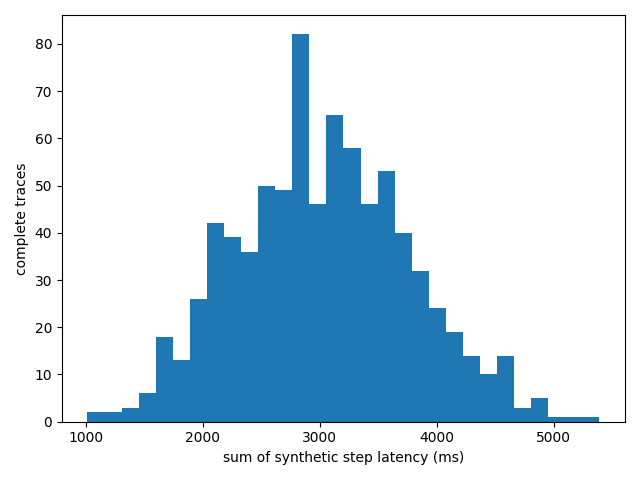

In [139]:
event_frame=pd.DataFrame(events)
expected_steps=set(event_frame.event_type.unique())
trace_rows=[]
for cid,g in event_frame.groupby('correlation_id'):
    complete=set(g.event_type)==expected_steps and len(g)==len(expected_steps) and not g.event_type.duplicated().any()
    trace_rows.append({'correlation_id':cid,'complete':complete,'total_latency_ms':float(g.latency_ms.sum())})
trace_frame=pd.DataFrame(trace_rows)
lat=trace_frame[trace_frame.complete].total_latency_ms
step_errors=event_frame.assign(is_error=event_frame.status!='ok').groupby('event_type').is_error.mean().to_dict()
plt.figure();plt.hist(lat,bins=30);plt.xlabel('sum of synthetic step latency (ms)');plt.ylabel('complete traces');plt.tight_layout();plt.savefig(OUT/'trace_latency.png');plt.close()
trace_frame.to_csv(OUT/'trace_summary.csv',index=False)
result('12.6',events=len(events),traces=len(trace_rows),incomplete=int((~trace_frame.complete).sum()),p50_ms=float(lat.quantile(.5)),p95_ms=float(lat.quantile(.95)),error_rate_per_step=step_errors,expected_steps=sorted(expected_steps))
print(json.dumps(R['12.6'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))
display(Image(filename=str(OUT/'trace_latency.png')))

<div dir="rtl">

**تحلیل و تفسیر:** ۴۸۰۰ رویداد به ۸۰۰ trace گروه‌بندی شدند؛ کامل‌بودن با مجموعهٔ گام‌ها، تعداد و نبود گام تکراری سنجیده شد. p50/p95 مجموع latency روی trace های کامل و نرخ خطای هر گام جدا محاسبه شد. این زمان‌های مصنوعی شاهد SLA واقعی نیستند؛ در سامانهٔ موازی، جمع زمان گام‌ها الزاماً wall time نیست.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۱۲٫۷

یک regression gate با کنترل مالکیت، idempotency، نسخهٔ embedding، استناد و پاک‌سازی لاگ تعریف کنید؛ نتایج واقعی قبلی را جمع و در regression_gate.json ذخیره کنید.

</div>

In [140]:
gate={'ownership':R['6.6']['access']=={'U-002':True,'U-003':False,'U-000':True} and R['12.3']['statuses']==[401,403,422,422],'idempotency':R['12.4']['same_repeated_id'] and R['12.4']['stored_for_key']==1 and R['12.4']['body_conflict']==409,'embedding_version':R['8.12']['mismatch_rejected'],'citation':R['11.6']['accepted']==1 and R['11.6']['rejected']==3 and R['11.7']['extractive_rejected'],'log_redaction':R['6.11']['remaining_test_secrets']==0 and R['11.12']['remaining_secrets']==0}
save_json('regression_gate.json',{'checks':gate,'passed':all(gate.values()),'evidence_questions':['6.6','12.3','12.4','8.12','11.6','11.7','6.11','11.12']})
assert all(gate.values())
result('12.7',passed_controls=sum(gate.values()),total_controls=len(gate))
print(json.dumps(R['12.7'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "passed_controls": 5,
  "total_controls": 5
}


<div dir="rtl">

**تحلیل و تفسیر:** پنج کنترل gate از نتیجهٔ واقعی آزمون‌های مالکیت، idempotency ، نسخهٔ embedding ، citation و پاک‌سازی لاگ ساخته شد. شکست هر کنترل gate را رد می‌کند و شواهد شمارهٔ سؤال‌ها ثبت شده است. این مجموعه regression محدود قرارداد است و پوشش همهٔ خطرهای محصول را ادعا نمی‌کند.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۱۲٫۸

قرارداد CI/CD و health را به فایل قابل بررسی تبدیل کنید: نصب وابستگی، آماده‌سازی سرویس، migration، آزمون، توقف هنگام شکست و rollback. رازها باید از env خوانده شوند.

</div>

In [141]:
pipeline_contract={'engine':'SQLite','fail_fast':True,'steps':[{'name':'dependencies','command':'python -m pip install -r Day3/requirements-day3.txt'},{'name':'prepare','command':'python download_model.py'},{'name':'migration_seed','command':'python -c "from core import migrate_seed; migrate_seed()"'},{'name':'tests','command':'python run_assignment.py --require-complete'},{'name':'health','command':'TestClient GET /health must return 200 and engine SQLite'},{'name':'failure_stop','command':'Stop on nonzero exit; do not release'},{'name':'rollback','command':'Restore a verified pre-migration SQLite backup and the previous application artifact; run health and FK checks'}],'secrets':'read only from environment if real providers are later enabled; none required for fixtures','live_deployment':False}
save_json('pipeline_contract.json',pipeline_contract)
result('12.8',pipeline_steps=len(pipeline_contract['steps']),live_deployment=False)
print(json.dumps(R['12.8'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "pipeline_steps": 7,
  "live_deployment": false
}


<div dir="rtl">

**تحلیل و تفسیر:** قرارداد ماشین‌خوان شامل نصب، آماده‌سازی، migration ، آزمون، health ، توقف در شکست و rollback است. این فایل برنامهٔ عملیات قابل بررسی است و اجرای واقعی CI ابری یا deployment را ادعا نمی‌کند. در کاربرد واقعی، راز باید از env خوانده و restore از پشتیبان معتبر آزمایش شود.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۱۲٫۹

اسکریپت check_day3_db.py را روی day3.sqlite نهایی‌تان اجرا کنید؛ schema، seed، FK، بردار ۳۸۴بعدی و rollback باید سنجیده شوند. وضعیت، شمار کنترل‌های اجراشده و قبول‌شده را از database_check.json بنویسید.
پیوست: همان فایل day3.sqlite؛ عددهایی که می‌نویسی با بررسی خودکار روی فایل بارگذاری‌شده مقایسه می‌شود.

</div>

In [142]:
import subprocess,sys
p=subprocess.run([sys.executable,'Day3/Day3_Grading/check_day3_db.py',str(DB),'--output',str(OUT/'database_check.json')],capture_output=True,text=True)
report=json.loads((OUT/'database_check.json').read_text())
assert p.returncode==0 and report['status']=='passed'
result('12.9',status=report['status'],checks_run=len(report['checks']),checks_passed=sum(c['passed'] for c in report['checks']),exit_code=p.returncode)
print(json.dumps(R['12.9'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "status": "passed",
  "checks_run": 22,
  "checks_passed": 22,
  "exit_code": 0
}


<div dir="rtl">

**تحلیل و تفسیر:** checker رسمی روی فایل نهایی اجرا شد و وضعیت و شمار کنترل‌ها از گزارش همان اجرا خوانده شدند. هر ۲۲ کنترل گذشت؛ کد خروج صفر حفظ شده است. این نتیجه قرارداد schema ، seed ، FK ، بردار و rollback را در محدودهٔ بررسی‌گر اثبات می‌کند و تضمین کیفیت پاسخ نیست.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۱۲٫۱۰

یک دستورالعمل بازتولید بنویسید که day3.sqlite را از صفر (migration و seed) می‌سازد و manifest تحویل با hash فایل‌های کلیدی بسازید. هیچ رمز یا مسیر شخصی نباید در notebook، JSON یا فایل دیتابیس باشد.

</div>

In [143]:
reproduction="""# بازتولید
از ریشهٔ پروژه و با Python 3.12 یا 3.13 اجرا کنید.
1. python -m venv .venv
2. .venv/bin/python -m pip install torch==2.13.0 --index-url https://download.pytorch.org/whl/cpu
3. .venv/bin/python -m pip install -r Day3/requirements-day3.txt
4. .venv/bin/python download_model.py (نیاز به دامنه‌های Hugging Face؛ hash تمام فایل‌ها کنترل می‌شود)
5. برای ساخت از صفر فایل‌های قبلی output را در محل دیگری پشتیبان بگیرید؛ سپس فقط output/day3.sqlite را حذف کنید.
6. .venv/bin/python run_assignment.py --require-complete
7. .venv/bin/python make_notebook.py
8. .venv/bin/python Day3/Day3_Grading/check_day3_db.py output/day3.sqlite --output output/database_check.json
بذر 20261015؛ مدل و corpus نسخه‌دار؛ هیچ برچسب test بازیابی در دسترس نیست.
تنظیم‌های انتخاب‌شده و hashها در output ذخیره می‌شوند. زمان‌ها وابسته به دستگاه‌اند.
"""
(OUT/'REPRODUCE_FA.md').write_text(reproduction)
manifest_files=['day3.sqlite','test_predictions.jsonl','answerability_predictions.jsonl','chunks.jsonl','retrieval_lock.json','answerability_lock.json','index_metadata.json','router_weights.pt','regression_gate.json','database_check.json']
manifest={f:{'sha256':sha((OUT/f).read_bytes()),'bytes':(OUT/f).stat().st_size} for f in manifest_files}
save_json('delivery_manifest.json',{'files':manifest,'seed':SEED,'notebook_hash':'added after notebook execution; self-reference excluded'})
result('12.10',manifest_files=len(manifest),credentials_or_personal_paths_included=False,hash_algorithm='SHA-256')
print(json.dumps(R['12.10'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "manifest_files": 10,
  "credentials_or_personal_paths_included": false,
  "hash_algorithm": "SHA-256"
}


<div dir="rtl">

**تحلیل و تفسیر:** راهنمای بازتولید مسیر ساخت محیط، دریافت مدل نسخه‌دار، migration/seed و بازاجرای دفتر و checker را شرح می‌دهد. manifest از بایت فایل‌ها SHA-256 می‌گیرد و از hash خودارجاعی پرهیز می‌کند. هیچ کلید واقعی یا مسیر شخصی در فایل‌های تحویلی وارد نشده و کلید امضای fixture فقط در حافظه بود.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۱۲٫۱۱

rubric اجرایی برای تصحیح ایجنتیک بنویسید: قرارداد schema و seed، آزمون مستقل، تمایز خطای زیرساخت، و بازبینی تحلیل‌ها. برای سه نوع خطا تصمیم متفاوت تعریف کنید.

</div>

In [144]:
rubric={'schema_seed':'Independently inspect the uploaded SQLite bytes using the supplied checker, including FK and rollback probes.','independent_tests':'Recompute counts, validate prediction schema and notebook outputs; never trust student JSON alone.','states':{'passed':'Independent assertions agree with executed evidence.','failed':'An executed check contradicts the required contract; deduct the associated requirement.','error':'Infrastructure or unreadable artifact prevents evaluation; diagnose and rerun rather than assigning a model-quality failure.'},'analysis_review':'Read Persian analyses for provenance, train/dev/test discipline, limitations and consistency with outputs.'}
save_json('grading_rubric.json',rubric)
result('12.11',distinct_grading_states=len(rubric['states']),student_JSON_alone_sufficient=False,rubric=rubric)
print(json.dumps(R['12.11'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

{
  "distinct_grading_states": 3,
  "student_JSON_alone_sufficient": false,
  "rubric": {
    "schema_seed": "Independently inspect the uploaded SQLite bytes using the supplied checker, including FK and rollback probes.",
    "independent_tests": "Recompute counts, validate prediction schema and notebook outputs; never trust student JSON alone.",
    "states": {
      "passed": "Independent assertions agree with executed evidence.",
      "failed": "An executed check contradicts the required contract; deduct the associated requirement.",
      "error": "Infrastructure or unreadable artifact prevents evaluation; diagnose and rerun rather than assigning a model-quality failure."
    },
    "analysis_review": "Read Persian analyses for provenance, train/dev/test discipline, limitations and consistency with outputs."
  }
}


<div dir="rtl">

**تحلیل و تفسیر:** سه وضعیت passed ، failed و error برای تصحیح تفکیک شده است. نقض قرارداد خطای قابل نمره‌دهی است؛ مانع زیرساختی نیاز به تشخیص و بازآزمایی دارد و نباید با افت کیفیت مدل یکی شود. JSON ادعایی دانشجو به‌تنهایی کافی نیست؛ فایل DB ، schema پیش‌بینی‌ها و خروجی دفتر باید مستقل بررسی شوند.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>

<div dir="rtl">

## زیرسؤال ۱۲٫۱۲

گزارش نهایی با سه دسته بسازید: واقعاً اجراشده، fixture، و اجرا‌نشده. پنج اقدام اولویت‌دار برای تبدیل POC به محصول و خطرِ ادعای بیش از شواهد را تحلیل کنید.

</div>

In [145]:
final_report={'actually_executed':['FastAPI TestClient and HTTPX MockTransport','SQLite migrations, idempotent seed, ownership, FK, rollback and official checker','Pinned local embedding, lexical/dense/RRF retrieval and train/dev evaluation','PyTorch neural router training and held-out comparison','Real LangGraph invocation and extractive citation validation'],'fixtures':['users and case data','provider responses and fictional prices','signed identity tokens','30 untrusted attack payloads','synthetic latency events'],'not_executed':['live Google OIDC','paid or live LLM calls','PostgreSQL or production vector DB','public deployment','live Gmail integration','hidden-gold retrieval test scoring'],'priorities':['Replace fixture identity with validated OIDC and enforce tenant policy across every store.','Evaluate with representative real data and independent semantic families, including Persian if required.','Add semantic citation validation and live-model adversarial evaluation under limited tool authority.','Establish SLOs, real traces, load tests and per-request deadlines.','Implement reviewed releases, migration backups, restore drills, consent and secret rotation.'],'claim_limit':'Passing a small synthetic extractive POC does not establish production readiness or safety of a live autonomous LLM.'}
save_json('final_report.json',final_report)
result('12.12',explicitly_unexecuted=len(final_report['not_executed']),next_priorities=len(final_report['priorities']),report=final_report)
print(json.dumps(R['12.12'], ensure_ascii=False, indent=2, default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))
save_json('question_results.json',R)
save_json('execution_status.json',{'questions':{q:'executed' for q in R},'issues':{}})

{
  "explicitly_unexecuted": 6,
  "next_priorities": 5,
  "report": {
    "actually_executed": [
      "FastAPI TestClient and HTTPX MockTransport",
      "SQLite migrations, idempotent seed, ownership, FK, rollback and official checker",
      "Pinned local embedding, lexical/dense/RRF retrieval and train/dev evaluation",
      "PyTorch neural router training and held-out comparison",
      "Real LangGraph invocation and extractive citation validation"
    ],
    "fixtures": [
      "users and case data",
      "provider responses and fictional prices",
      "signed identity tokens",
      "30 untrusted attack payloads",
      "synthetic latency events"
    ],
    "not_executed": [
      "live Google OIDC",
      "paid or live LLM calls",
      "PostgreSQL or production vector DB",
      "public deployment",
      "live Gmail integration",
      "hidden-gold retrieval test scoring"
    ],
    "priorities": [
      "Replace fixture identity with validated OIDC and enforce tenant polic

<div dir="rtl">

**تحلیل و تفسیر:** گزارش نهایی اجراهای واقعی، fixture ها و موارد اجرا‌نشده را جدا کرده و پنج اولویت برای محصول می‌دهد. ورود زنده، LLM واقعی، PostgreSQL ، استقرار عمومی، ایمیل و امتیازدهی با gold پنهان انجام نشده‌اند. موفقیت این POC استخراجی روی دادهٔ مصنوعی، امنیت عامل خودمختار یا آمادگی تولید را اثبات نمی‌کند.

اعداد و جزئیات این پاسخ در خروجی سلول بالا ثبت شده‌اند.

</div>